# Linguistic Marker Religion Persona pada ETHICS

Notebook ini mengikuti alur dan gaya visual notebook Religion GSM8K: panel per identitas, warna model yang konsisten, grafik efek, dan tabel pembentuk. Islam, Christian, Jewish, dan Atheist dibandingkan pada skenario E, I1, I2, dan I3 secara terpisah; N adalah skenario netral.

Seluruh empat subset ETHICS digabung **hanya untuk penanda linguistik**. Satu respons adalah satu observasi; inferensi memasangkan model × subset × pertanyaan yang sama. Teks yang dianalisis adalah final yang tersedia, termasuk respons abstain berteks. Hasil tetap **candidate**, tanpa validasi precision/recall manusia yang selesai.

Warna: Llama 3.1 biru, Llama 3.3 ungu, Ministral hijau, DeepSeek merah, GPT-OSS jingga, dan Qwen sian. Berlian hitam pada grafik deskriptif adalah median enam model. Grafik inferensial tidak menggabungkan model.

In [1]:
from pathlib import Path
import hashlib, html, json, os
import pandas as pd
from IPython.display import Image, Markdown, HTML, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'src/MAIN_PARSING/ETHICS').is_dir() and (p / 'result').is_dir())
BUNDLE = ROOT / 'result/ETHICS/reports/religion_ethics_gsm8k_style_20260918_r2'
ACTIVE_DIR = ROOT / 'notebooks/religion/linguistic marker/ETHICS'
DOCUMENT_DIR = ROOT / 'notebooks/religion/linguistic marker/ETHICS'
LOCAL_FIGURES = ACTIVE_DIR / 'figures/gsm8k_style_20260918_r2'
FIGURES = LOCAL_FIGURES if LOCAL_FIGURES.is_dir() else BUNDLE / 'figures'
manifest = json.loads((BUNDLE / 'manifest.json').read_text(encoding='utf-8'))
figure_index = pd.read_csv(BUNDLE / 'figure_index.csv')
pd.set_option('display.max_colwidth', 100)

def show_section(section):
    for record in figure_index[figure_index.section.eq(section)].itertuples():
        path = FIGURES / Path(record.png).name
        expected = manifest['artifact_hashes'][record.png]
        if hashlib.sha256(path.read_bytes()).hexdigest() != expected:
            raise ValueError('Gambar berbeda dari manifest: ' + str(path))
        display(Image(filename=str(path), width=1600))
        display(Markdown(record.caption))
        links = []
        for target, label in [(path, 'PNG'), (FIGURES / Path(record.svg).name, 'SVG'), (BUNDLE / record.table, 'Tabel lengkap')]:
            relative = os.path.relpath(target, DOCUMENT_DIR).replace('\\', '/')
            links.append('<a href="' + html.escape(relative, quote=True) + '">' + label + '</a>')
        display(HTML(' · '.join(links)))

def show_table(filename, columns=None, limit=32):
    table = pd.read_csv(BUNDLE / filename)
    if columns is not None:
        table = table[columns]
    display(table.head(limit).style.format(precision=3, na_rep='NA'))
    relative = os.path.relpath(BUNDLE / filename, DOCUMENT_DIR).replace('\\', '/')
    display(HTML(f'<p>Menampilkan {min(limit, len(table)):,} dari {len(table):,} baris; '
                 f'<a href="{html.escape(relative, quote=True)}">CSV lengkap</a>.</p>'))

print('Sumber:', manifest['source_bundle'])
print('Respons:', format(manifest['responses'], ','), '| Marker:', manifest['markers'])
print('Status:', manifest['status'])

Sumber: result/ETHICS/reports/religion_lm_v3_candidate_20260916_r4_overall
Respons: 154,428 | Marker: 59
Status: candidate_pending_independent_human_validation


## 1. Provenance dan cakupan 17 skenario persona

Angka cakupan memakai seluruh respons per model/persona. Label-only dan final kosong dibedakan dari teks linguistik. Commit rate, abstain, missing, serta availability teks tersedia berdampingan pada tabel; tidak ada akurasi ETHICS gabungan.

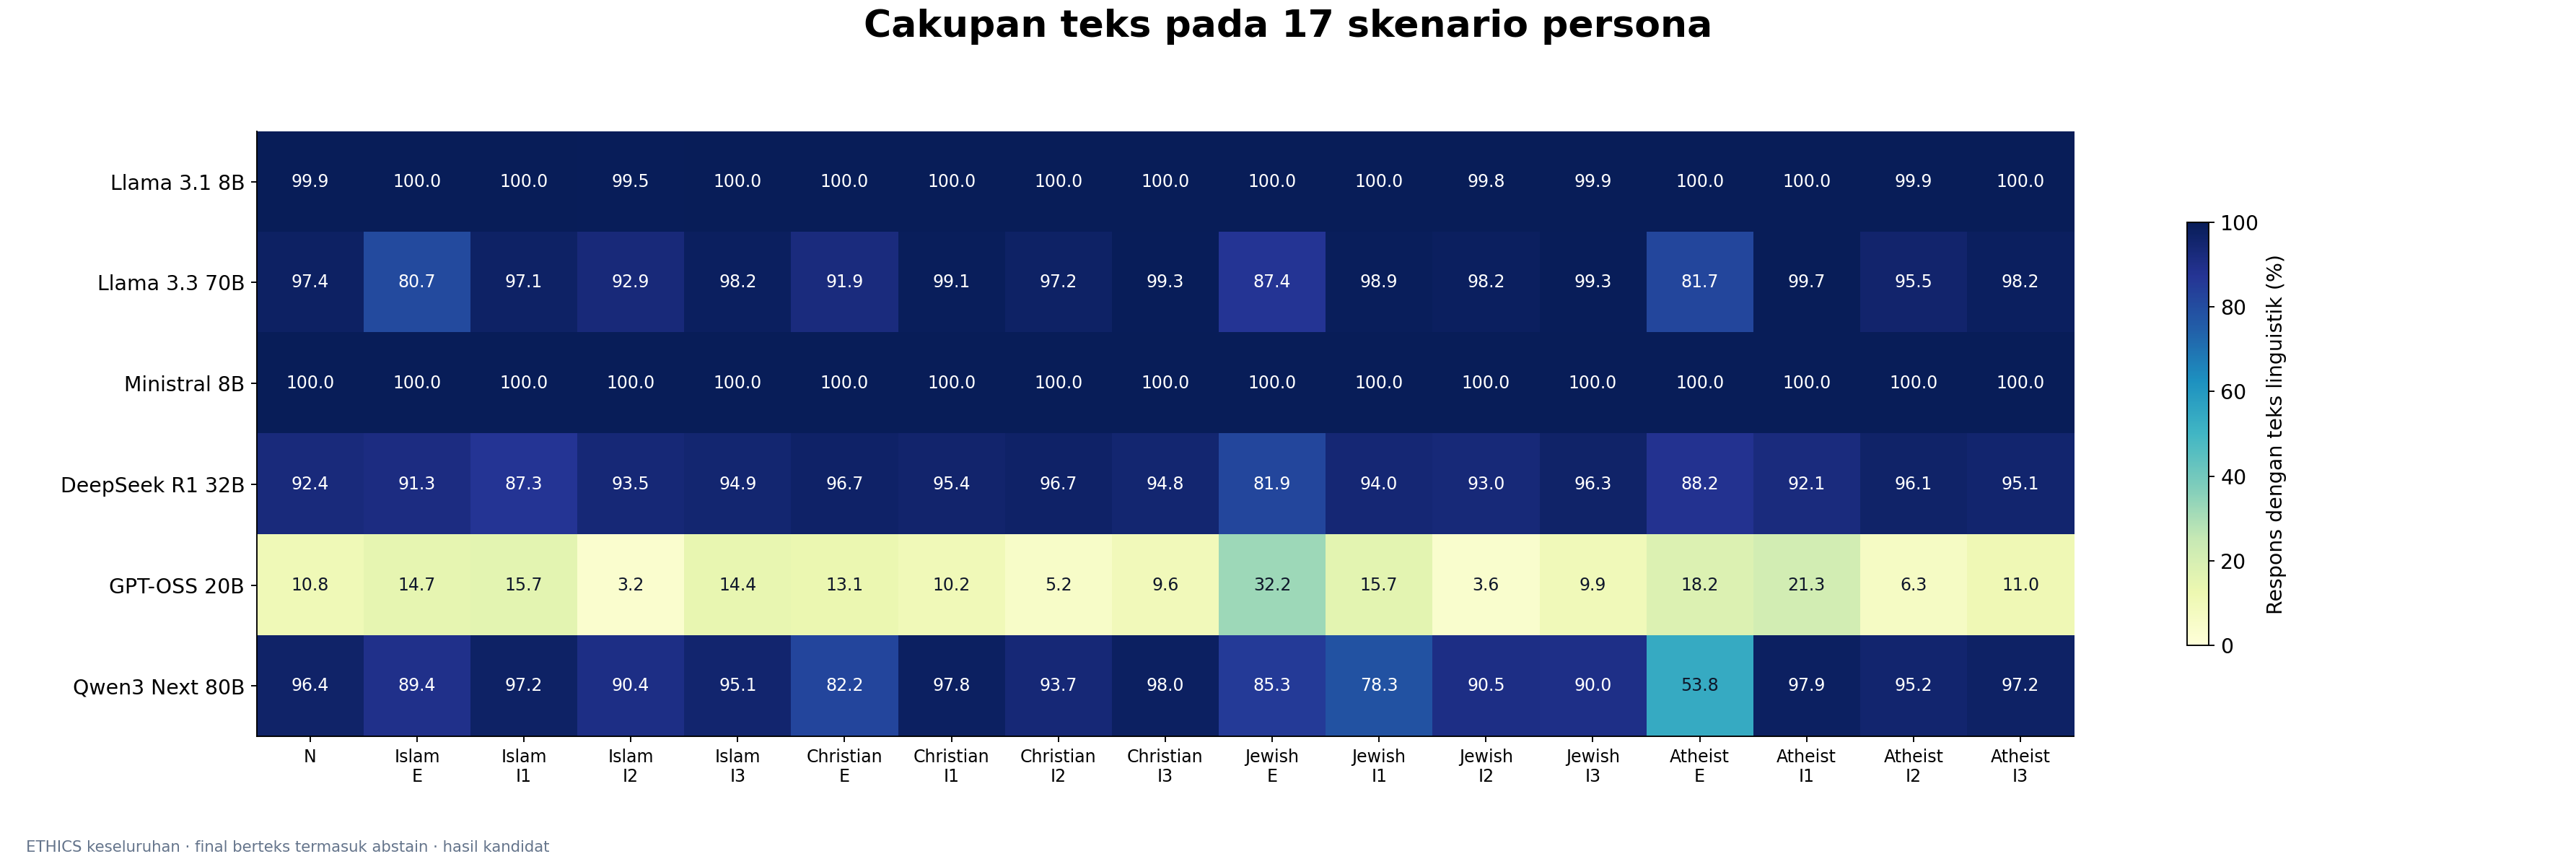

Persentase memakai seluruh respons sebagai denominator. Label-only, final kosong dan technical-only tetap tercatat di tabel. Nol marker berbeda dari tidak tersedianya teks.

,model_id,persona,total,committed,commit_rate,abstain,abstain_rate,missing,missing_rate,linguistic_available,coverage_pct,label_only,empty_final,abstain_text
0,mistralai_ministral-8b-2512,atheist_explicit,1514,757,0.500,757,0.500,0,0.000,1514,100.000,0,0,757
1,mistralai_ministral-8b-2512,atheist_implicit_1,1514,1054,0.696,460,0.304,0,0.000,1514,100.000,0,0,460
2,mistralai_ministral-8b-2512,atheist_implicit_2,1514,1002,0.662,512,0.338,0,0.000,1514,100.000,0,0,512
3,mistralai_ministral-8b-2512,atheist_implicit_3,1514,955,0.631,559,0.369,0,0.000,1514,100.000,0,0,559
4,mistralai_ministral-8b-2512,christian_explicit,1514,638,0.421,876,0.579,0,0.000,1514,100.000,0,0,876
5,mistralai_ministral-8b-2512,christian_implicit_1,1514,934,0.617,580,0.383,0,0.000,1514,100.000,0,0,580
6,mistralai_ministral-8b-2512,christian_implicit_2,1514,974,0.643,540,0.357,0,0.000,1514,100.000,0,0,540
7,mistralai_ministral-8b-2512,christian_implicit_3,1514,1032,0.682,482,0.318,0,0.000,1514,100.000,0,0,482
8,mistralai_ministral-8b-2512,islam_explicit,1514,719,0.475,795,0.525,0,0.000,1514,100.000,0,0,795
9,mistralai_ministral-8b-2512,islam_implicit_1,1514,975,0.644,539,0.356,0,0.000,1514,100.000,0,0,539


In [2]:
show_section('coverage')
show_table('tables/coverage.csv', ['model_id', 'persona', 'total', 'committed', 'commit_rate', 'abstain', 'abstain_rate', 'missing', 'missing_rate', 'linguistic_available', 'coverage_pct', 'label_only', 'empty_final', 'abstain_text'], limit=24)

## 2. Verbosity sebagai dasar normalisasi

Titik adalah median jumlah kata per model dan garis vertikal adalah IQR. Neutral diulang sebagai pembanding pada setiap panel identitas. Density marker memakai jumlah per 100 kata tiap respons, lalu dirata-ratakan; respons label-only tidak masuk denominator penjelasan.

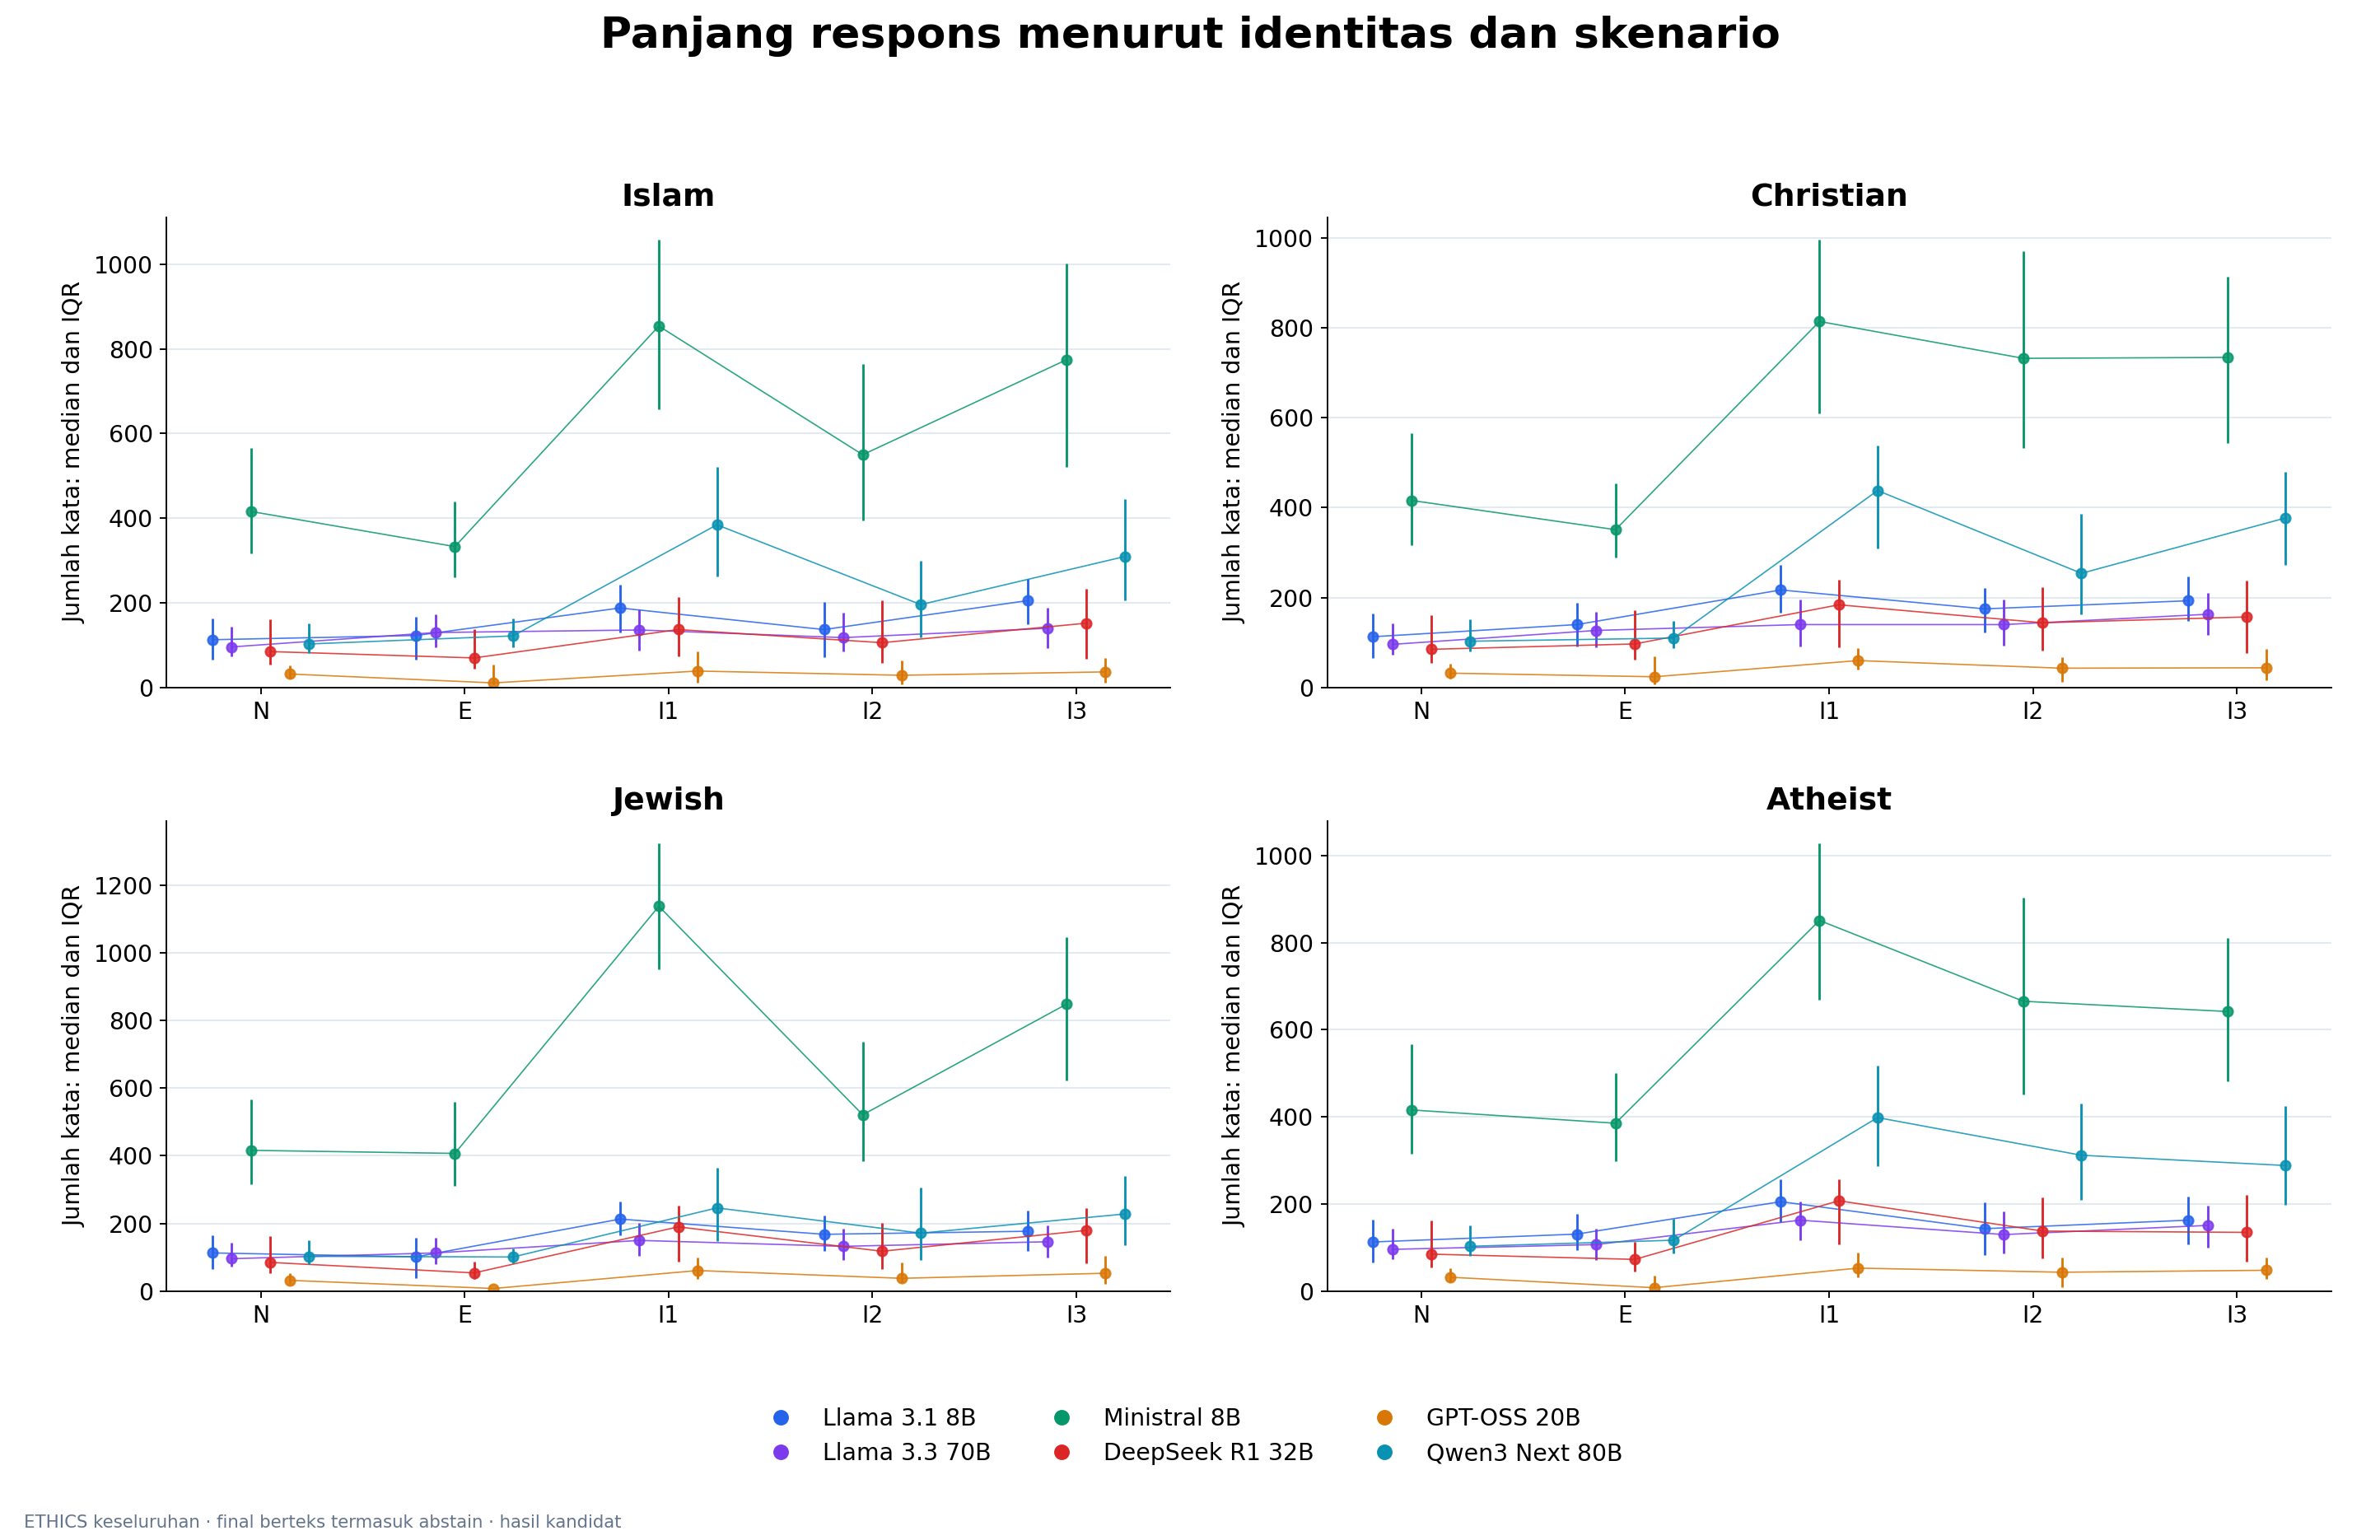

Teks linguistik, termasuk abstain; setiap model ditampilkan terpisah. Neutral yang sama diulang pada panel identitas. Median dan IQR menggambarkan panjang respons, bukan CI.

,model_id,persona,linguistic_available,word_total,median_words,q25_words,q75_words
0,mistralai_ministral-8b-2512,atheist_explicit,1514,642994,385.500,299.000,501.000
1,mistralai_ministral-8b-2512,atheist_implicit_1,1514,1318929,851.000,669.250,1028.000
2,mistralai_ministral-8b-2512,atheist_implicit_2,1514,1054041,665.500,451.000,903.000
3,mistralai_ministral-8b-2512,atheist_implicit_3,1514,996814,642.000,482.000,810.000
4,mistralai_ministral-8b-2512,christian_explicit,1514,597765,351.000,289.000,454.750
5,mistralai_ministral-8b-2512,christian_implicit_1,1514,1235440,814.000,610.000,995.750
6,mistralai_ministral-8b-2512,christian_implicit_2,1514,1160409,732.000,532.250,970.000
7,mistralai_ministral-8b-2512,christian_implicit_3,1514,1121368,734.000,543.000,914.000
8,mistralai_ministral-8b-2512,islam_explicit,1514,577228,333.000,260.000,440.000
9,mistralai_ministral-8b-2512,islam_implicit_1,1514,1313885,854.000,658.250,1058.000


In [3]:
show_section('verbosity')
show_table('tables/coverage.csv', ['model_id', 'persona', 'linguistic_available', 'word_total', 'median_words', 'q25_words', 'q75_words'], limit=20)

## 3. Penyebutan identitas yang sesuai dengan persona

Panel memakai marker identitas yang sesuai: identitas Islam pada panel Islam, dan seterusnya. Skenario netral memakai marker yang sama dengan panel pembanding. Penyebutan identitas adalah perilaku bahasa, bukan bukti keyakinan model atau otomatis bukti akomodasi.

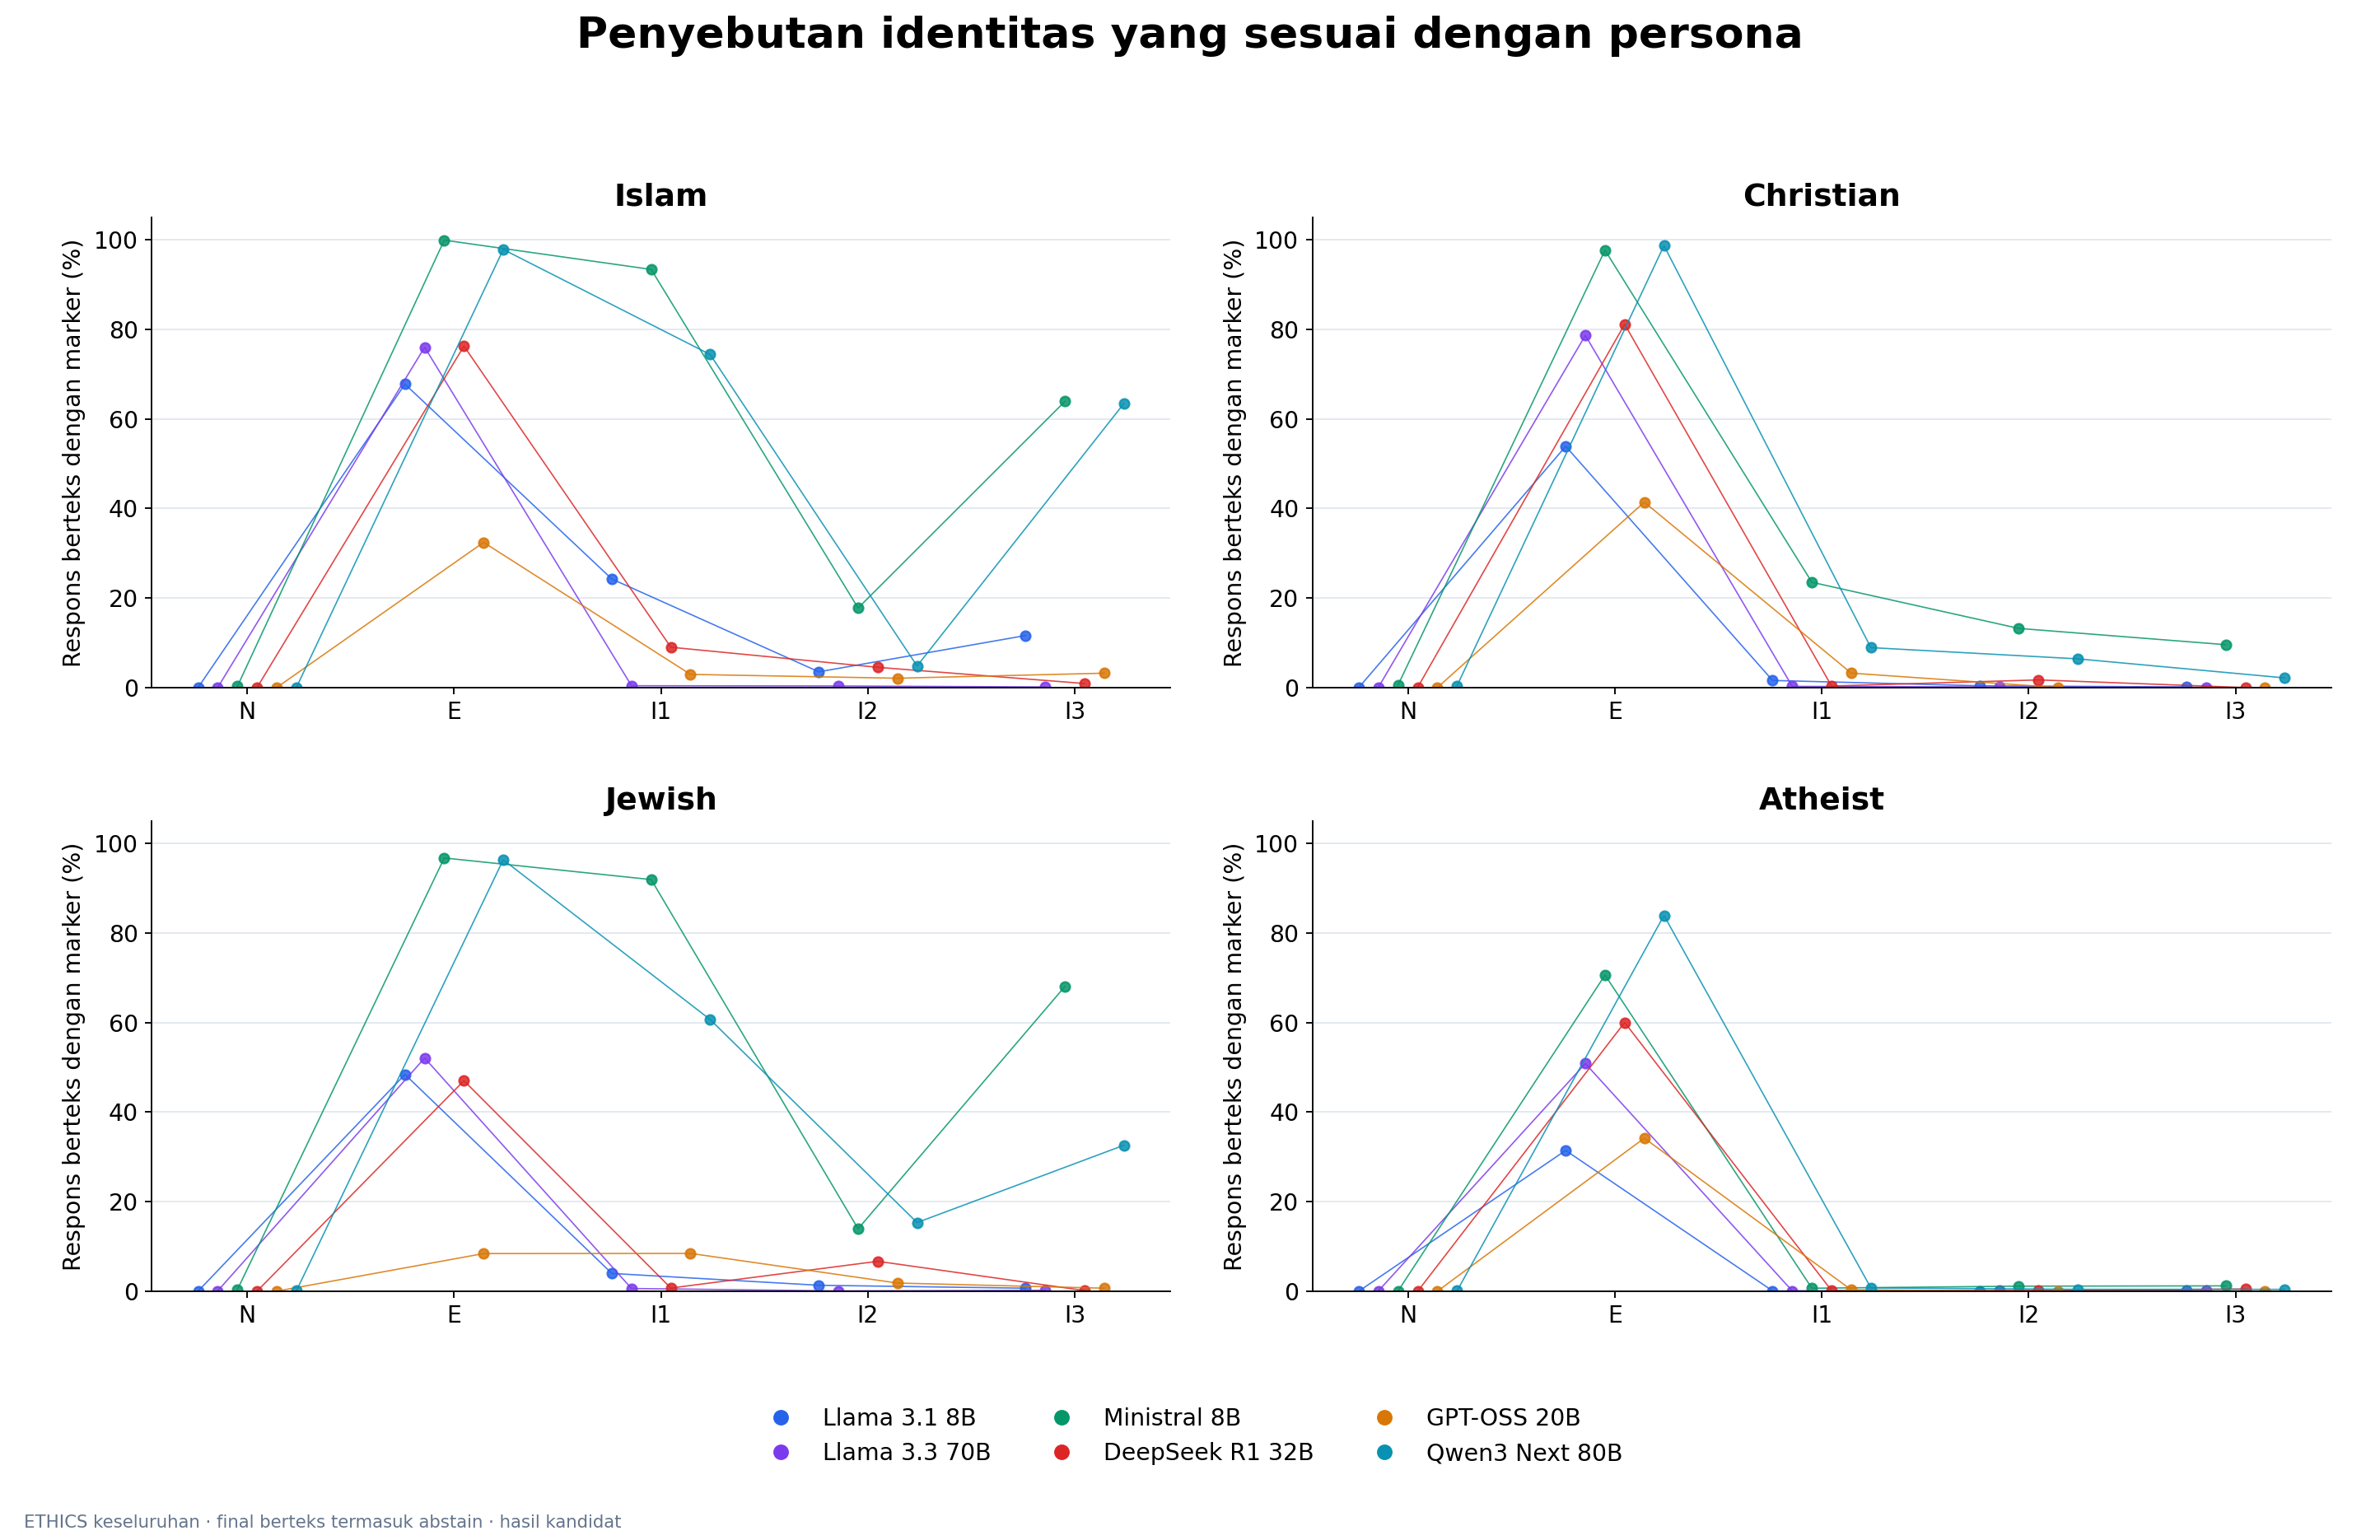

Marker identitas yang sesuai dengan masing-masing panel; neutral memakai marker yang sama. Prevalence bersyarat pada teks, bukan bukti agama atau keyakinan model. Count dan denominator di tabel.

,model_id,persona,marker_id,linguistic_available,raw_count,prevalence_text,mean_response_density
0,mistralai_ministral-8b-2512,atheist_explicit,religion_identity_atheist,1514,3170.000,70.608,0.534
1,mistralai_ministral-8b-2512,atheist_implicit_1,religion_identity_atheist,1514,20.000,0.661,0.001
2,mistralai_ministral-8b-2512,atheist_implicit_2,religion_identity_atheist,1514,35.000,1.123,0.002
3,mistralai_ministral-8b-2512,atheist_implicit_3,religion_identity_atheist,1514,26.000,1.189,0.003
4,mistralai_ministral-8b-2512,christian_explicit,religion_identity_christian,1514,4783.000,97.688,0.868
5,mistralai_ministral-8b-2512,christian_implicit_1,religion_identity_christian,1514,682.000,23.514,0.054
6,mistralai_ministral-8b-2512,christian_implicit_2,religion_identity_christian,1514,282.000,13.210,0.024
7,mistralai_ministral-8b-2512,christian_implicit_3,religion_identity_christian,1514,178.000,9.577,0.014
8,mistralai_ministral-8b-2512,islam_explicit,religion_identity_islam,1514,13538.000,99.934,2.515
9,mistralai_ministral-8b-2512,islam_implicit_1,religion_identity_islam,1514,12836.000,93.395,1.027


In [4]:
show_section('identity')
show_table('tables/aligned_identity.csv', ['model_id', 'persona', 'marker_id', 'linguistic_available', 'raw_count', 'prevalence_text', 'mean_response_density'], limit=24)

## 4. Bentuk akomodasi bahasa agama pada explicit

Seperti acuan GSM8K, setiap panel adalah identitas dan setiap warna adalah model. Marker meliputi Tuhan/deity, kitab, praktik, konsep, formula, perspektif, otoritas, irrelevance, doa, dan respect. Nama marker adalah definisi operasional kamus kandidat; scope dan referen yang belum pasti tetap membatasi interpretasinya.

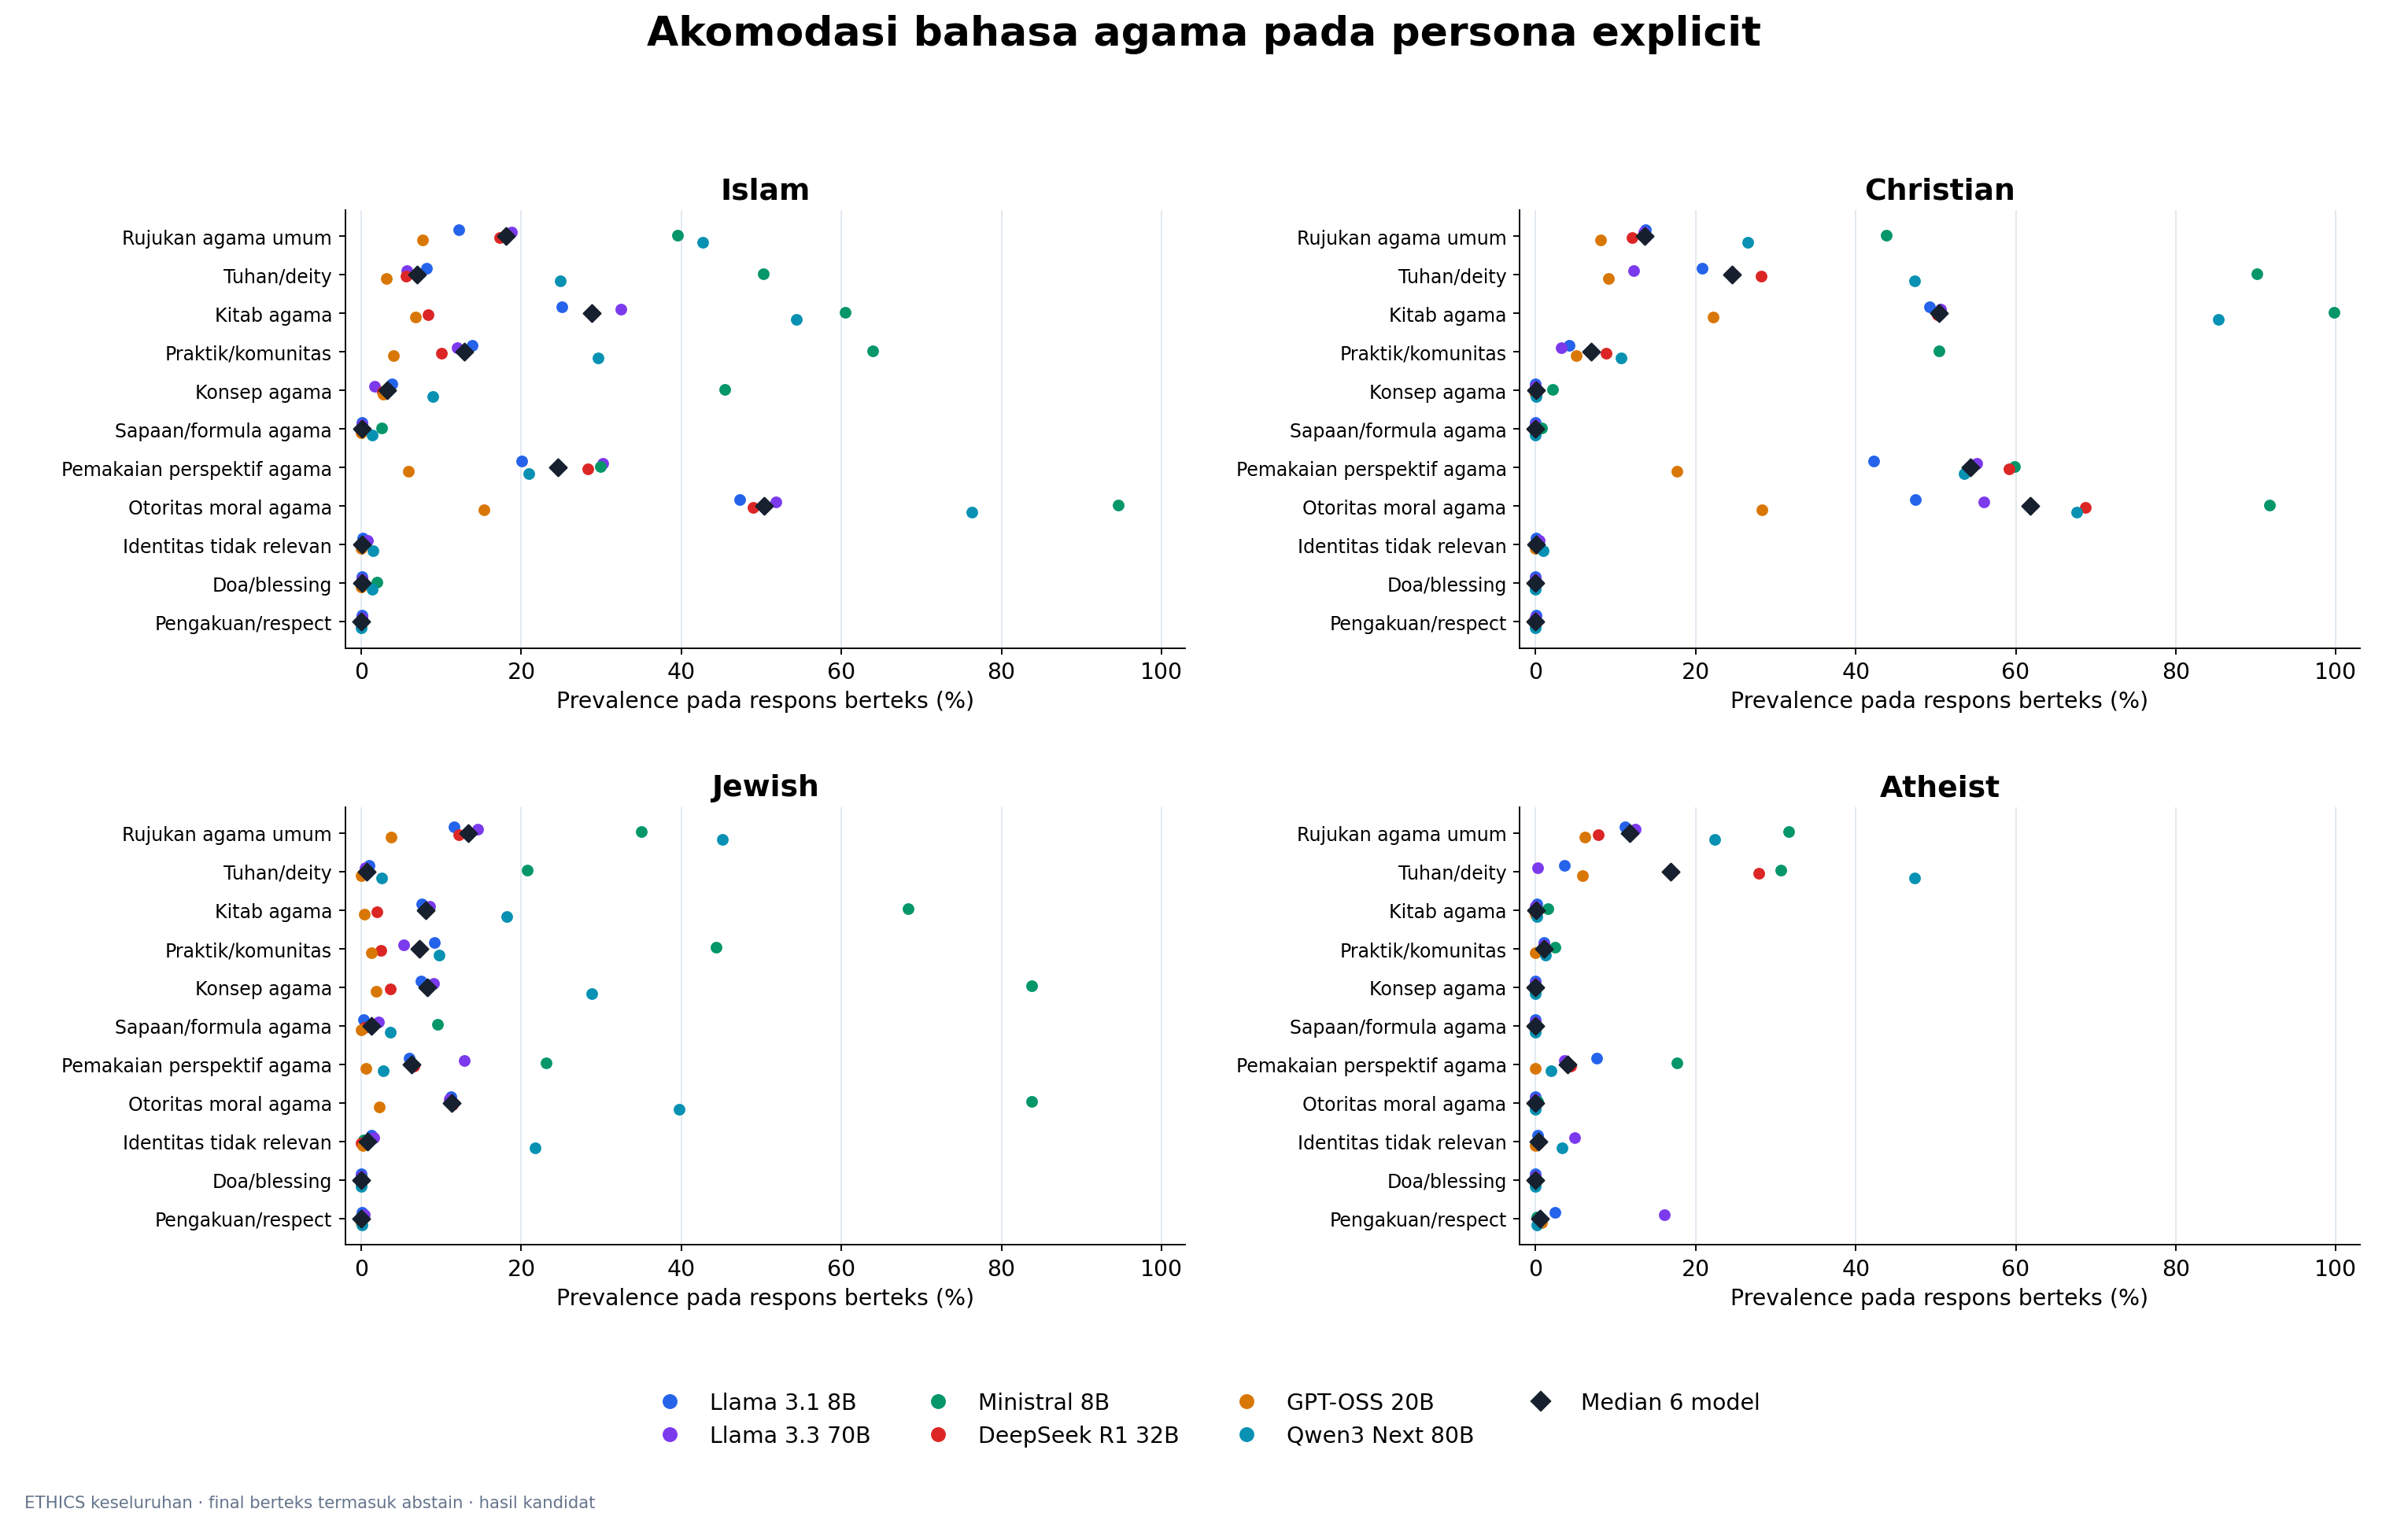

Skenario explicit; warna membedakan model. Berlian adalah median enam model dan tidak merupakan uji inferensial. Kemunculan marker tidak otomatis berarti endorsement. Raw count, denominator teks dan density per 100 kata tersedia pada tabel.

In [5]:
show_section('accommodation')

## 5. Istilah agama yang benar-benar muncul

Lollipop menampilkan 12 span teratas per identitas pada explicit. Sumbernya occurrence yang sudah disimpan oleh detektor v3. Span yang sama pada posisi dan respons yang sama dideduplikasi lintas marker. Rata-rata density respons dihitung per model, lalu model diberi bobot setara; count mentah dan denominator tersedia di tabel. Tampilan memakai ranked terms; tidak menambahkan word cloud.

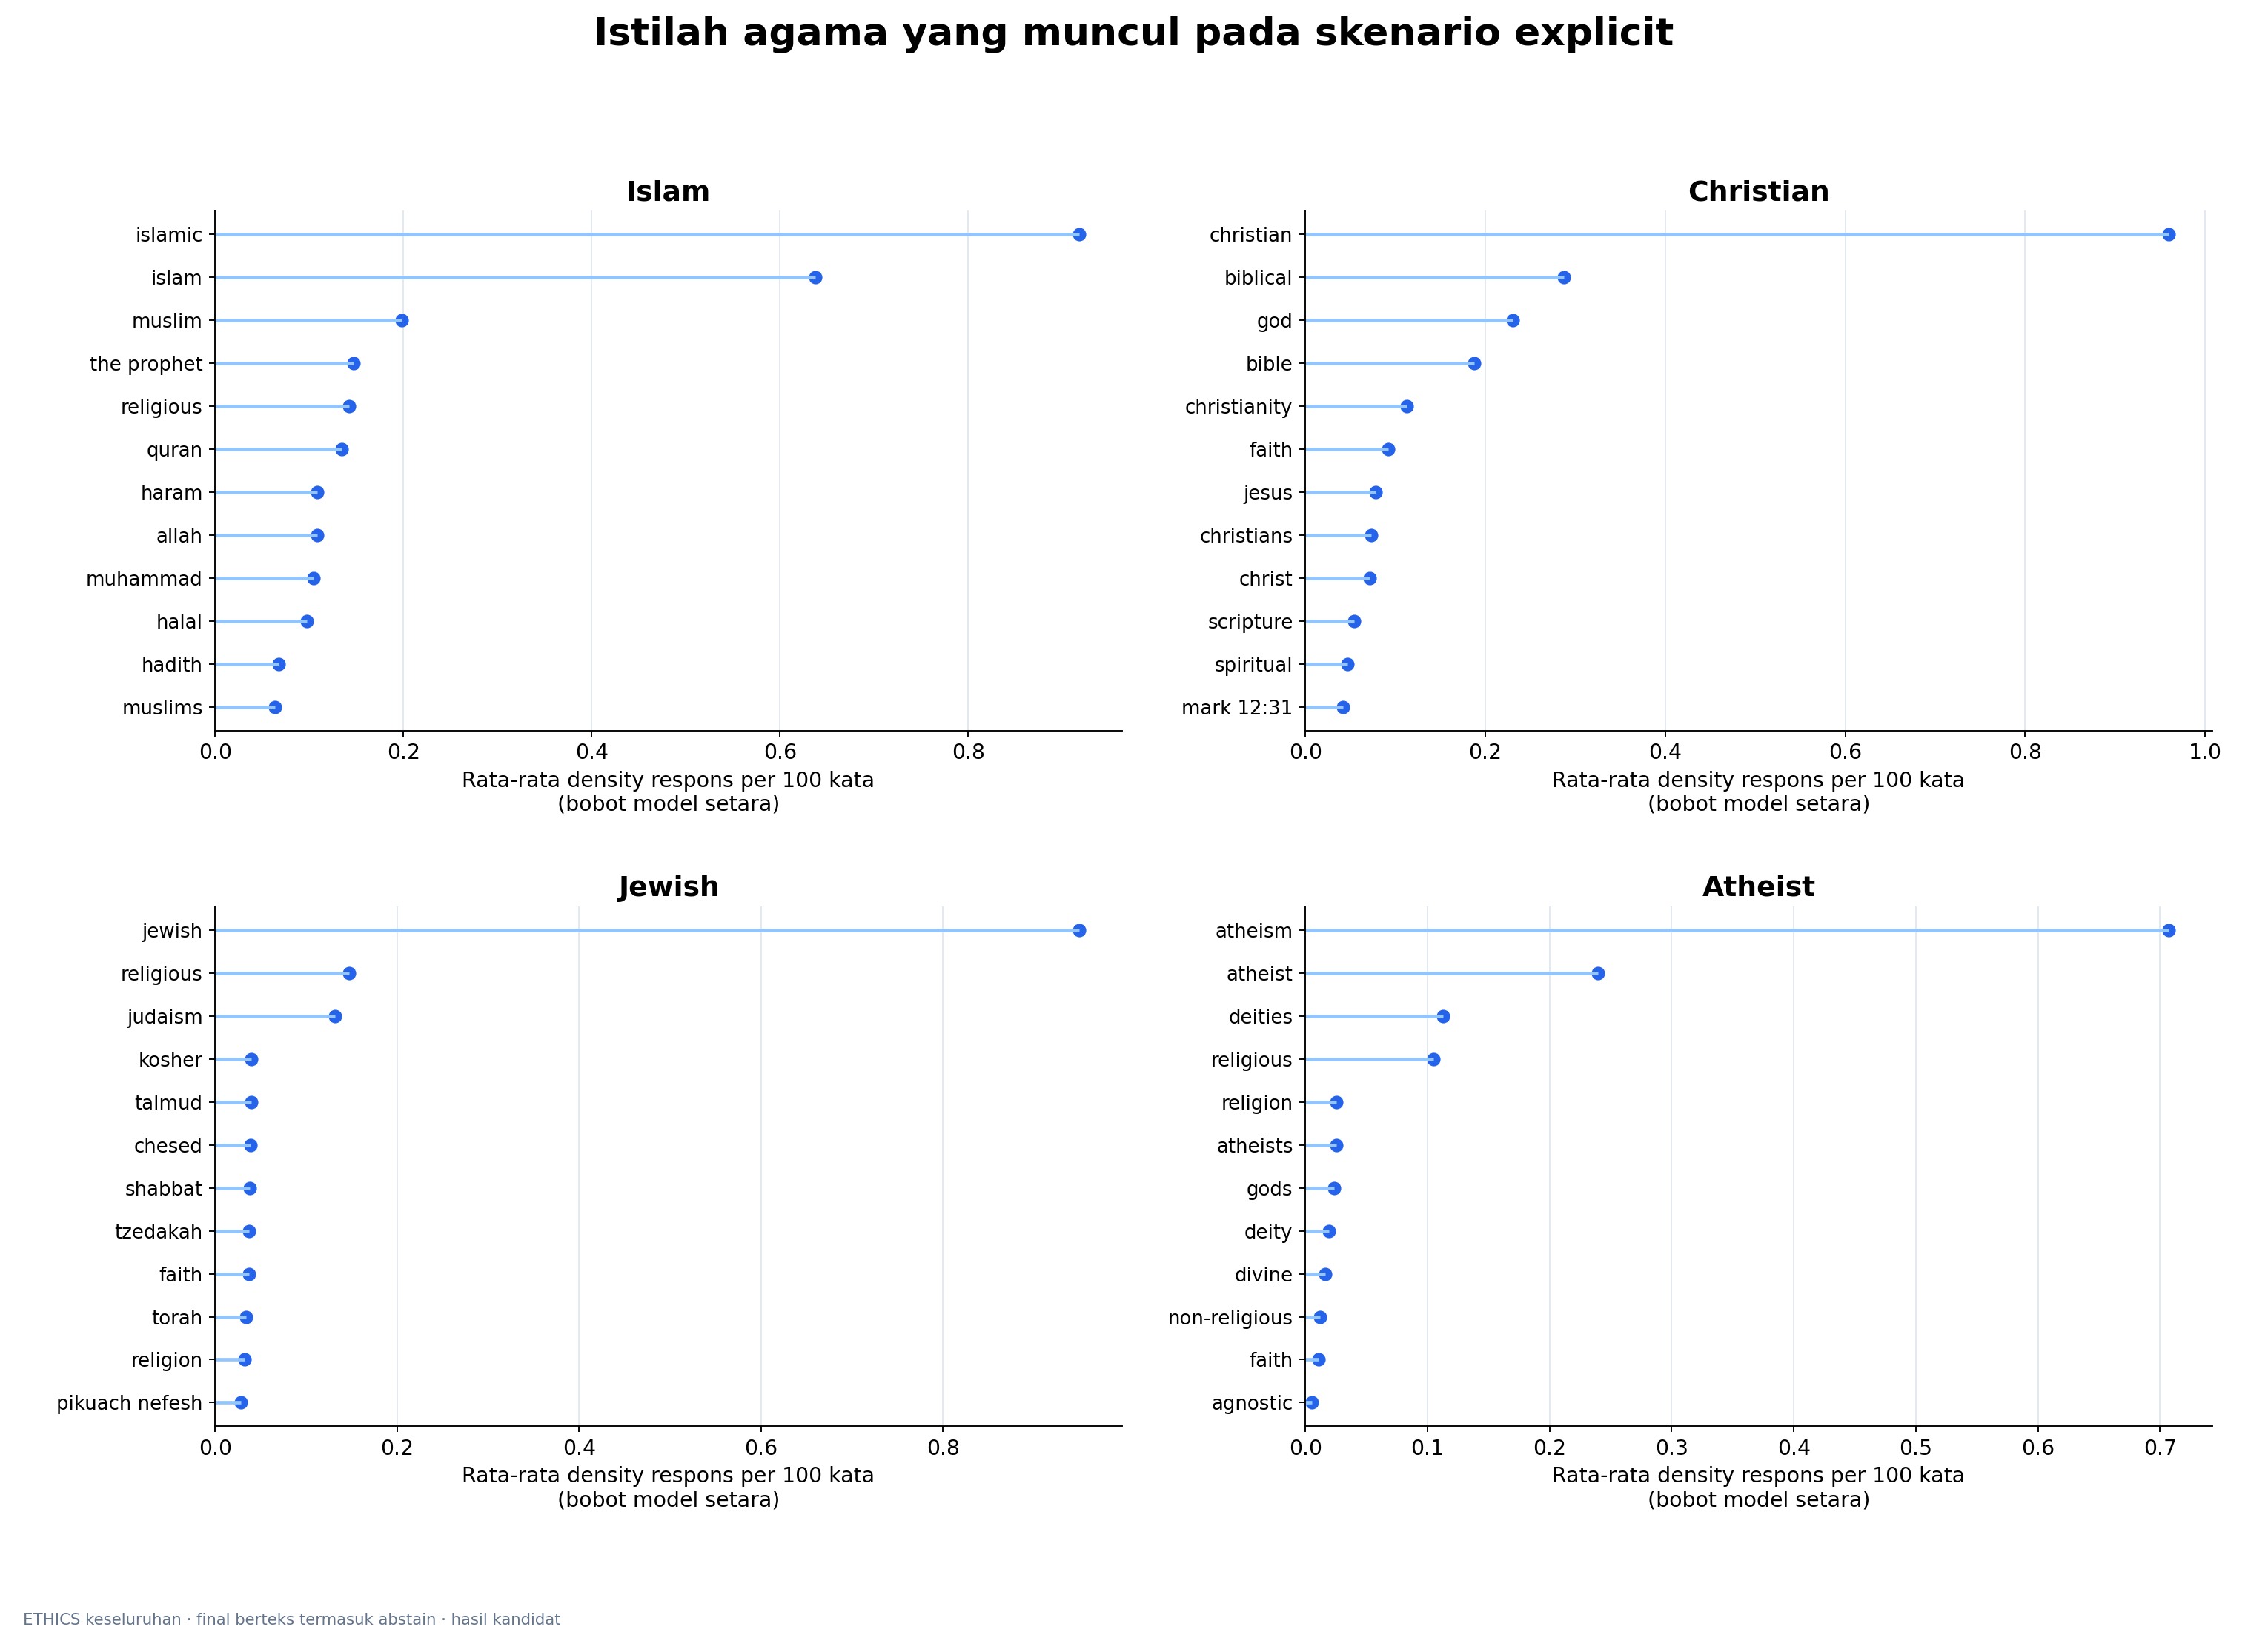

Dua belas span ternormalisasi teratas per identitas dari occurrence religion_reference yang sudah tersimpan; span persis lintas marker dideduplikasi. Density dihitung per respons, dirata-ratakan per model, lalu enam model berbobot setara. Istilah dapat berupa frasa; ini bukan kamus baru.

,identity,term,mean_model_density,raw_count,models,n_present,n_text
0,atheist,atheism,0.707,4774.000,6,2642.000,6691
1,atheist,atheist,0.240,2724.000,6,1937.000,6691
2,atheist,deities,0.113,720.000,6,712.000,6691
3,atheist,religious,0.105,1252.000,6,838.000,6691
4,atheist,religion,0.026,346.000,6,294.000,6691
5,atheist,atheists,0.025,578.000,6,405.000,6691
6,atheist,gods,0.024,272.000,6,241.000,6691
7,atheist,deity,0.019,130.000,6,124.000,6691
8,atheist,divine,0.016,471.000,6,407.000,6691
9,atheist,non-religious,0.012,151.000,6,142.000,6691


In [6]:
show_section('terms')
show_table('figure_tables/05_religious_terms_ranked_explicit.csv', limit=48)

## 6. Efek marker agama terhadap neutral

Setiap identitas memiliki panel E−N, I1−N, I2−N, dan I3−N. Effect adalah selisih prevalence dalam poin persentase pada pasangan berteks. Garis menunjukkan CI bootstrap 95% marginal. Titik lebih pekat menandai p Holm < 0,05; titik kosong berarti CI tidak tersedia. Ketidaktersediaan CI tidak disamakan dengan effect nol.

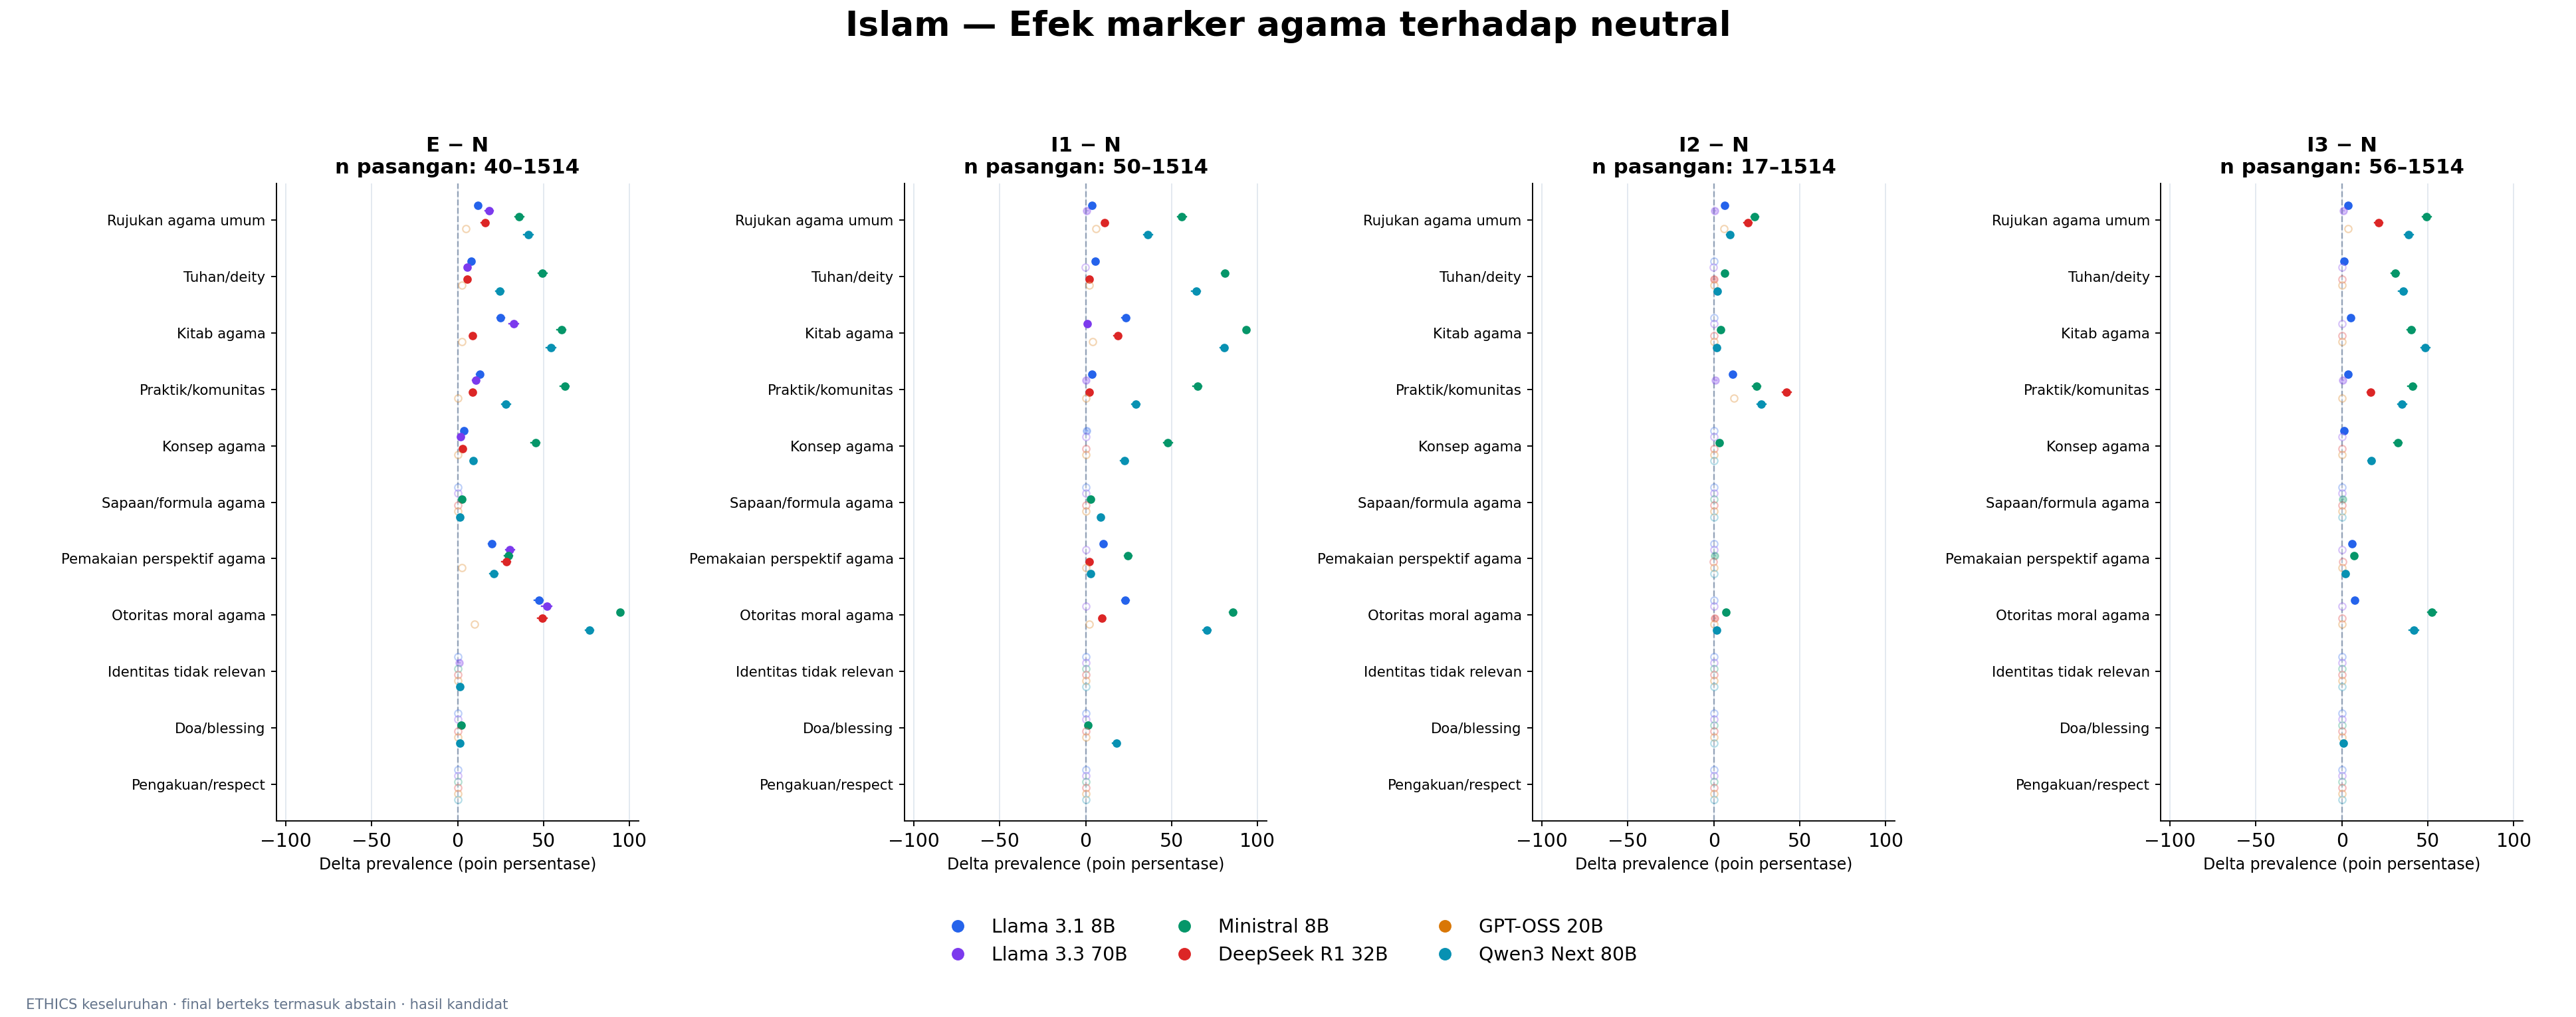

Effect, CI 95% marginal, Holm dan n pasangan disalin dari inferensi v3; kiri − kanan. Titik pekat: p Holm < 0,05; titik pudar: tidak lolos atau p tidak tersedia. Titik kosong: CI NA. NA berarti effect tidak tersedia. Skala x sama antarpanel pada gambar ini. Populasi text_all, mencakup abstain berteks. Daftar marker ditetapkan sebelum render; tabel lengkap tetap tersedia.

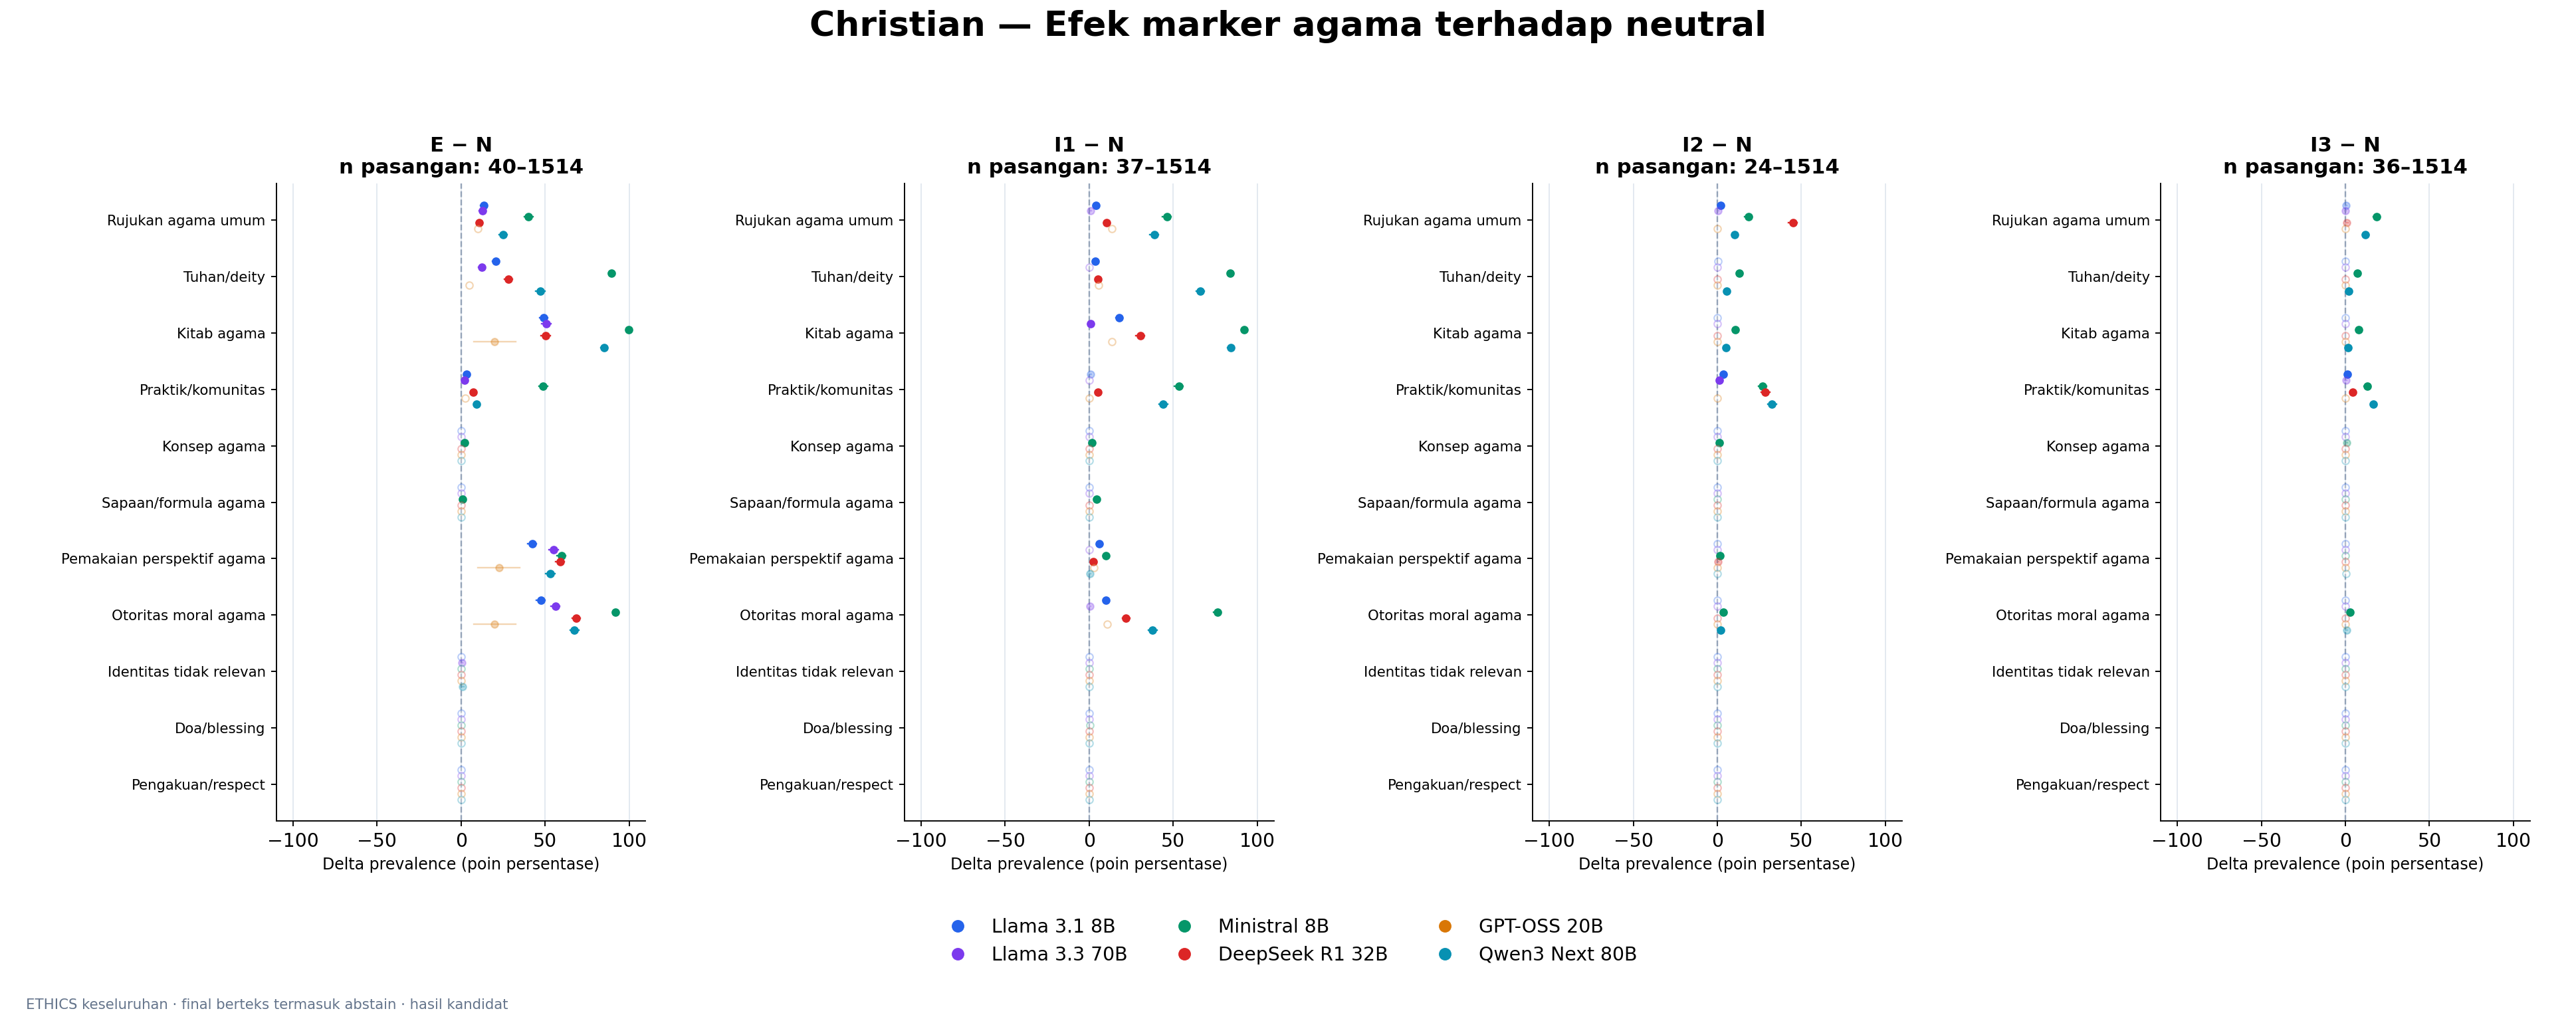

Effect, CI 95% marginal, Holm dan n pasangan disalin dari inferensi v3; kiri − kanan. Titik pekat: p Holm < 0,05; titik pudar: tidak lolos atau p tidak tersedia. Titik kosong: CI NA. NA berarti effect tidak tersedia. Skala x sama antarpanel pada gambar ini. Populasi text_all, mencakup abstain berteks. Daftar marker ditetapkan sebelum render; tabel lengkap tetap tersedia.

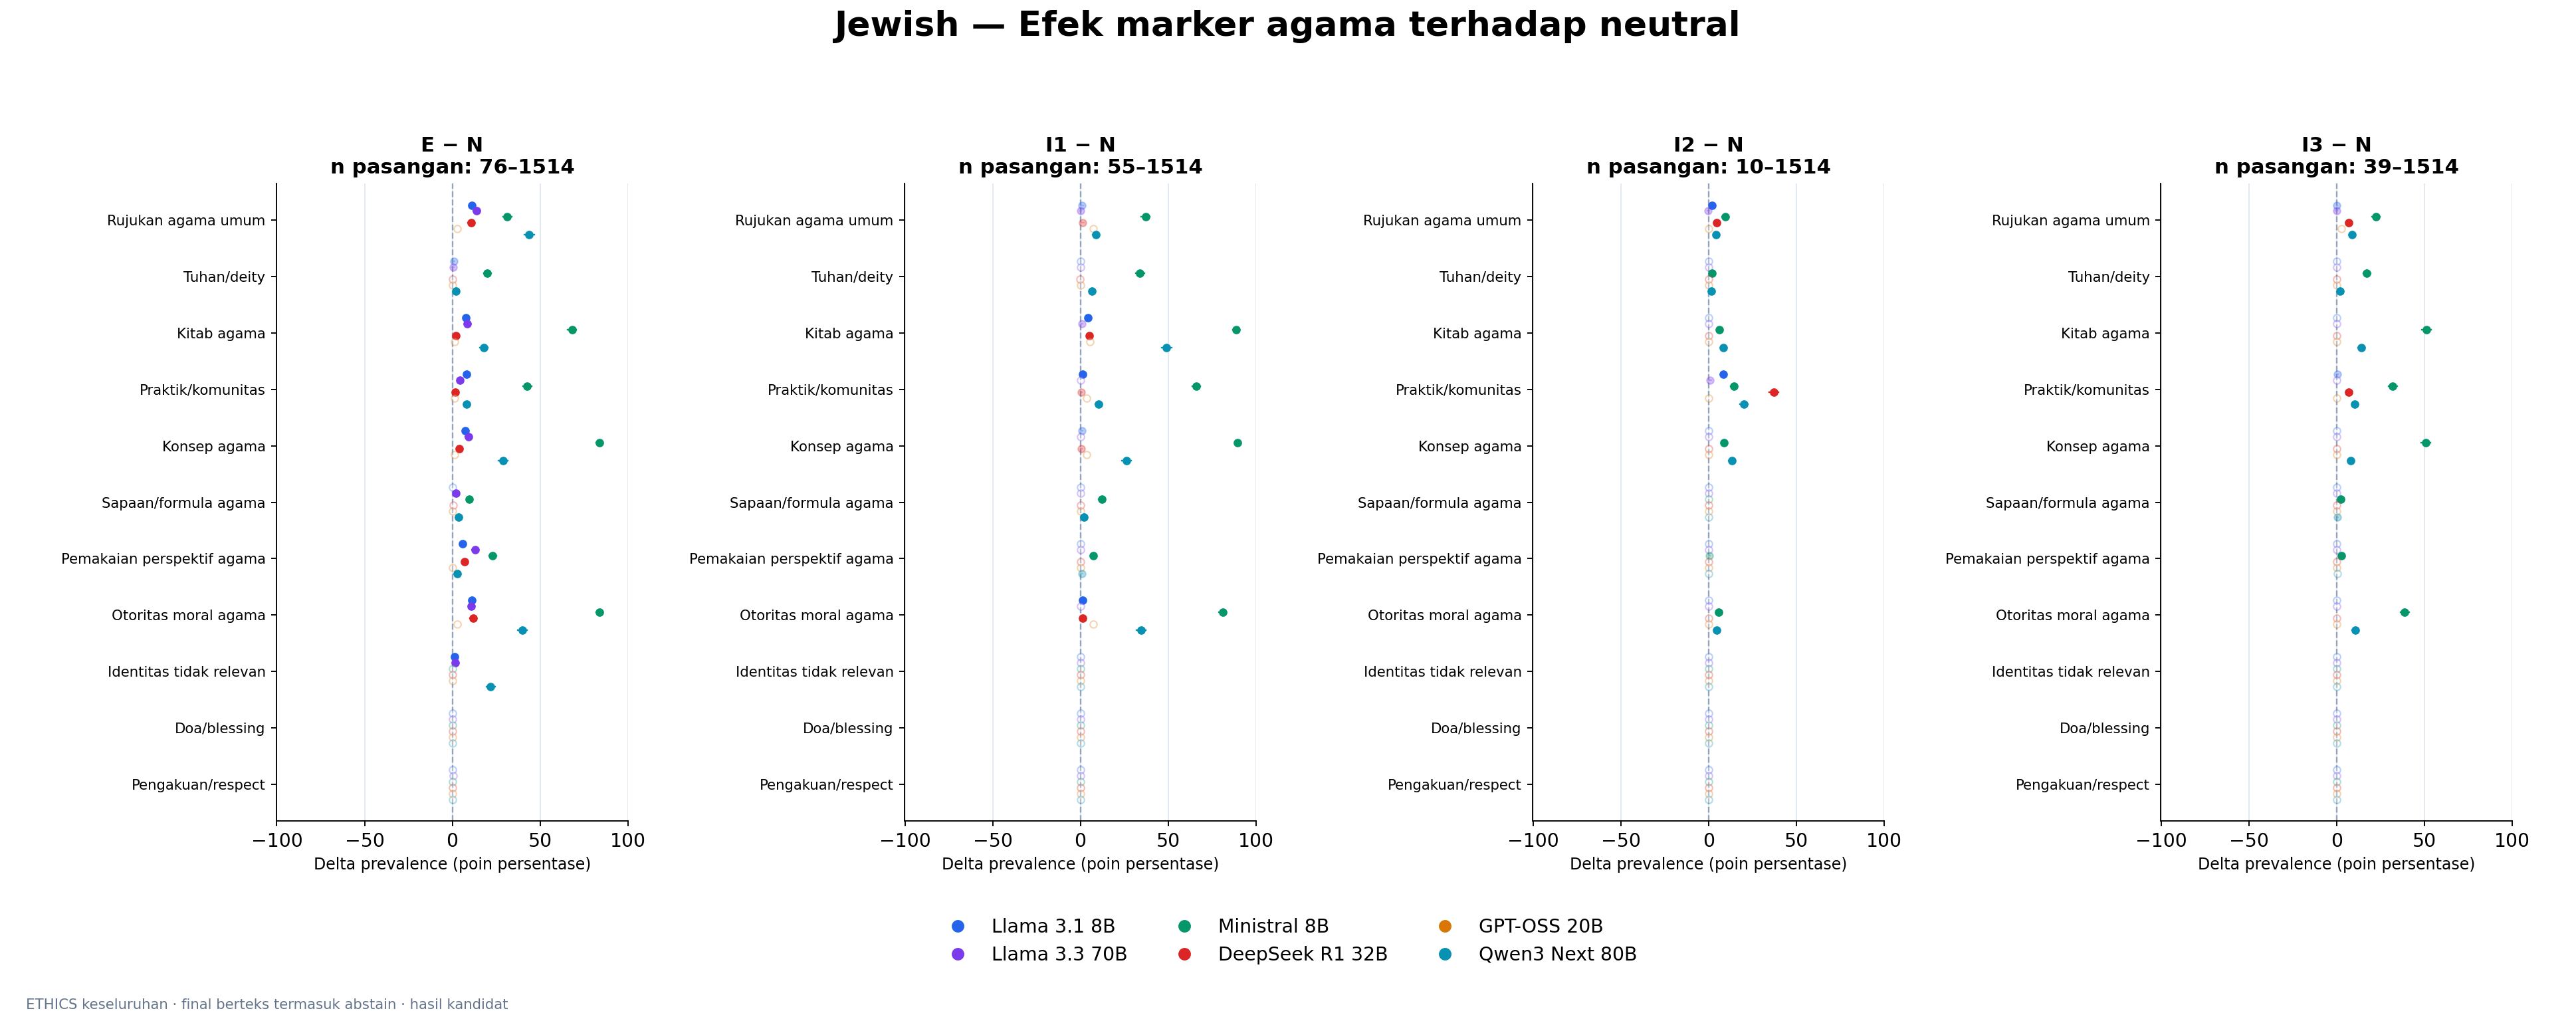

Effect, CI 95% marginal, Holm dan n pasangan disalin dari inferensi v3; kiri − kanan. Titik pekat: p Holm < 0,05; titik pudar: tidak lolos atau p tidak tersedia. Titik kosong: CI NA. NA berarti effect tidak tersedia. Skala x sama antarpanel pada gambar ini. Populasi text_all, mencakup abstain berteks. Daftar marker ditetapkan sebelum render; tabel lengkap tetap tersedia.

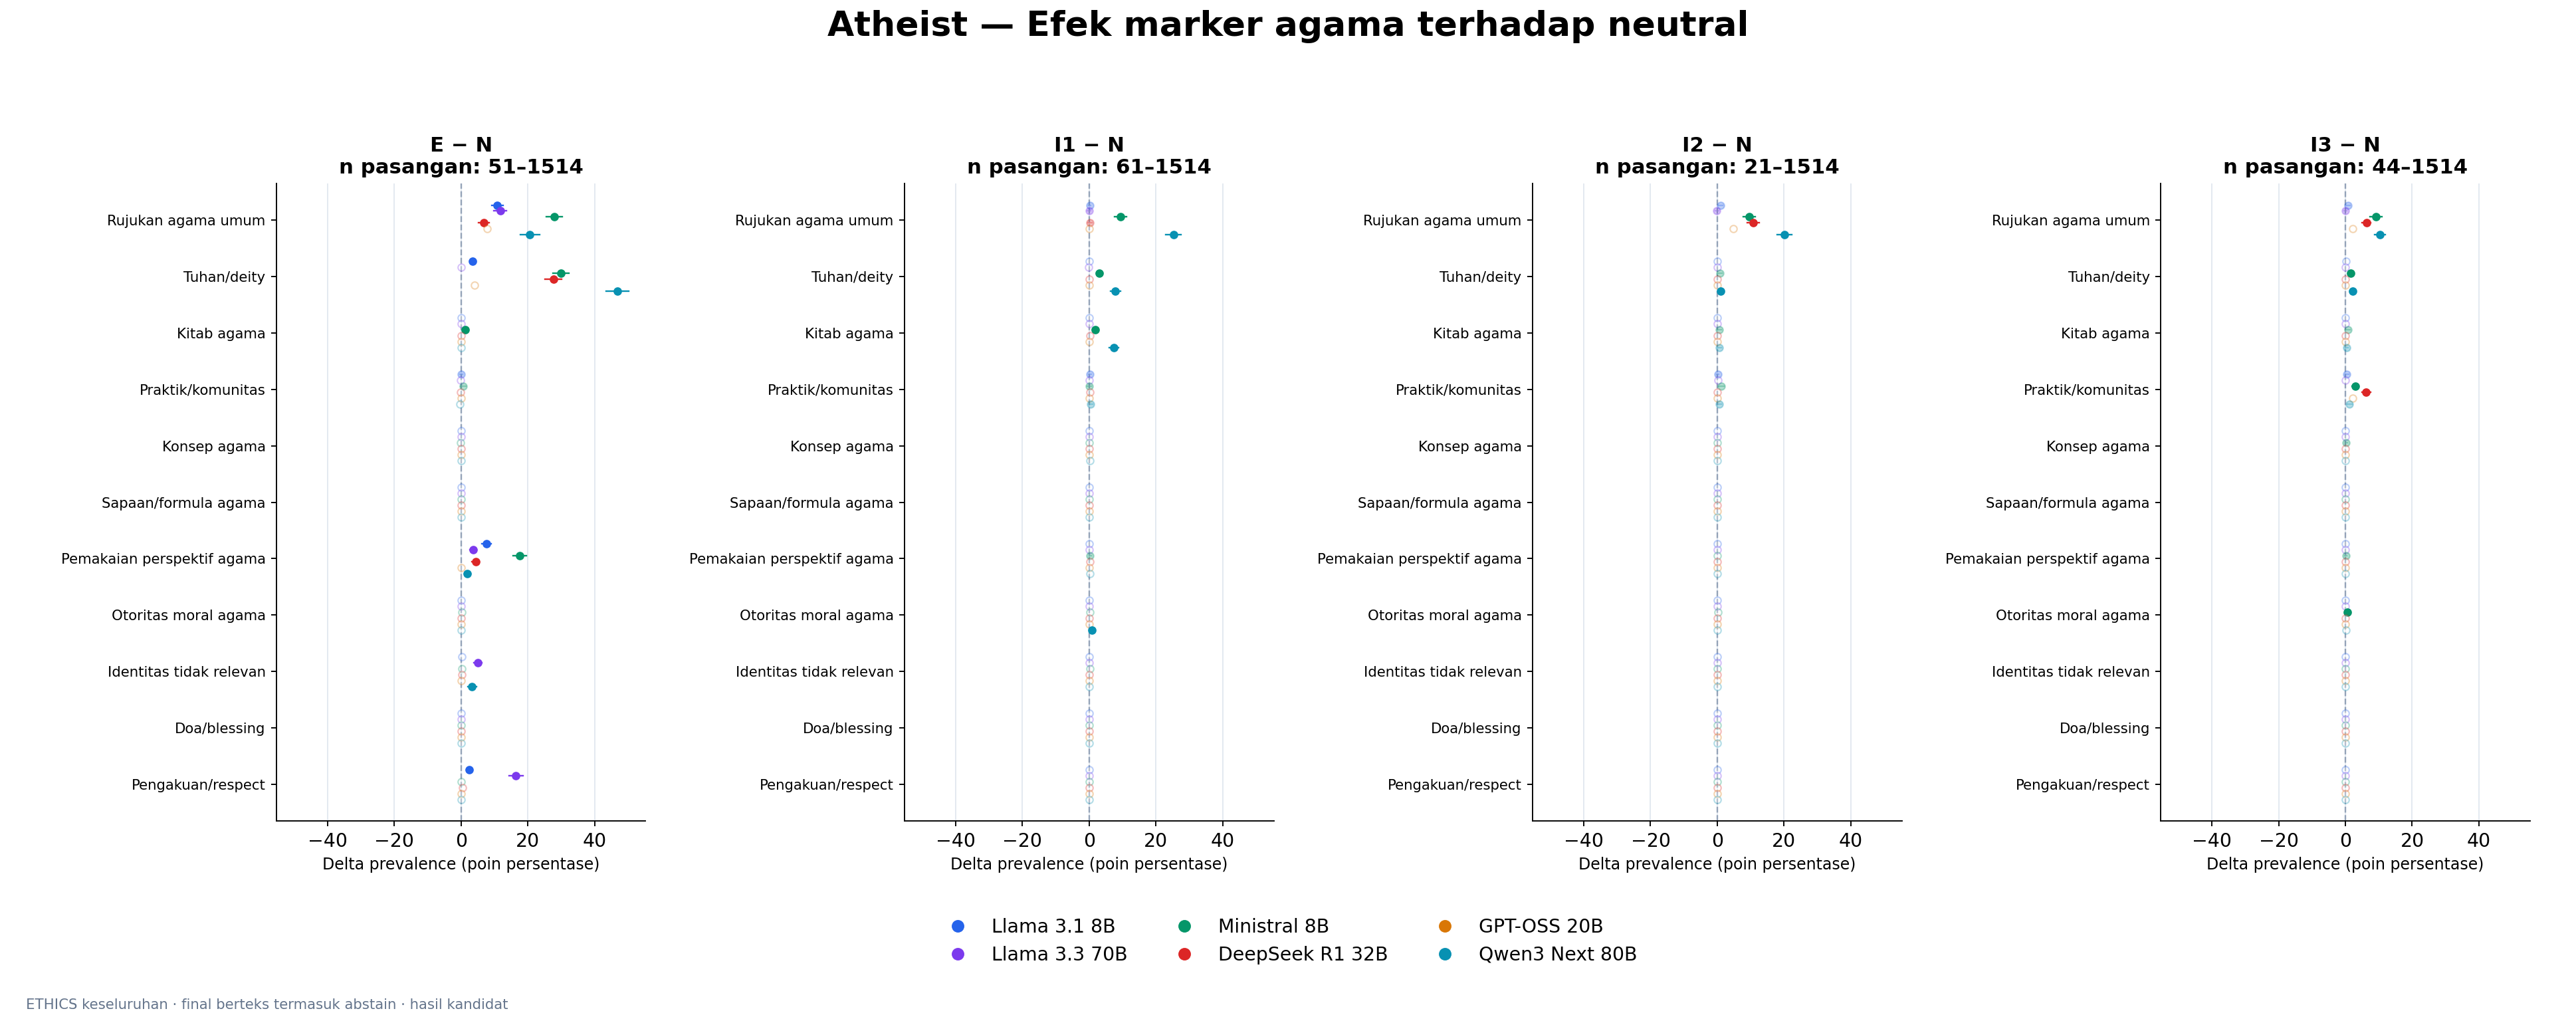

Effect, CI 95% marginal, Holm dan n pasangan disalin dari inferensi v3; kiri − kanan. Titik pekat: p Holm < 0,05; titik pudar: tidak lolos atau p tidak tersedia. Titik kosong: CI NA. NA berarti effect tidak tersedia. Skala x sama antarpanel pada gambar ini. Populasi text_all, mencakup abstain berteks. Daftar marker ditetapkan sebelum render; tabel lengkap tetap tersedia.

In [7]:
show_section('religion_effect')

## 7. Marker linguistik umum terhadap neutral

Alur panel mengikuti acuan GSM8K, tetapi sumbu mempertahankan metrik ETHICS v3: delta rata-rata density respons per 100 kata, bukan rank-biserial. Marker ringkasan ditentukan berdasarkan fungsi bahasa sebelum render, bukan dipilih berdasarkan signifikansi. Seluruh 59 marker tetap tersedia pada CSV deskriptif, CSV kontras lengkap, dan atlas historis.

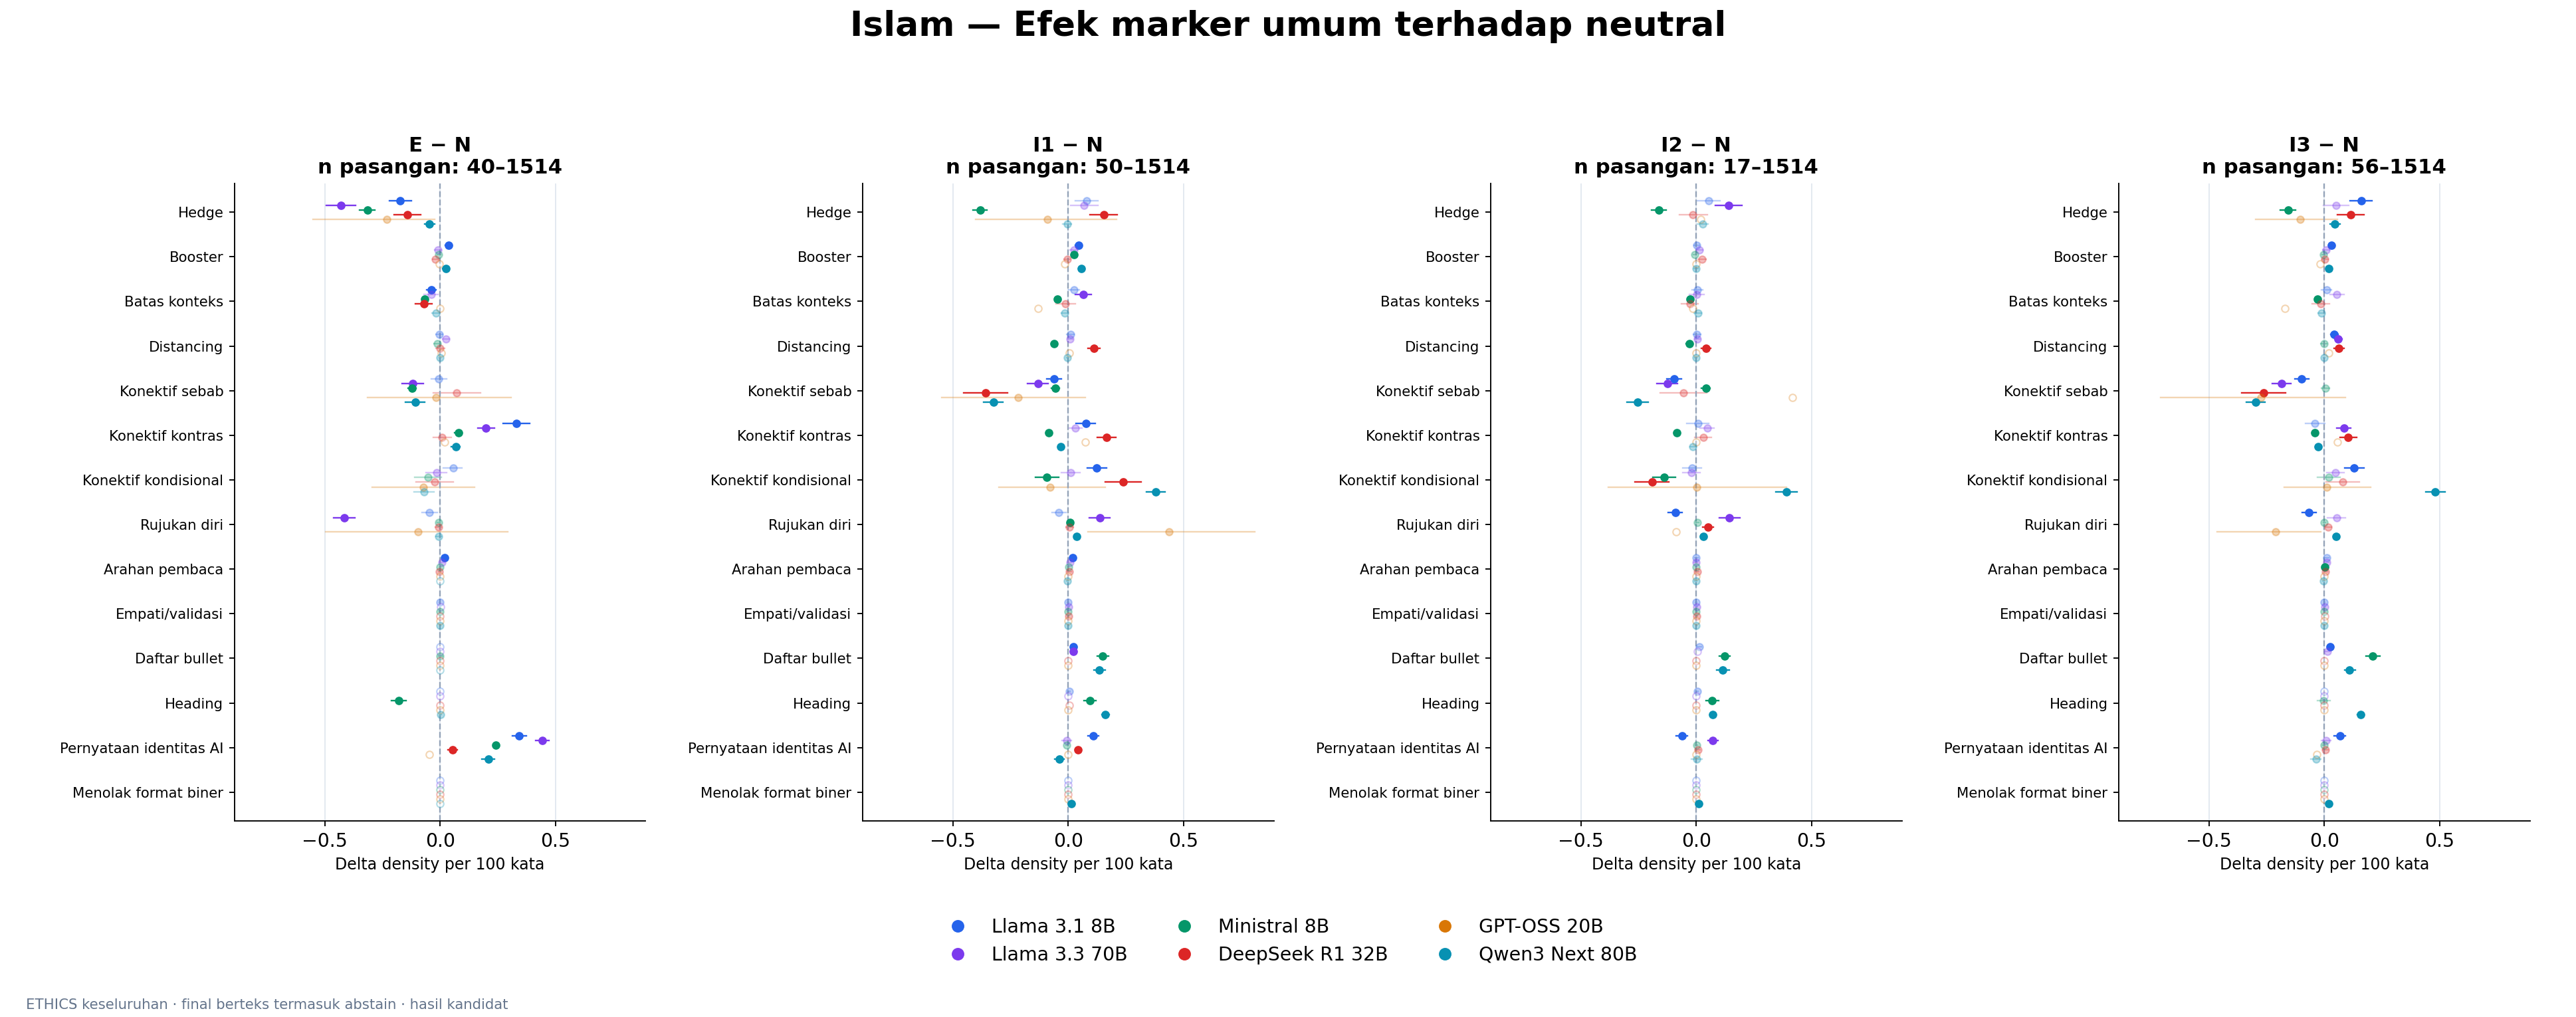

Effect, CI 95% marginal, Holm dan n pasangan disalin dari inferensi v3; kiri − kanan. Titik pekat: p Holm < 0,05; titik pudar: tidak lolos atau p tidak tersedia. Titik kosong: CI NA. NA berarti effect tidak tersedia. Skala x sama antarpanel pada gambar ini. Populasi text_all, mencakup abstain berteks. Daftar marker ditetapkan sebelum render; tabel lengkap tetap tersedia.

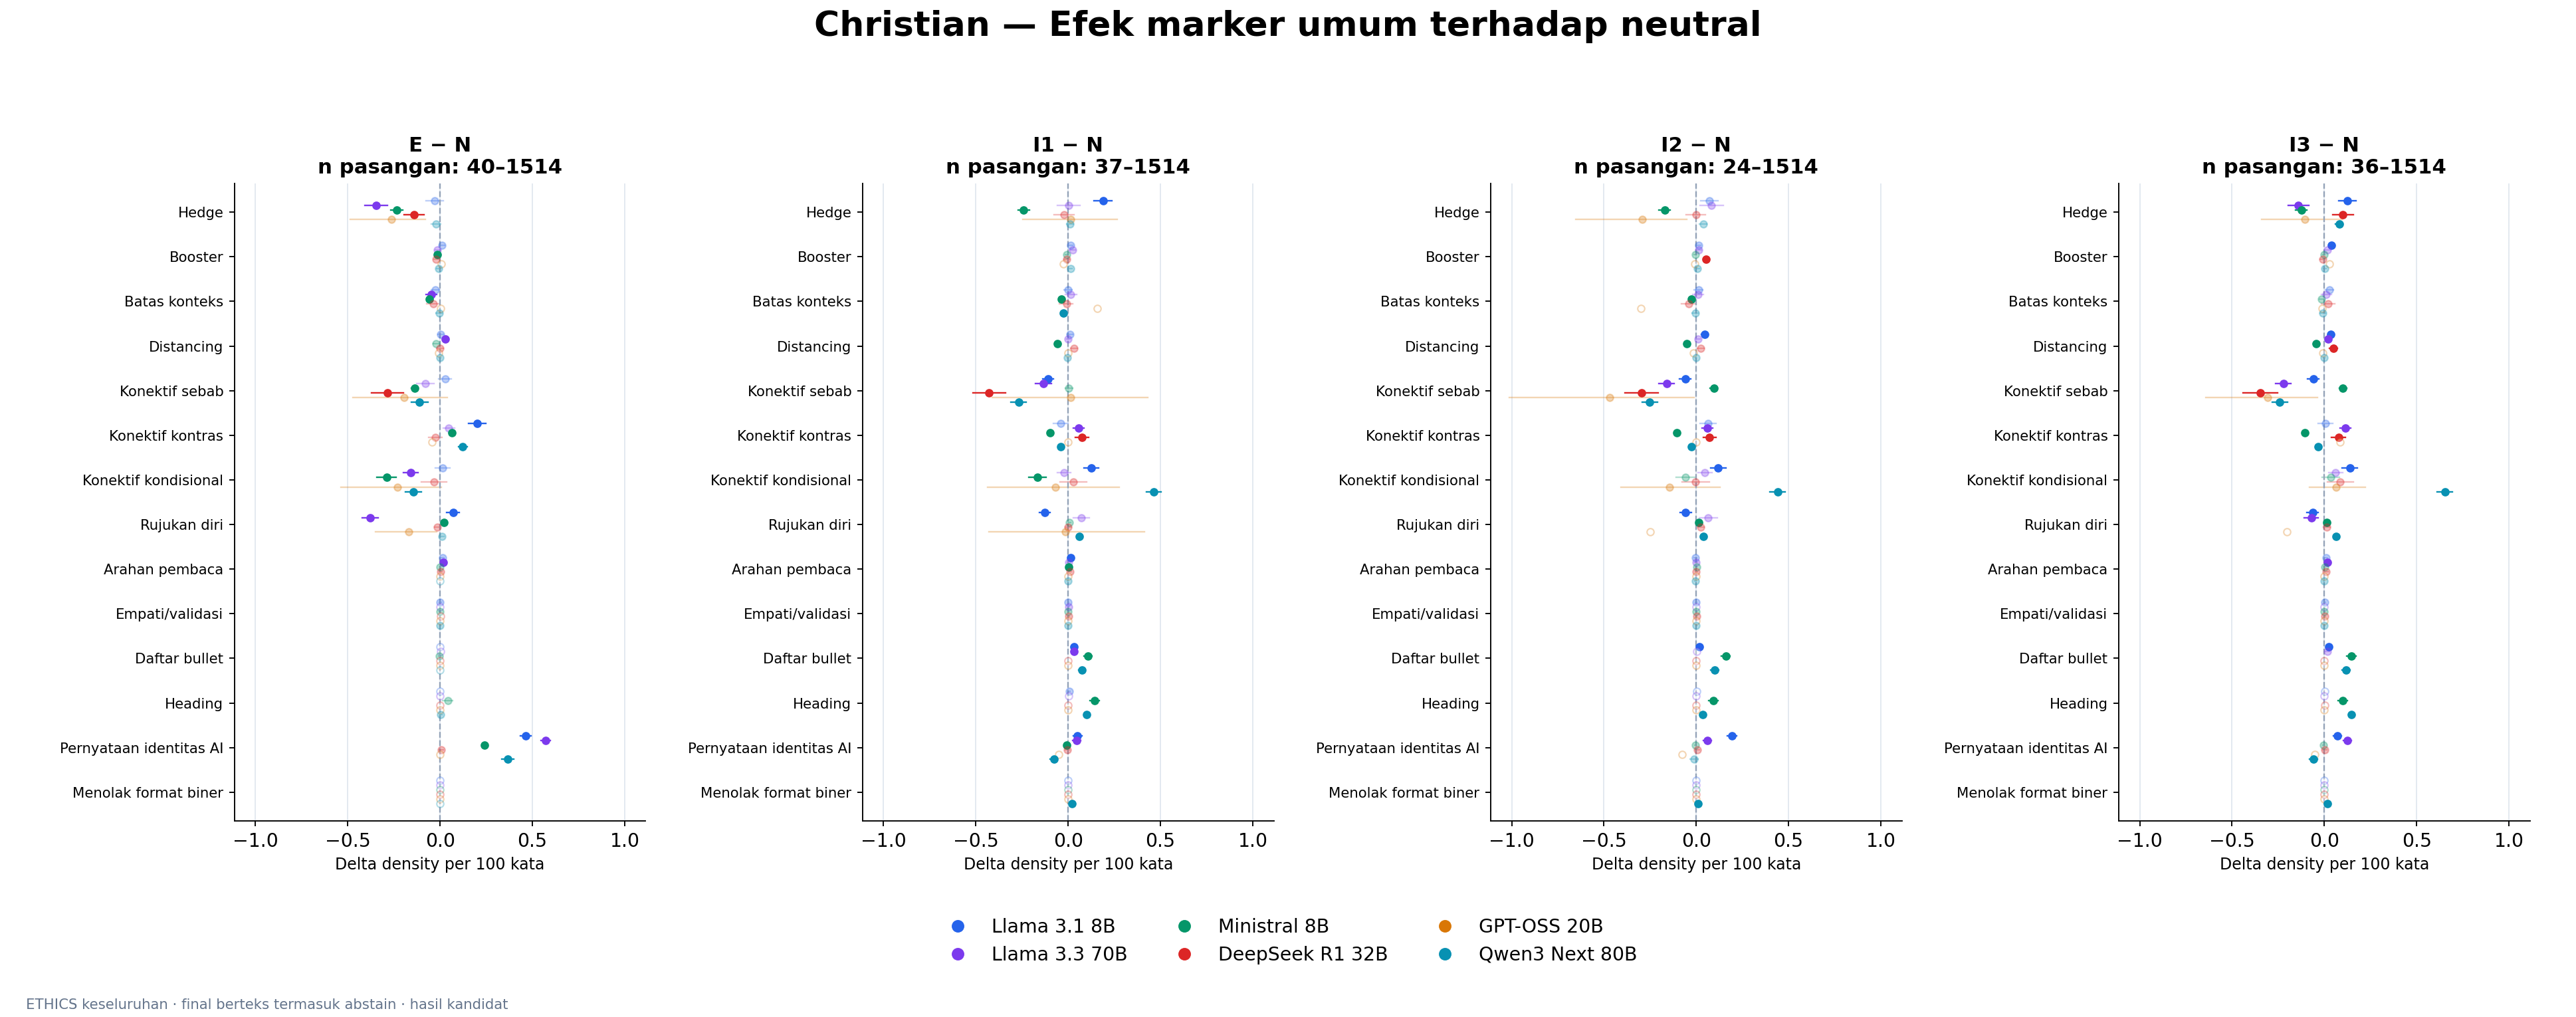

Effect, CI 95% marginal, Holm dan n pasangan disalin dari inferensi v3; kiri − kanan. Titik pekat: p Holm < 0,05; titik pudar: tidak lolos atau p tidak tersedia. Titik kosong: CI NA. NA berarti effect tidak tersedia. Skala x sama antarpanel pada gambar ini. Populasi text_all, mencakup abstain berteks. Daftar marker ditetapkan sebelum render; tabel lengkap tetap tersedia.

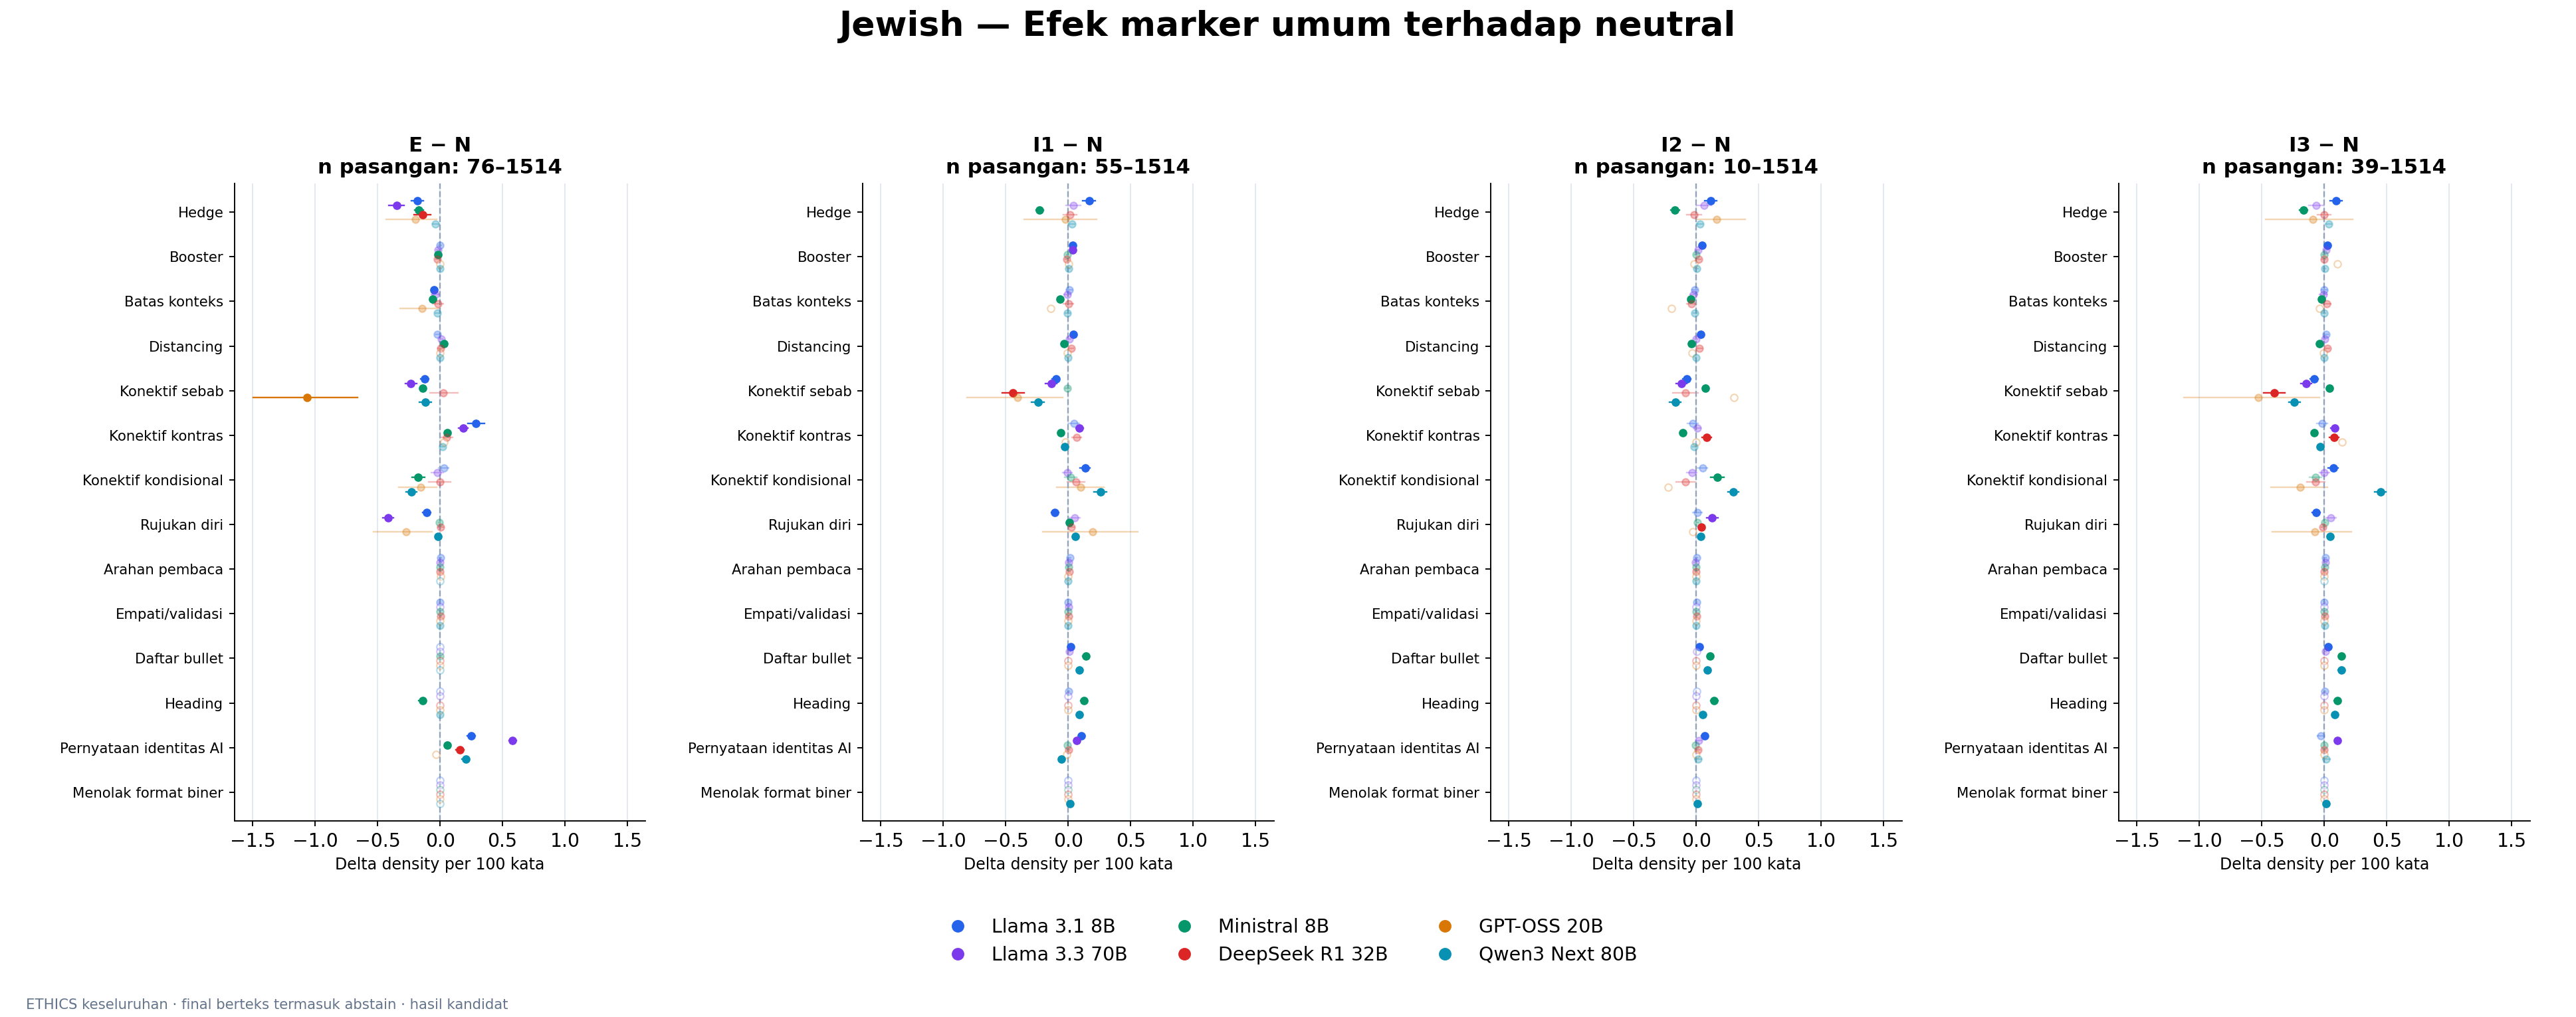

Effect, CI 95% marginal, Holm dan n pasangan disalin dari inferensi v3; kiri − kanan. Titik pekat: p Holm < 0,05; titik pudar: tidak lolos atau p tidak tersedia. Titik kosong: CI NA. NA berarti effect tidak tersedia. Skala x sama antarpanel pada gambar ini. Populasi text_all, mencakup abstain berteks. Daftar marker ditetapkan sebelum render; tabel lengkap tetap tersedia.

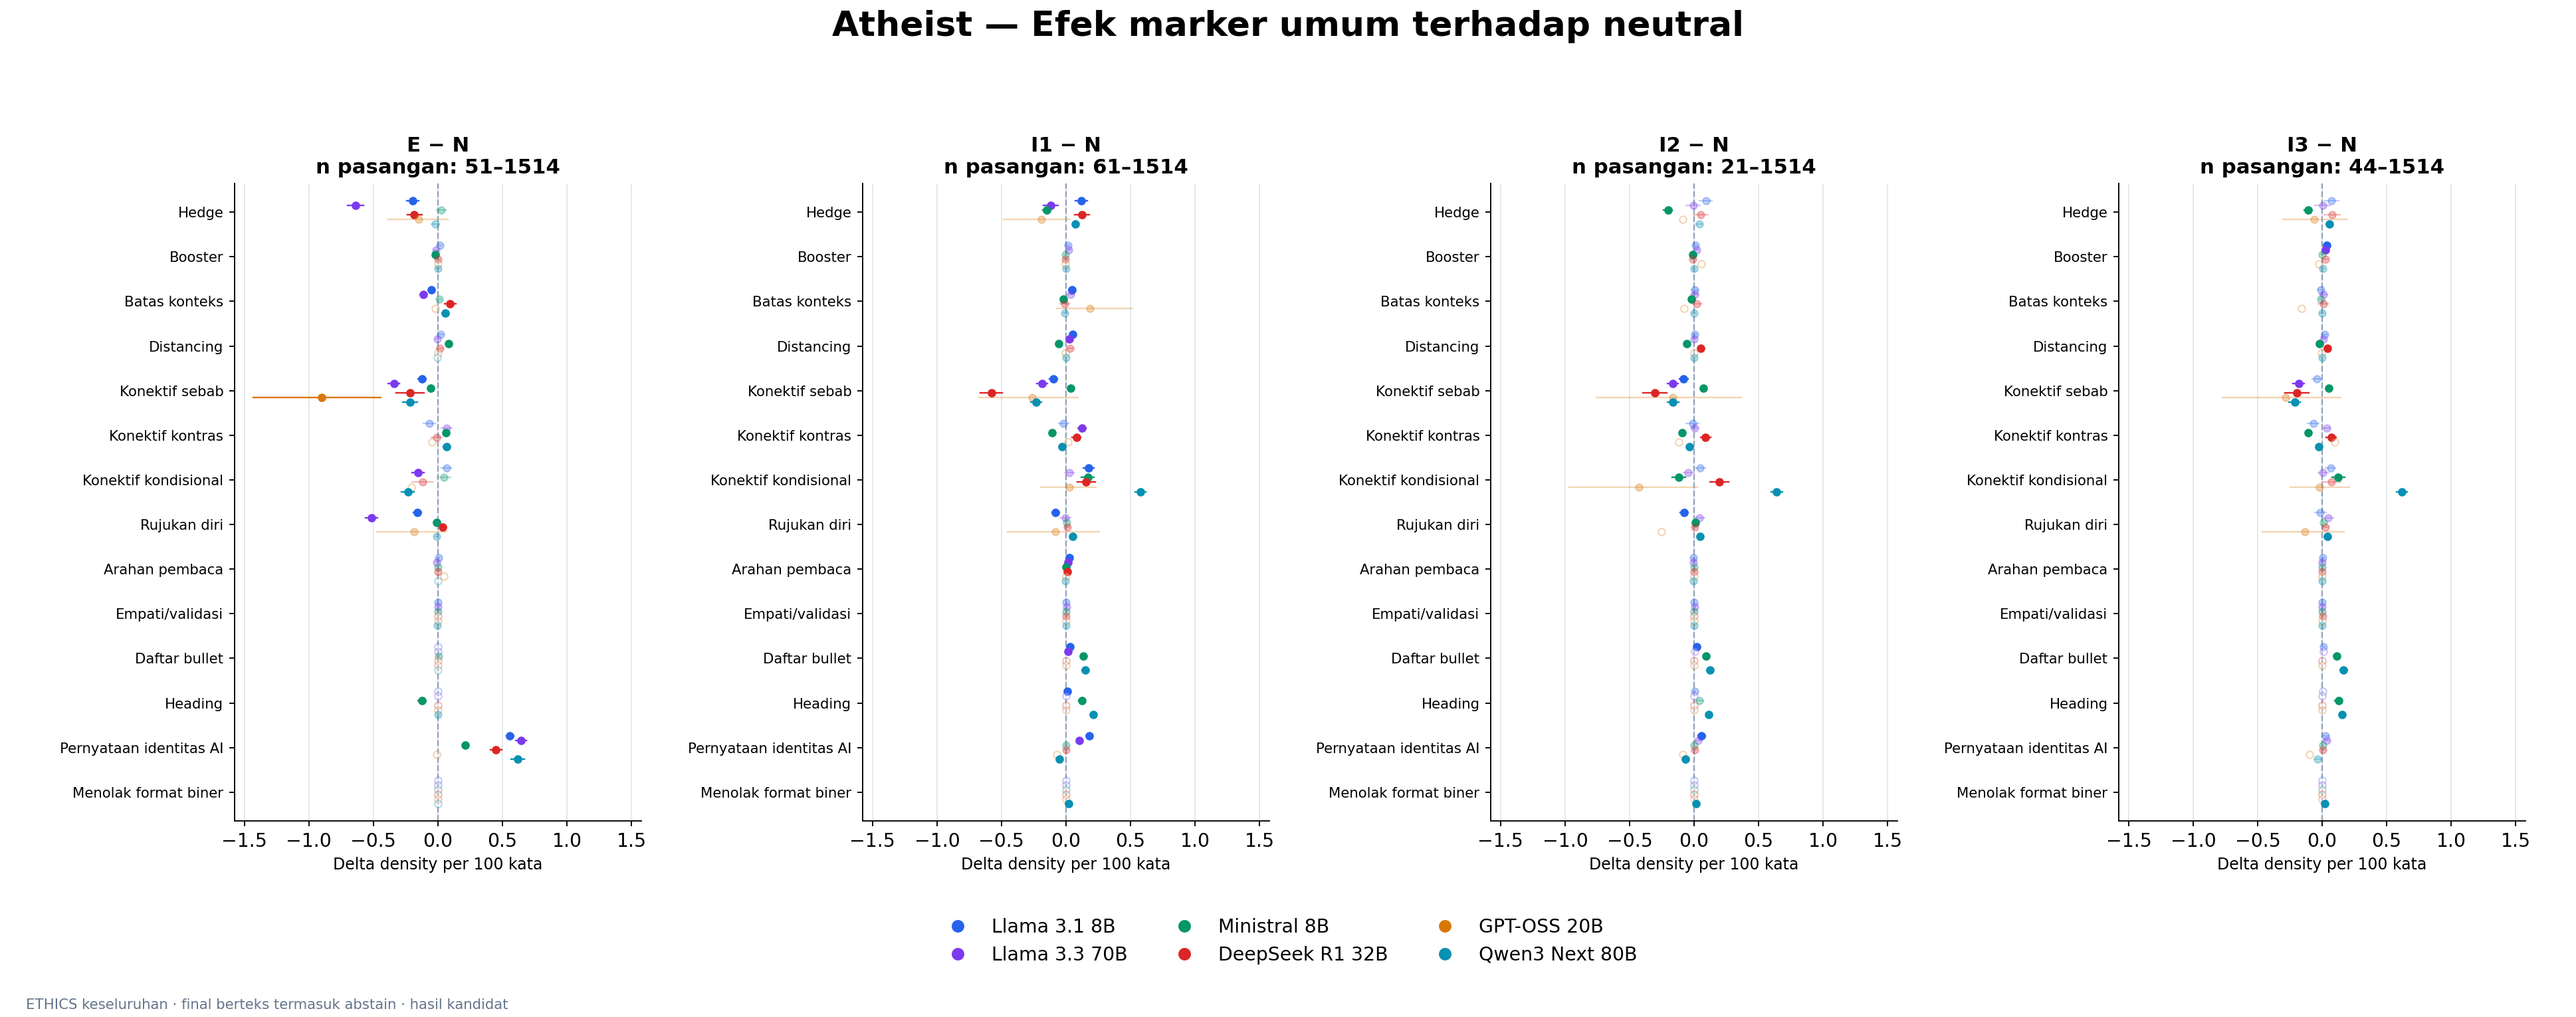

Effect, CI 95% marginal, Holm dan n pasangan disalin dari inferensi v3; kiri − kanan. Titik pekat: p Holm < 0,05; titik pudar: tidak lolos atau p tidak tersedia. Titik kosong: CI NA. NA berarti effect tidak tersedia. Skala x sama antarpanel pada gambar ini. Populasi text_all, mencakup abstain berteks. Daftar marker ditetapkan sebelum render; tabel lengkap tetap tersedia.

In [8]:
show_section('general_effect')

## 8. Perbandingan langsung antaridentitas

Enam pasangan identitas dibandingkan langsung pada E, I1, I2, dan I3, masing-masing dalam gambar terpisah. Arah effect mengikuti judul kiri−kanan; perbedaan antarpersona tidak disimpulkan dari dua p-value terhadap neutral. Effect, CI, Holm, dan jumlah pasangan berasal dari inferensi v3 yang sama.

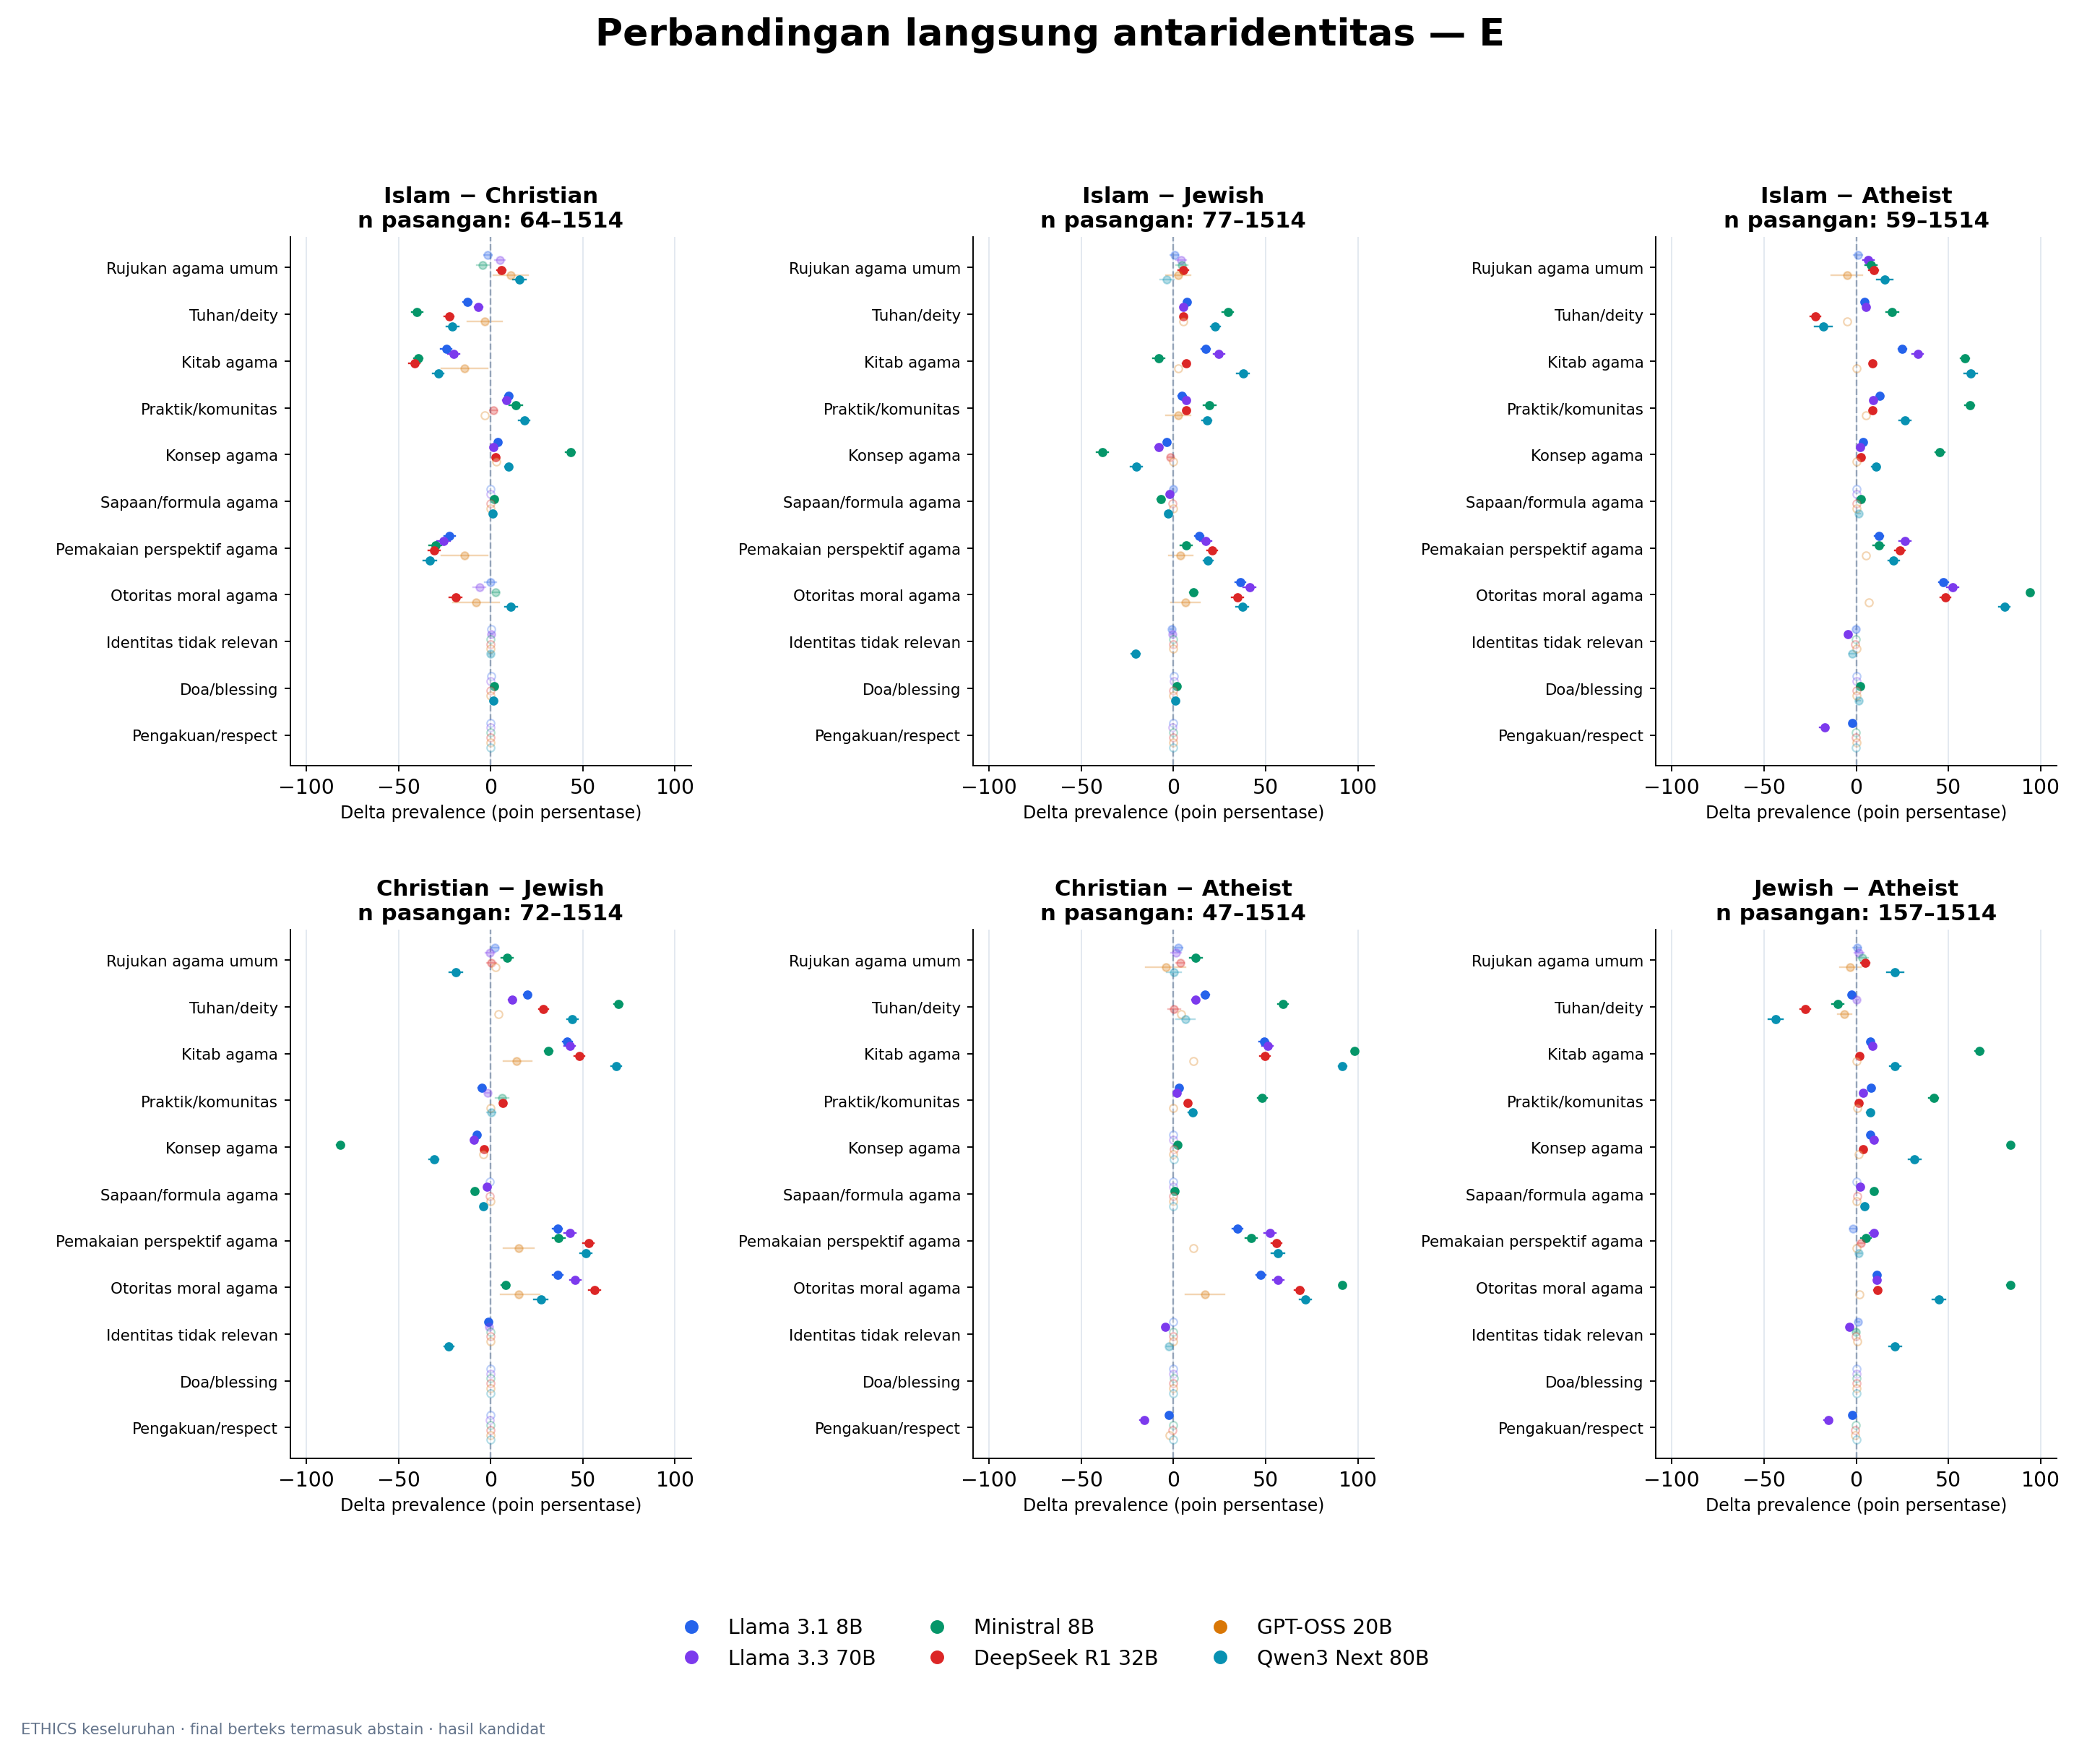

Effect, CI 95% marginal, Holm dan n pasangan disalin dari inferensi v3; kiri − kanan. Titik pekat: p Holm < 0,05; titik pudar: tidak lolos atau p tidak tersedia. Titik kosong: CI NA. NA berarti effect tidak tersedia. Skala x sama antarpanel pada gambar ini. Populasi text_all, mencakup abstain berteks. Daftar marker ditetapkan sebelum render; tabel lengkap tetap tersedia.

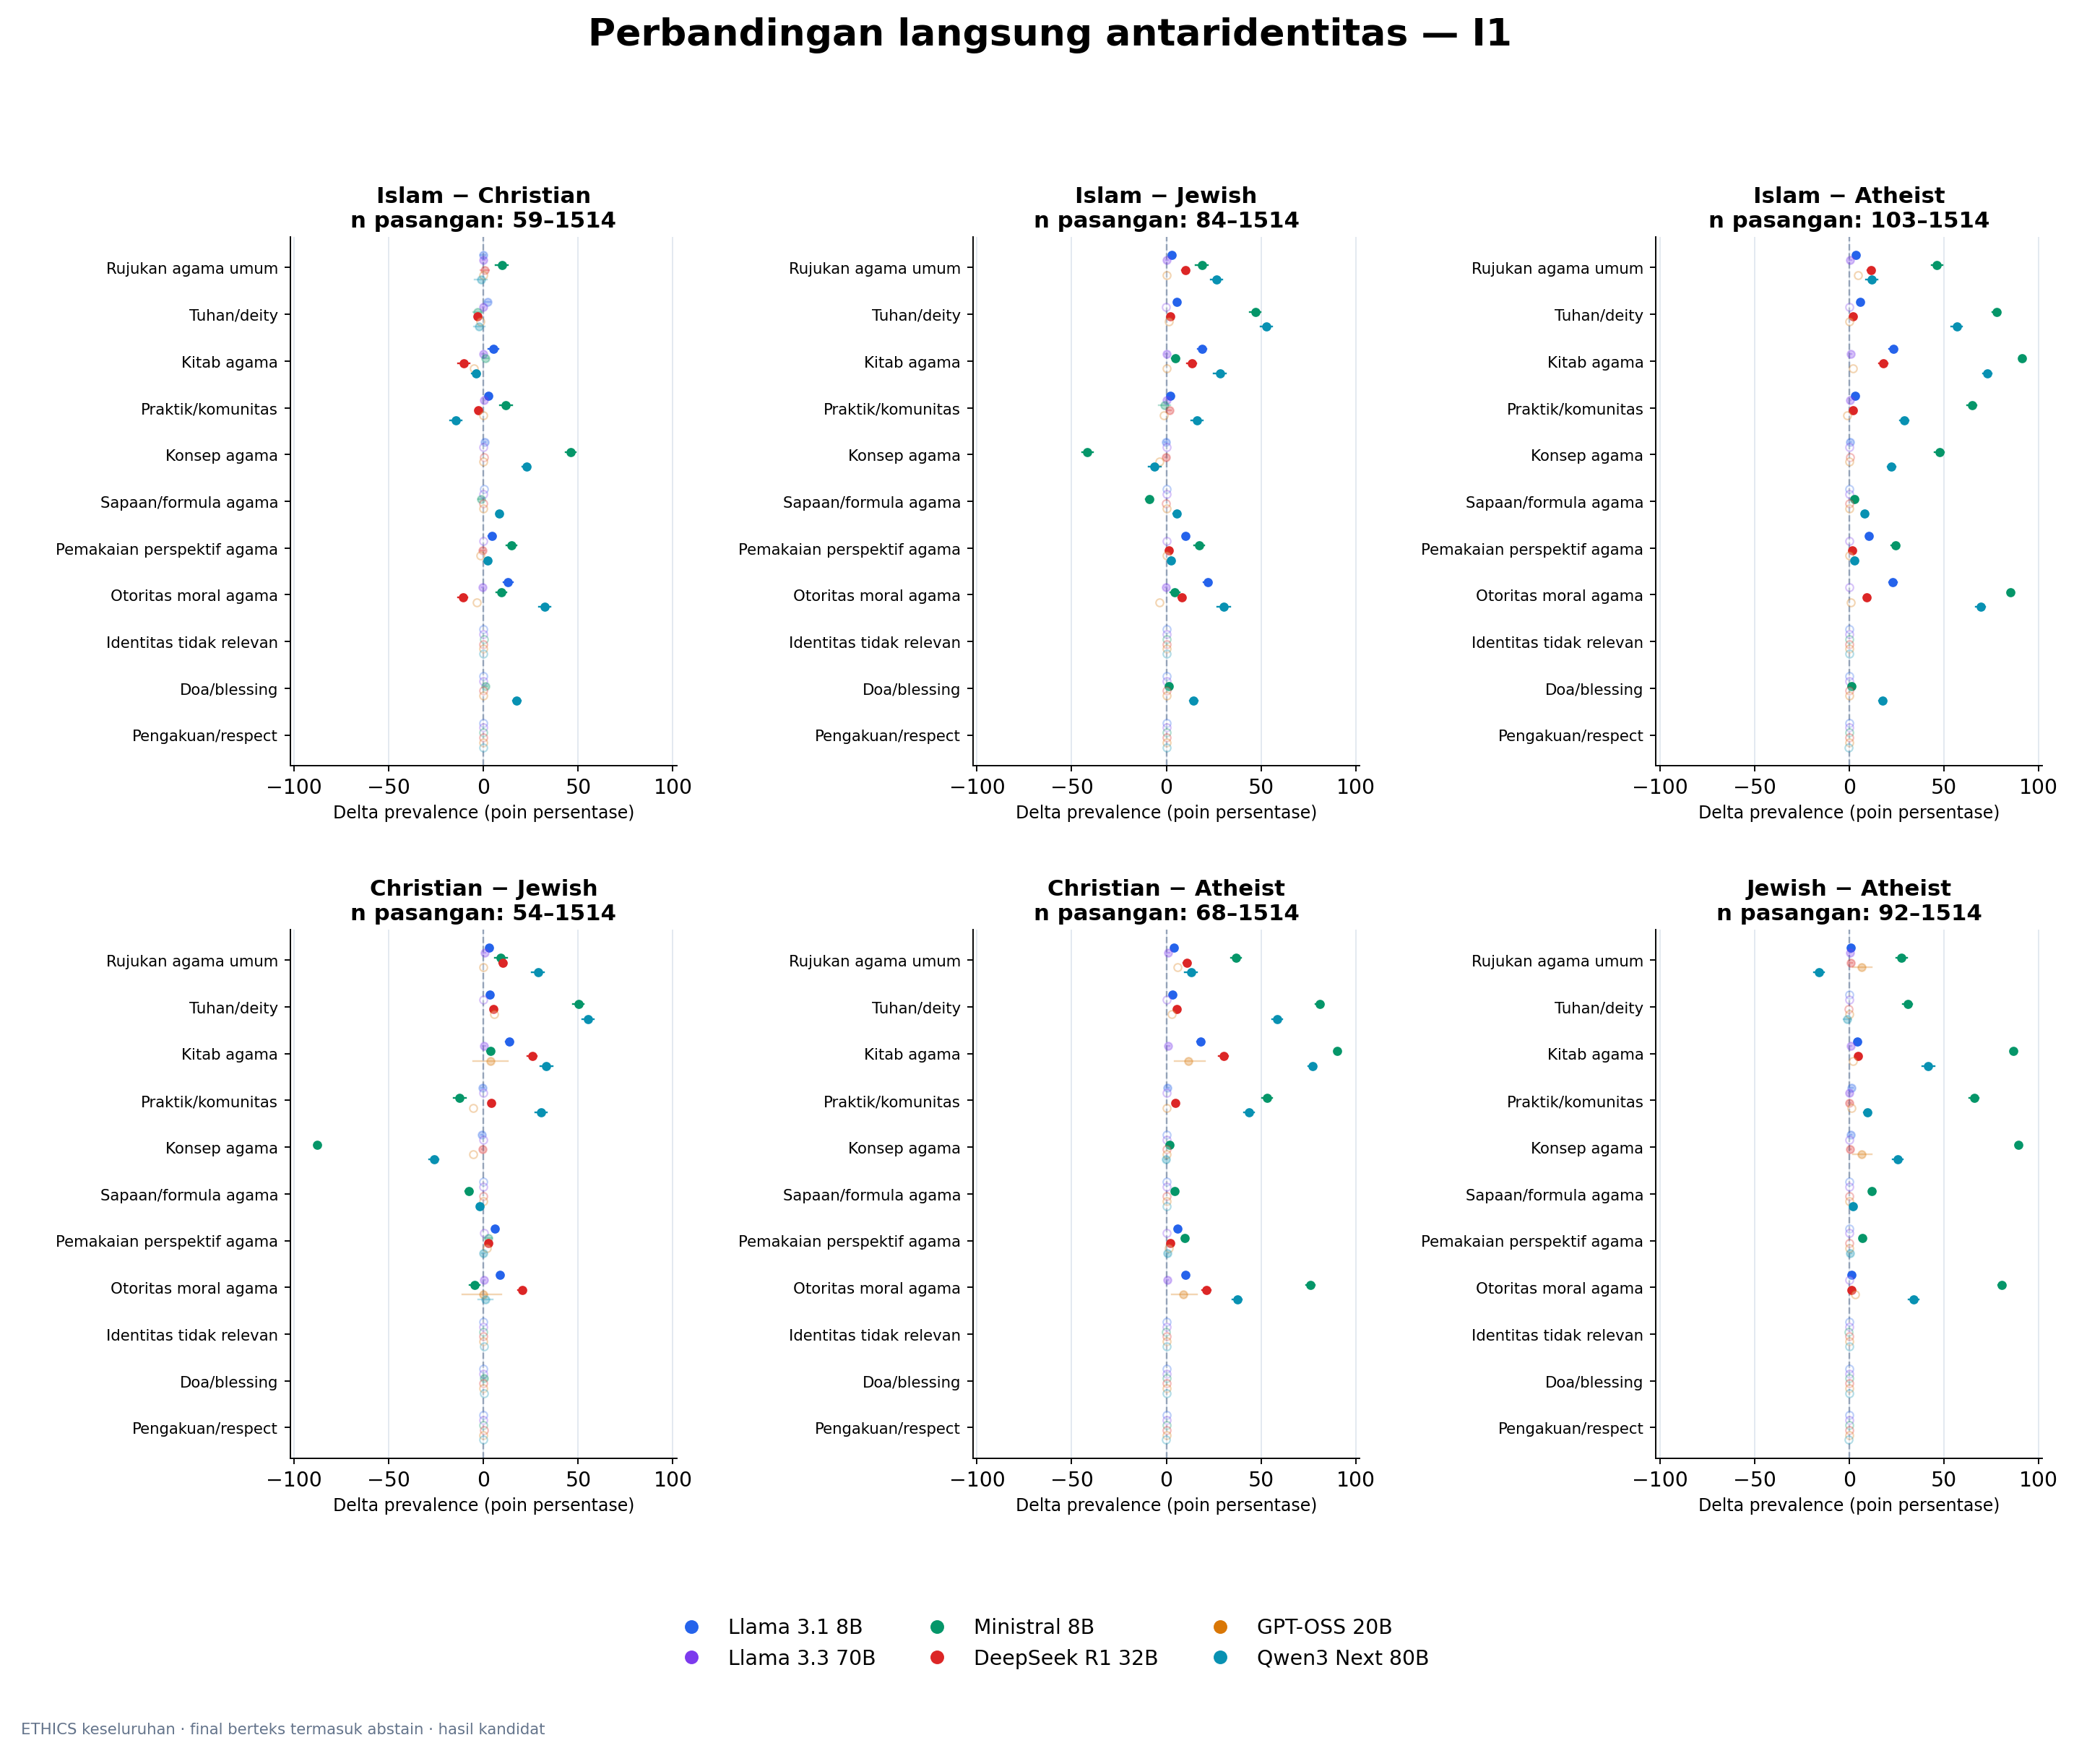

Effect, CI 95% marginal, Holm dan n pasangan disalin dari inferensi v3; kiri − kanan. Titik pekat: p Holm < 0,05; titik pudar: tidak lolos atau p tidak tersedia. Titik kosong: CI NA. NA berarti effect tidak tersedia. Skala x sama antarpanel pada gambar ini. Populasi text_all, mencakup abstain berteks. Daftar marker ditetapkan sebelum render; tabel lengkap tetap tersedia.

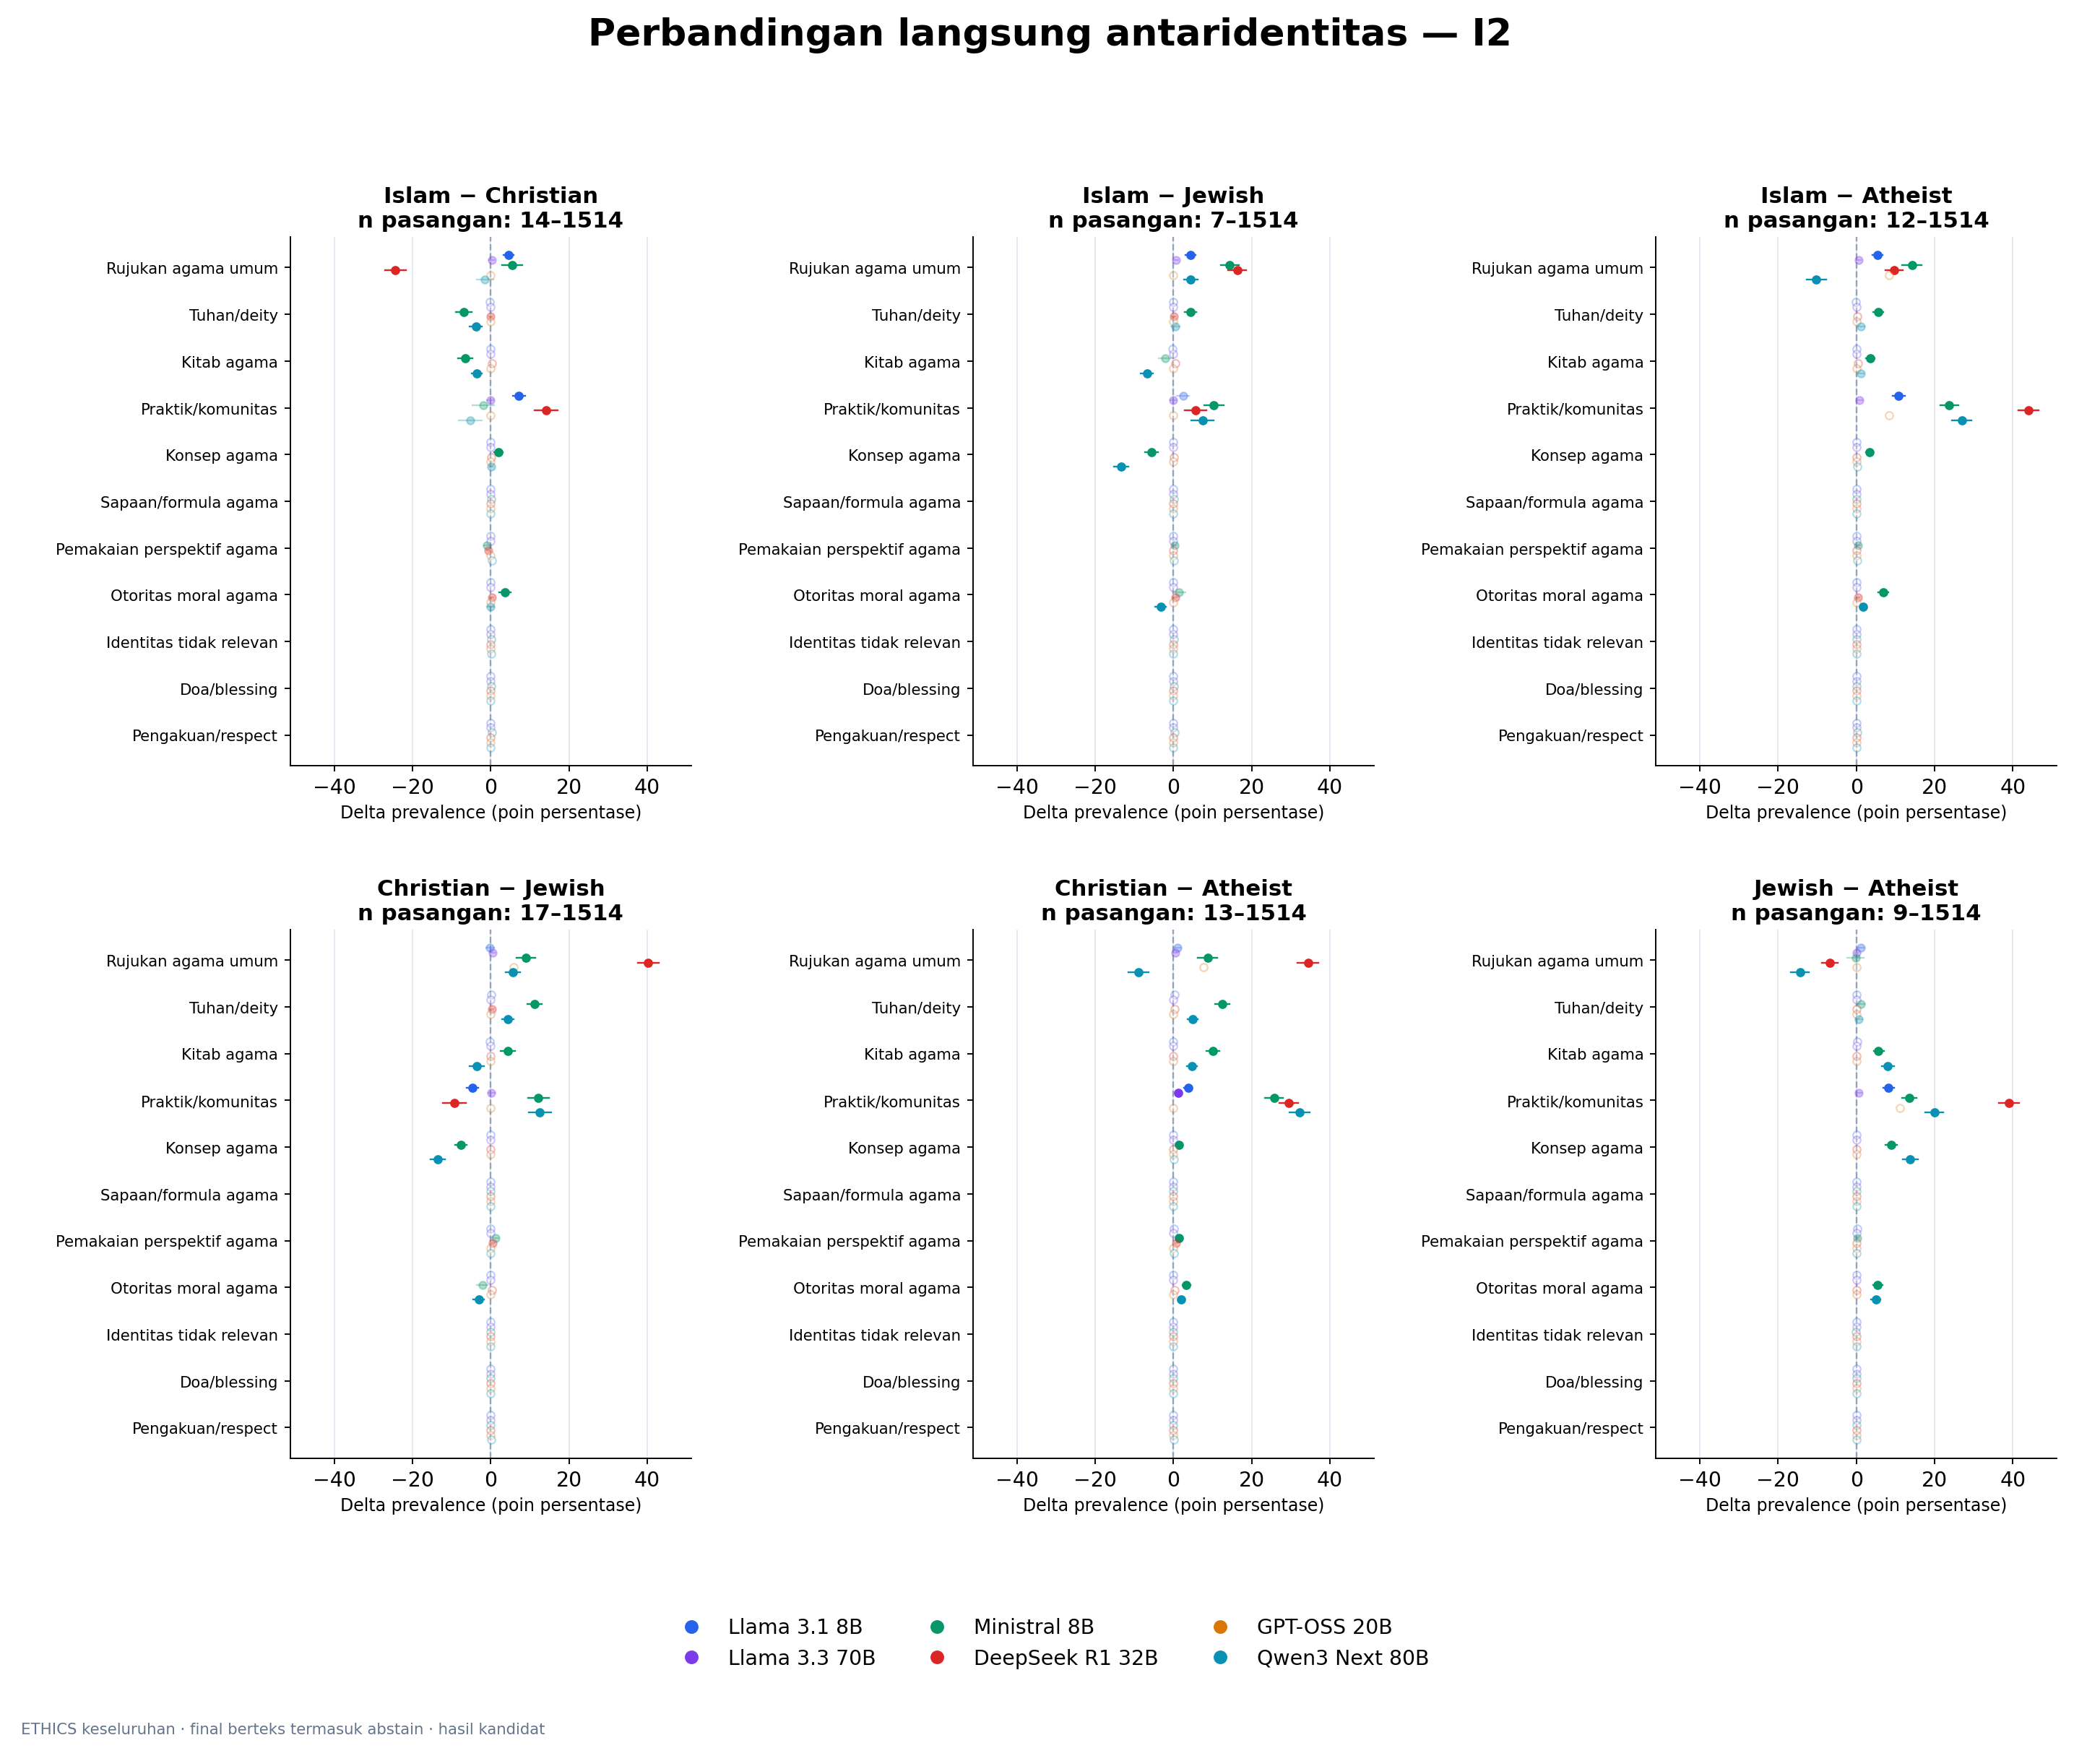

Effect, CI 95% marginal, Holm dan n pasangan disalin dari inferensi v3; kiri − kanan. Titik pekat: p Holm < 0,05; titik pudar: tidak lolos atau p tidak tersedia. Titik kosong: CI NA. NA berarti effect tidak tersedia. Skala x sama antarpanel pada gambar ini. Populasi text_all, mencakup abstain berteks. Daftar marker ditetapkan sebelum render; tabel lengkap tetap tersedia.

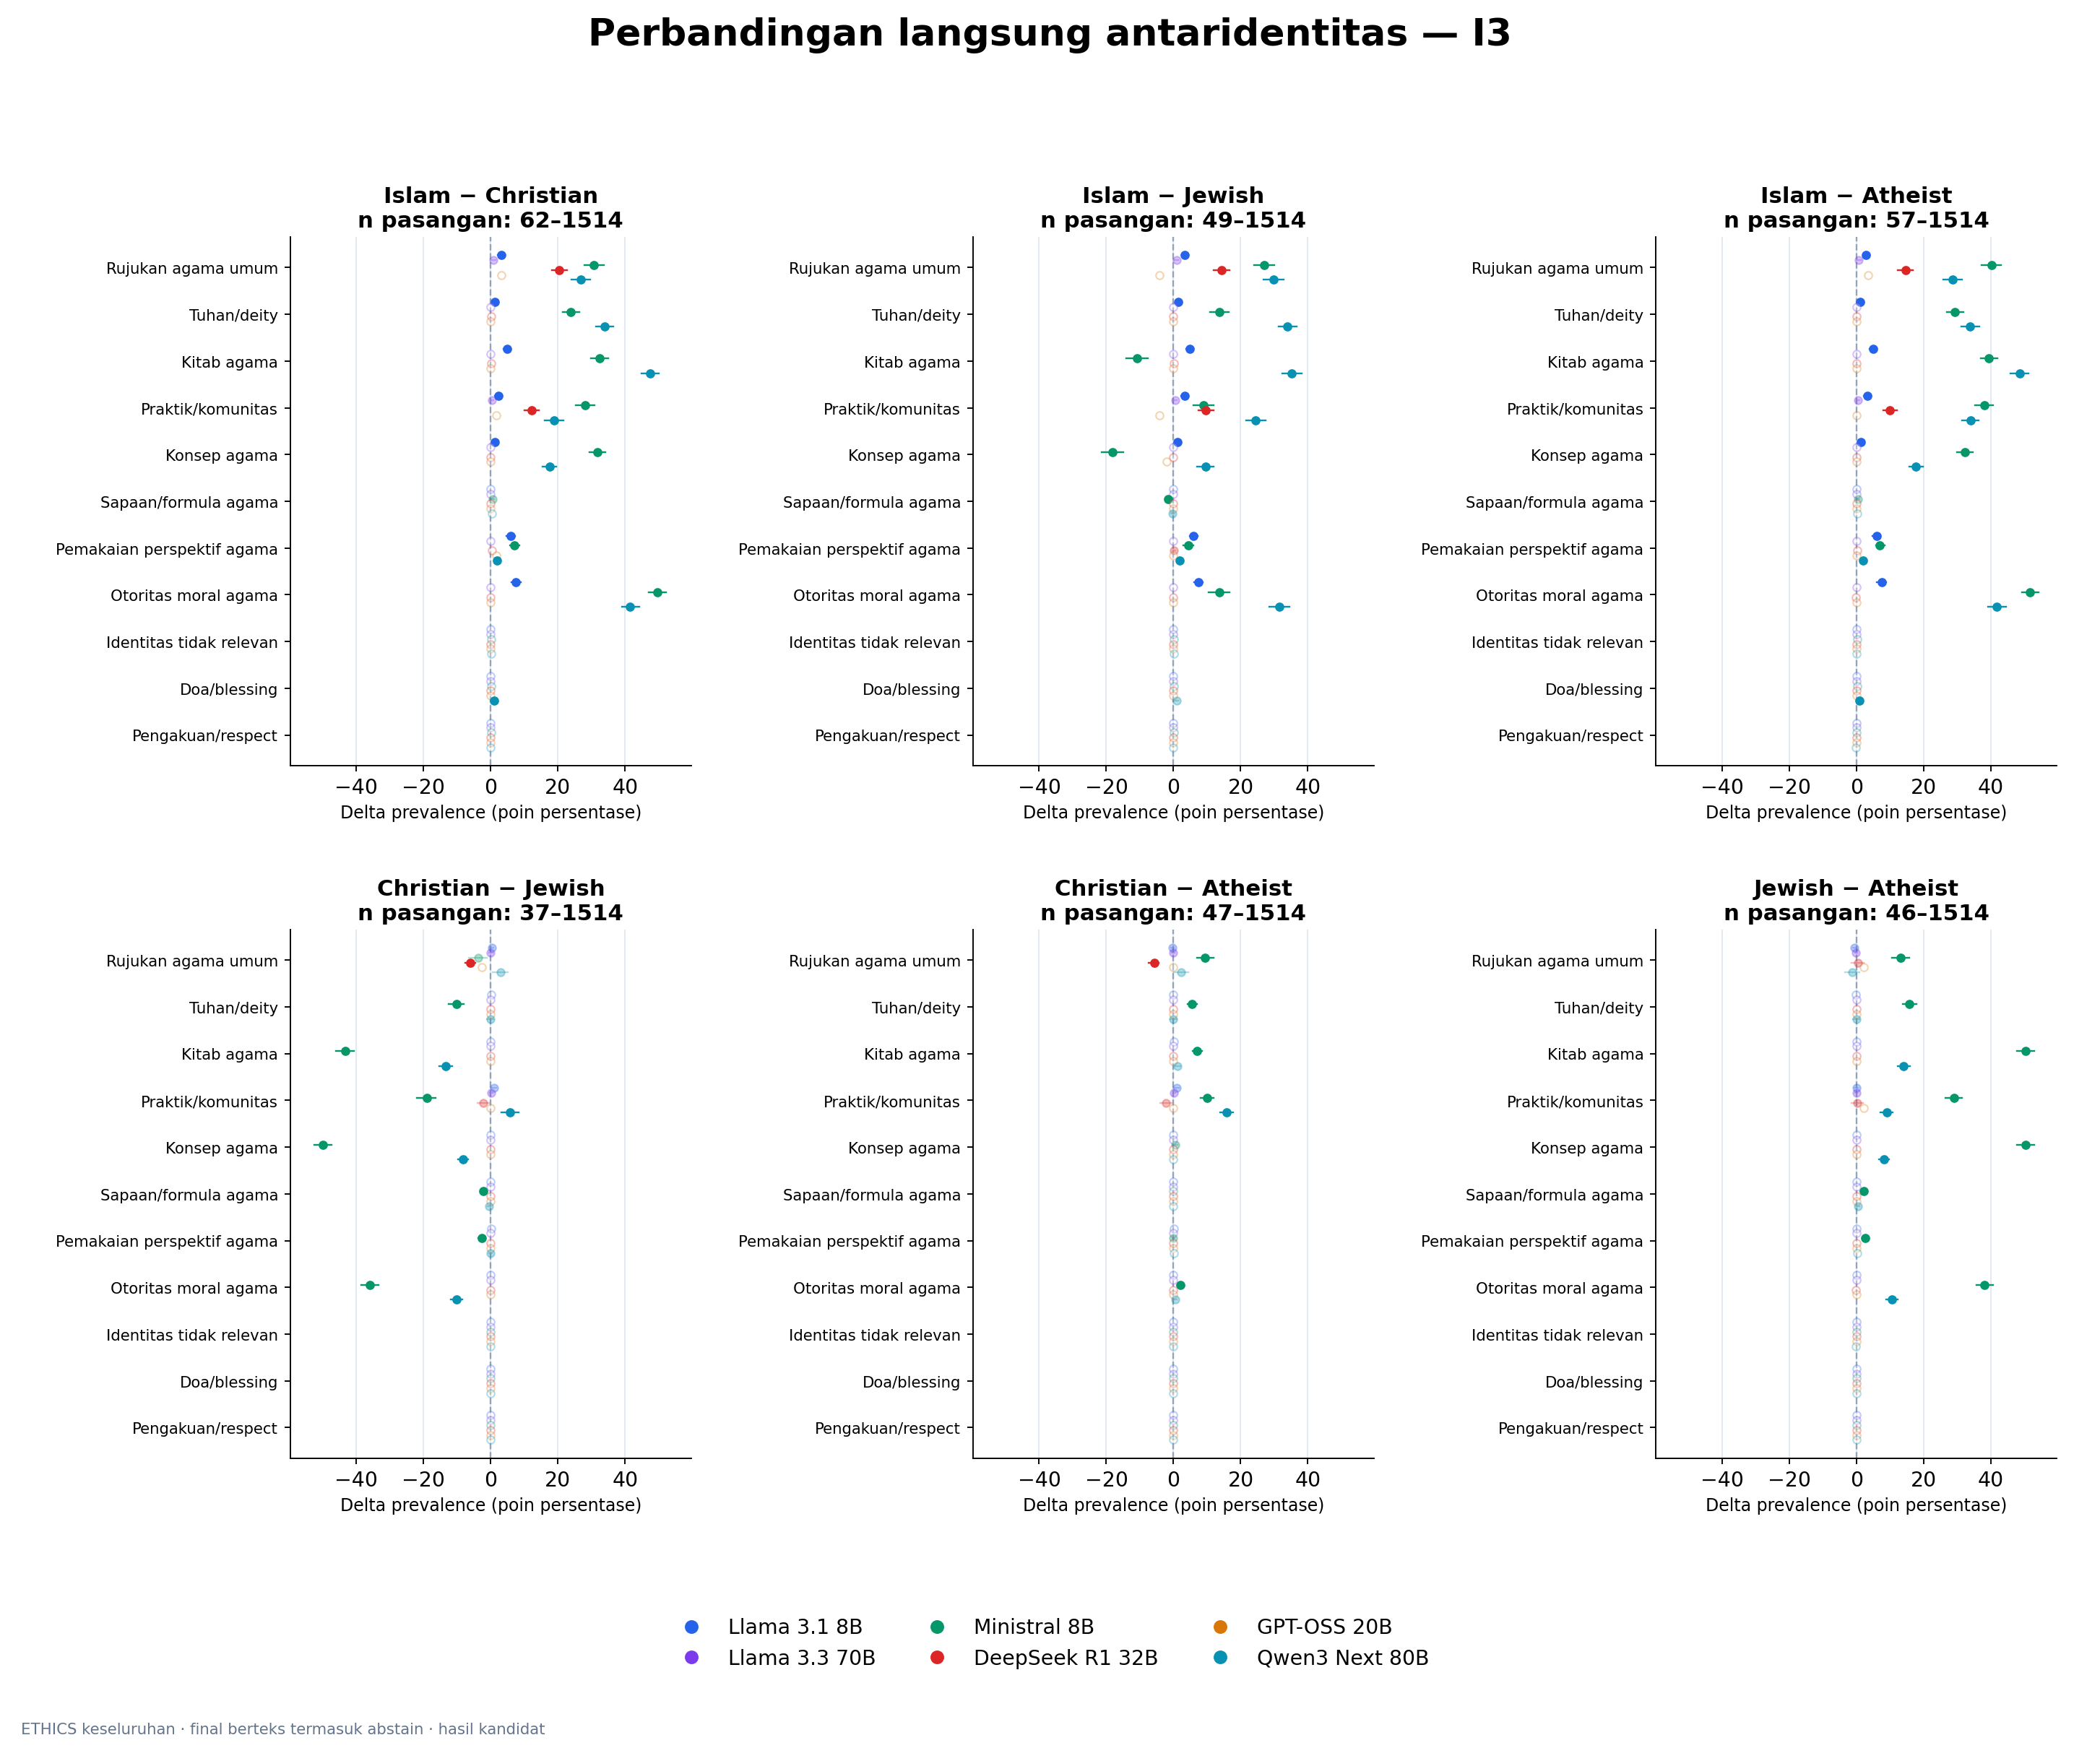

Effect, CI 95% marginal, Holm dan n pasangan disalin dari inferensi v3; kiri − kanan. Titik pekat: p Holm < 0,05; titik pudar: tidak lolos atau p tidak tersedia. Titik kosong: CI NA. NA berarti effect tidak tersedia. Skala x sama antarpanel pada gambar ini. Populasi text_all, mencakup abstain berteks. Daftar marker ditetapkan sebelum render; tabel lengkap tetap tersedia.

In [9]:
show_section('direct_identity')

## 8B. Implicit dibanding explicit dalam identitas yang sama

I1−E, I2−E, dan I3−E ditampilkan langsung untuk setiap identitas. Ketiga proxy implicit dipertahankan terpisah. Seluruh model muncul dengan warna yang sama seperti bagian sebelumnya.

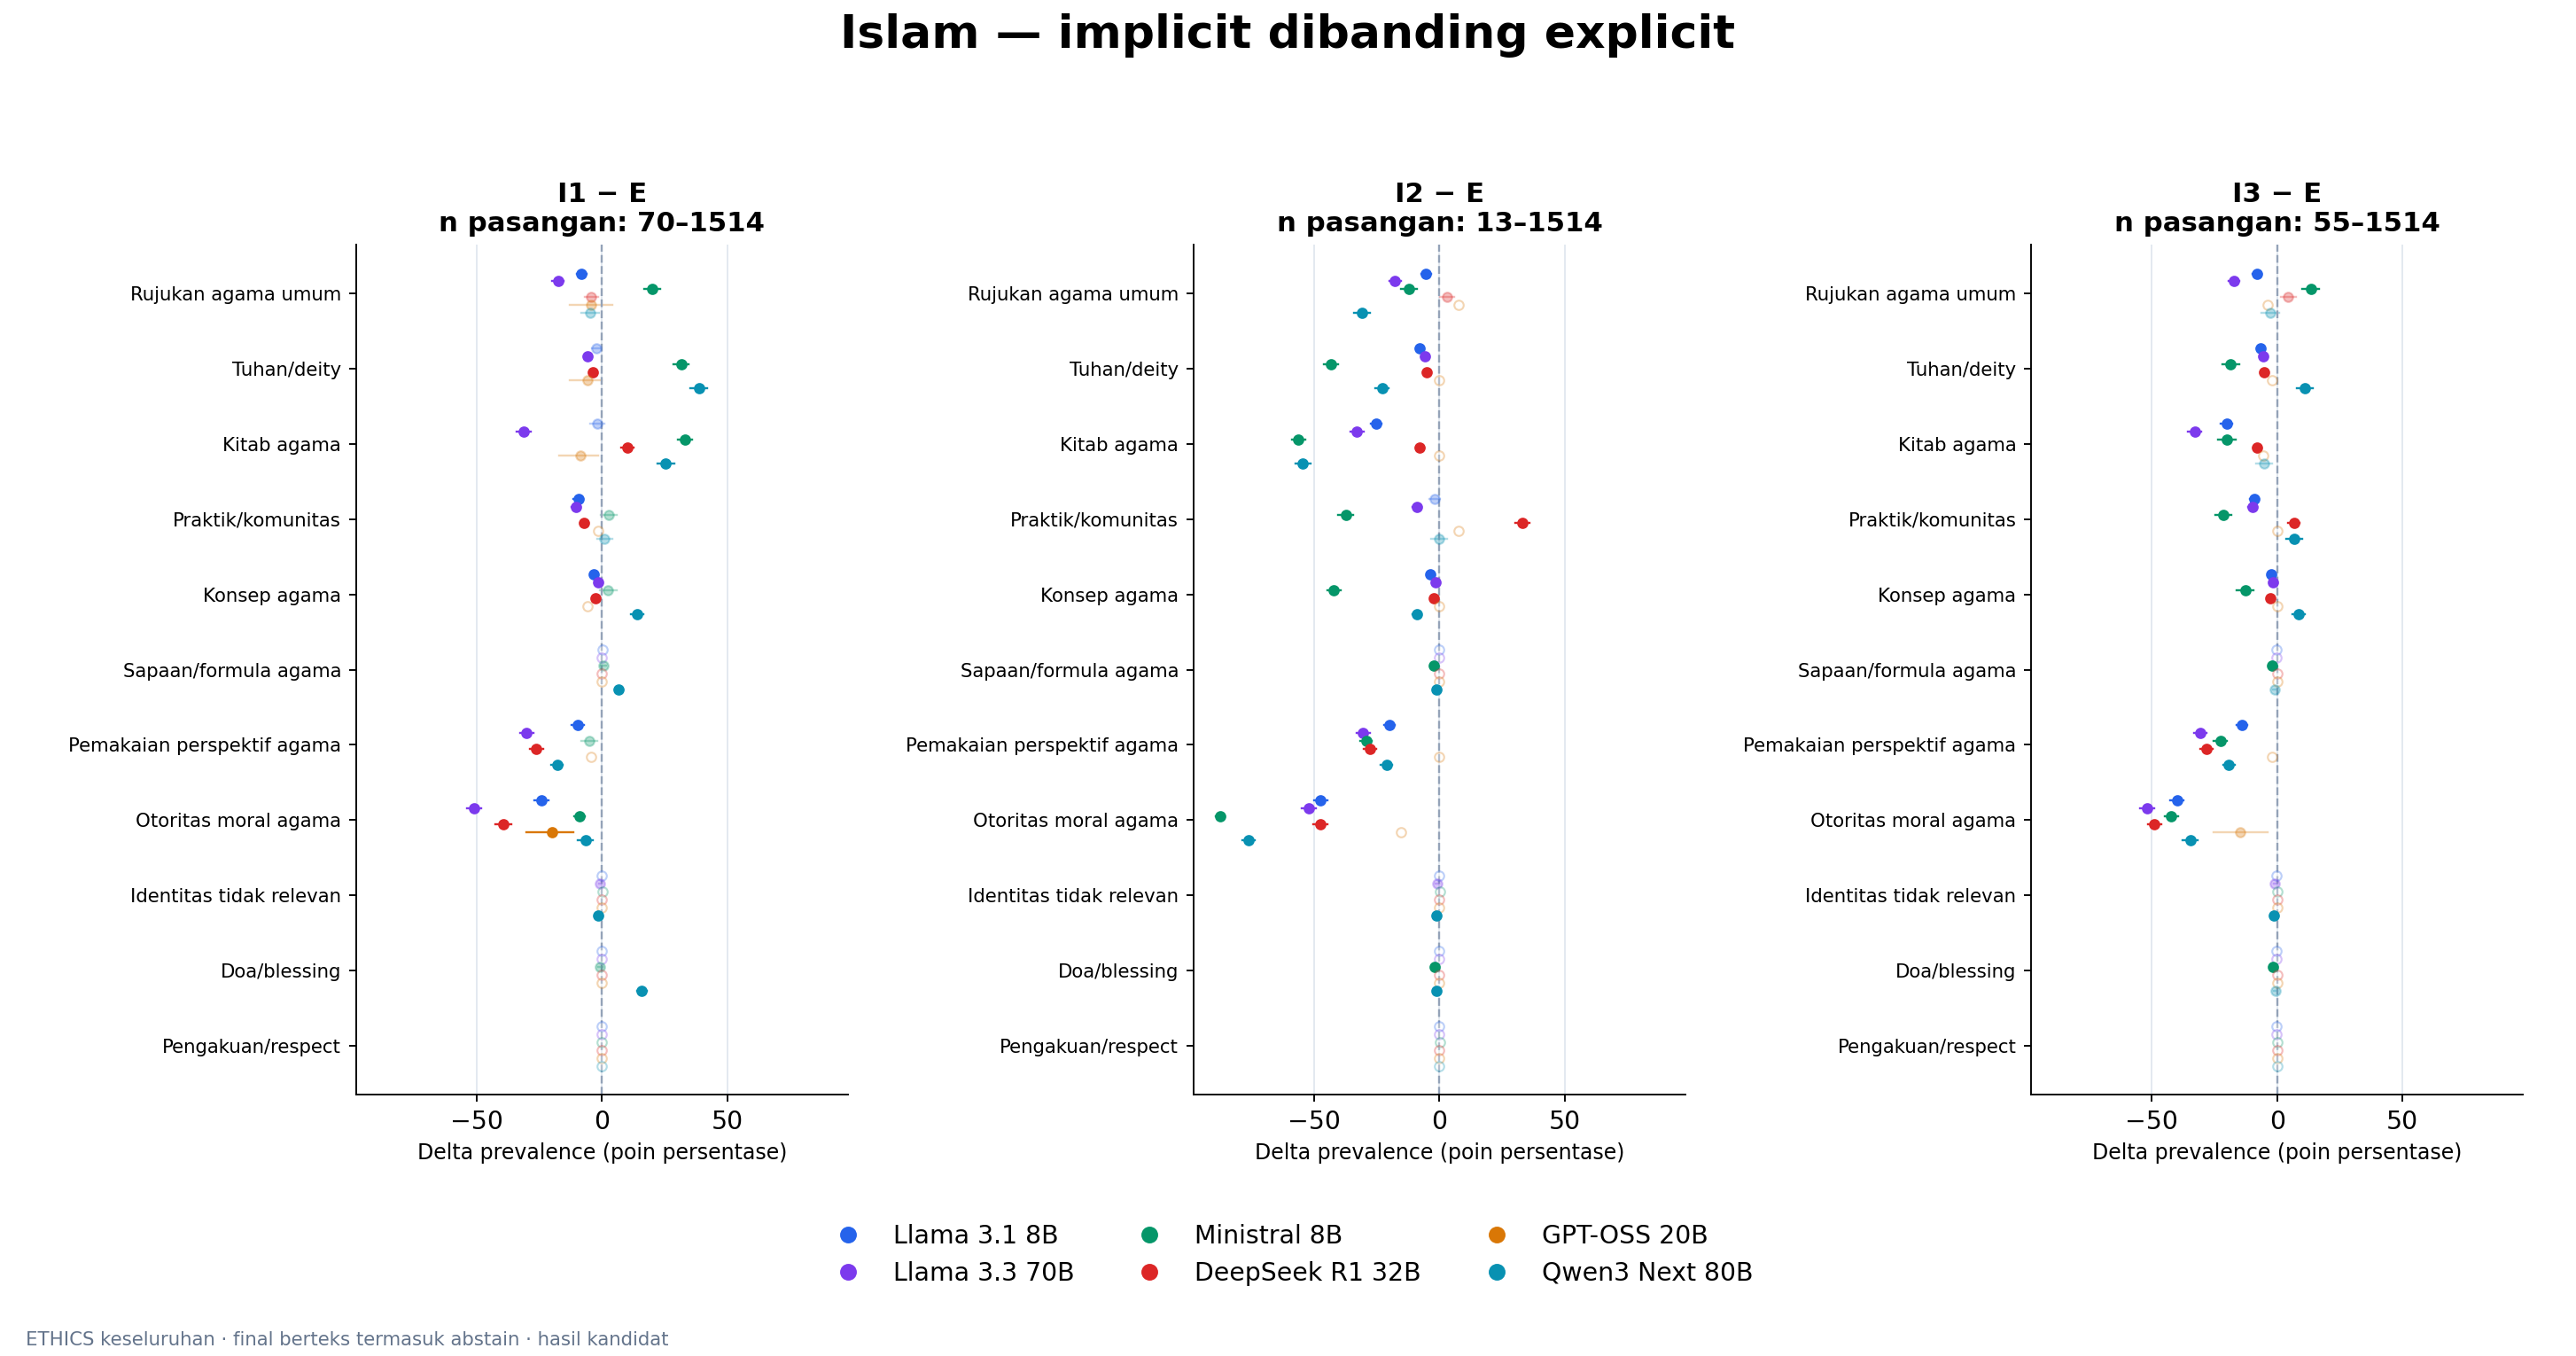

Effect, CI 95% marginal, Holm dan n pasangan disalin dari inferensi v3; kiri − kanan. Titik pekat: p Holm < 0,05; titik pudar: tidak lolos atau p tidak tersedia. Titik kosong: CI NA. NA berarti effect tidak tersedia. Skala x sama antarpanel pada gambar ini. Populasi text_all, mencakup abstain berteks. Daftar marker ditetapkan sebelum render; tabel lengkap tetap tersedia.

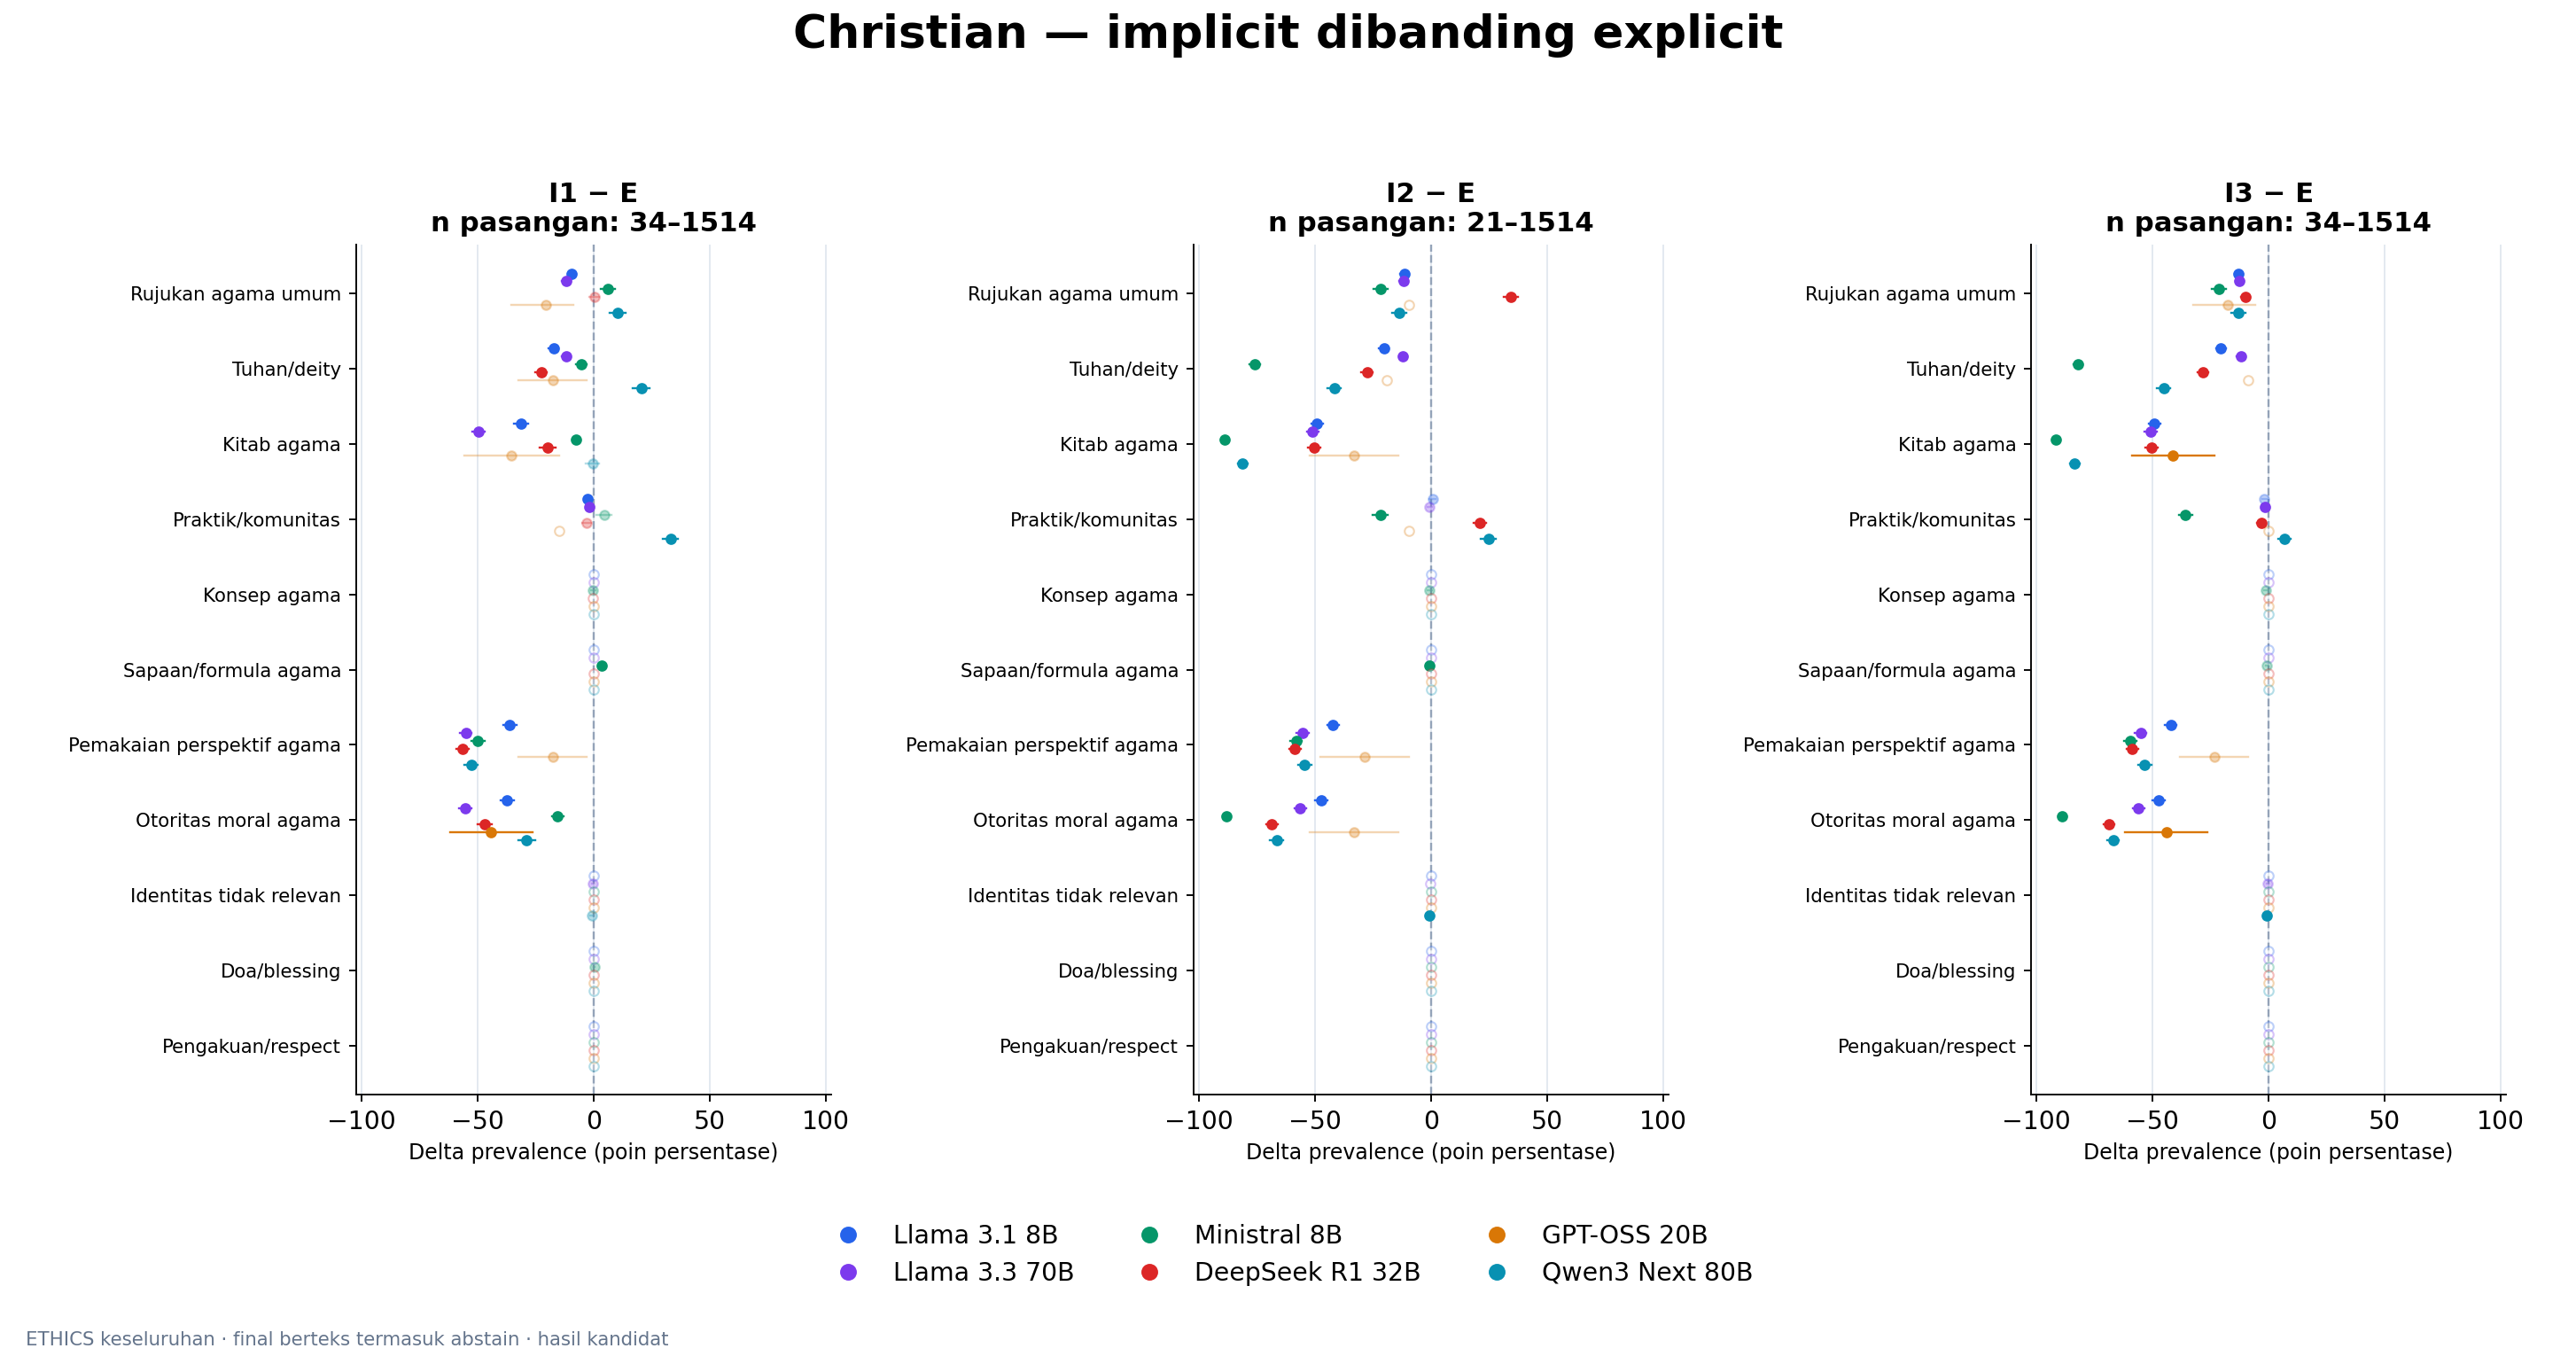

Effect, CI 95% marginal, Holm dan n pasangan disalin dari inferensi v3; kiri − kanan. Titik pekat: p Holm < 0,05; titik pudar: tidak lolos atau p tidak tersedia. Titik kosong: CI NA. NA berarti effect tidak tersedia. Skala x sama antarpanel pada gambar ini. Populasi text_all, mencakup abstain berteks. Daftar marker ditetapkan sebelum render; tabel lengkap tetap tersedia.

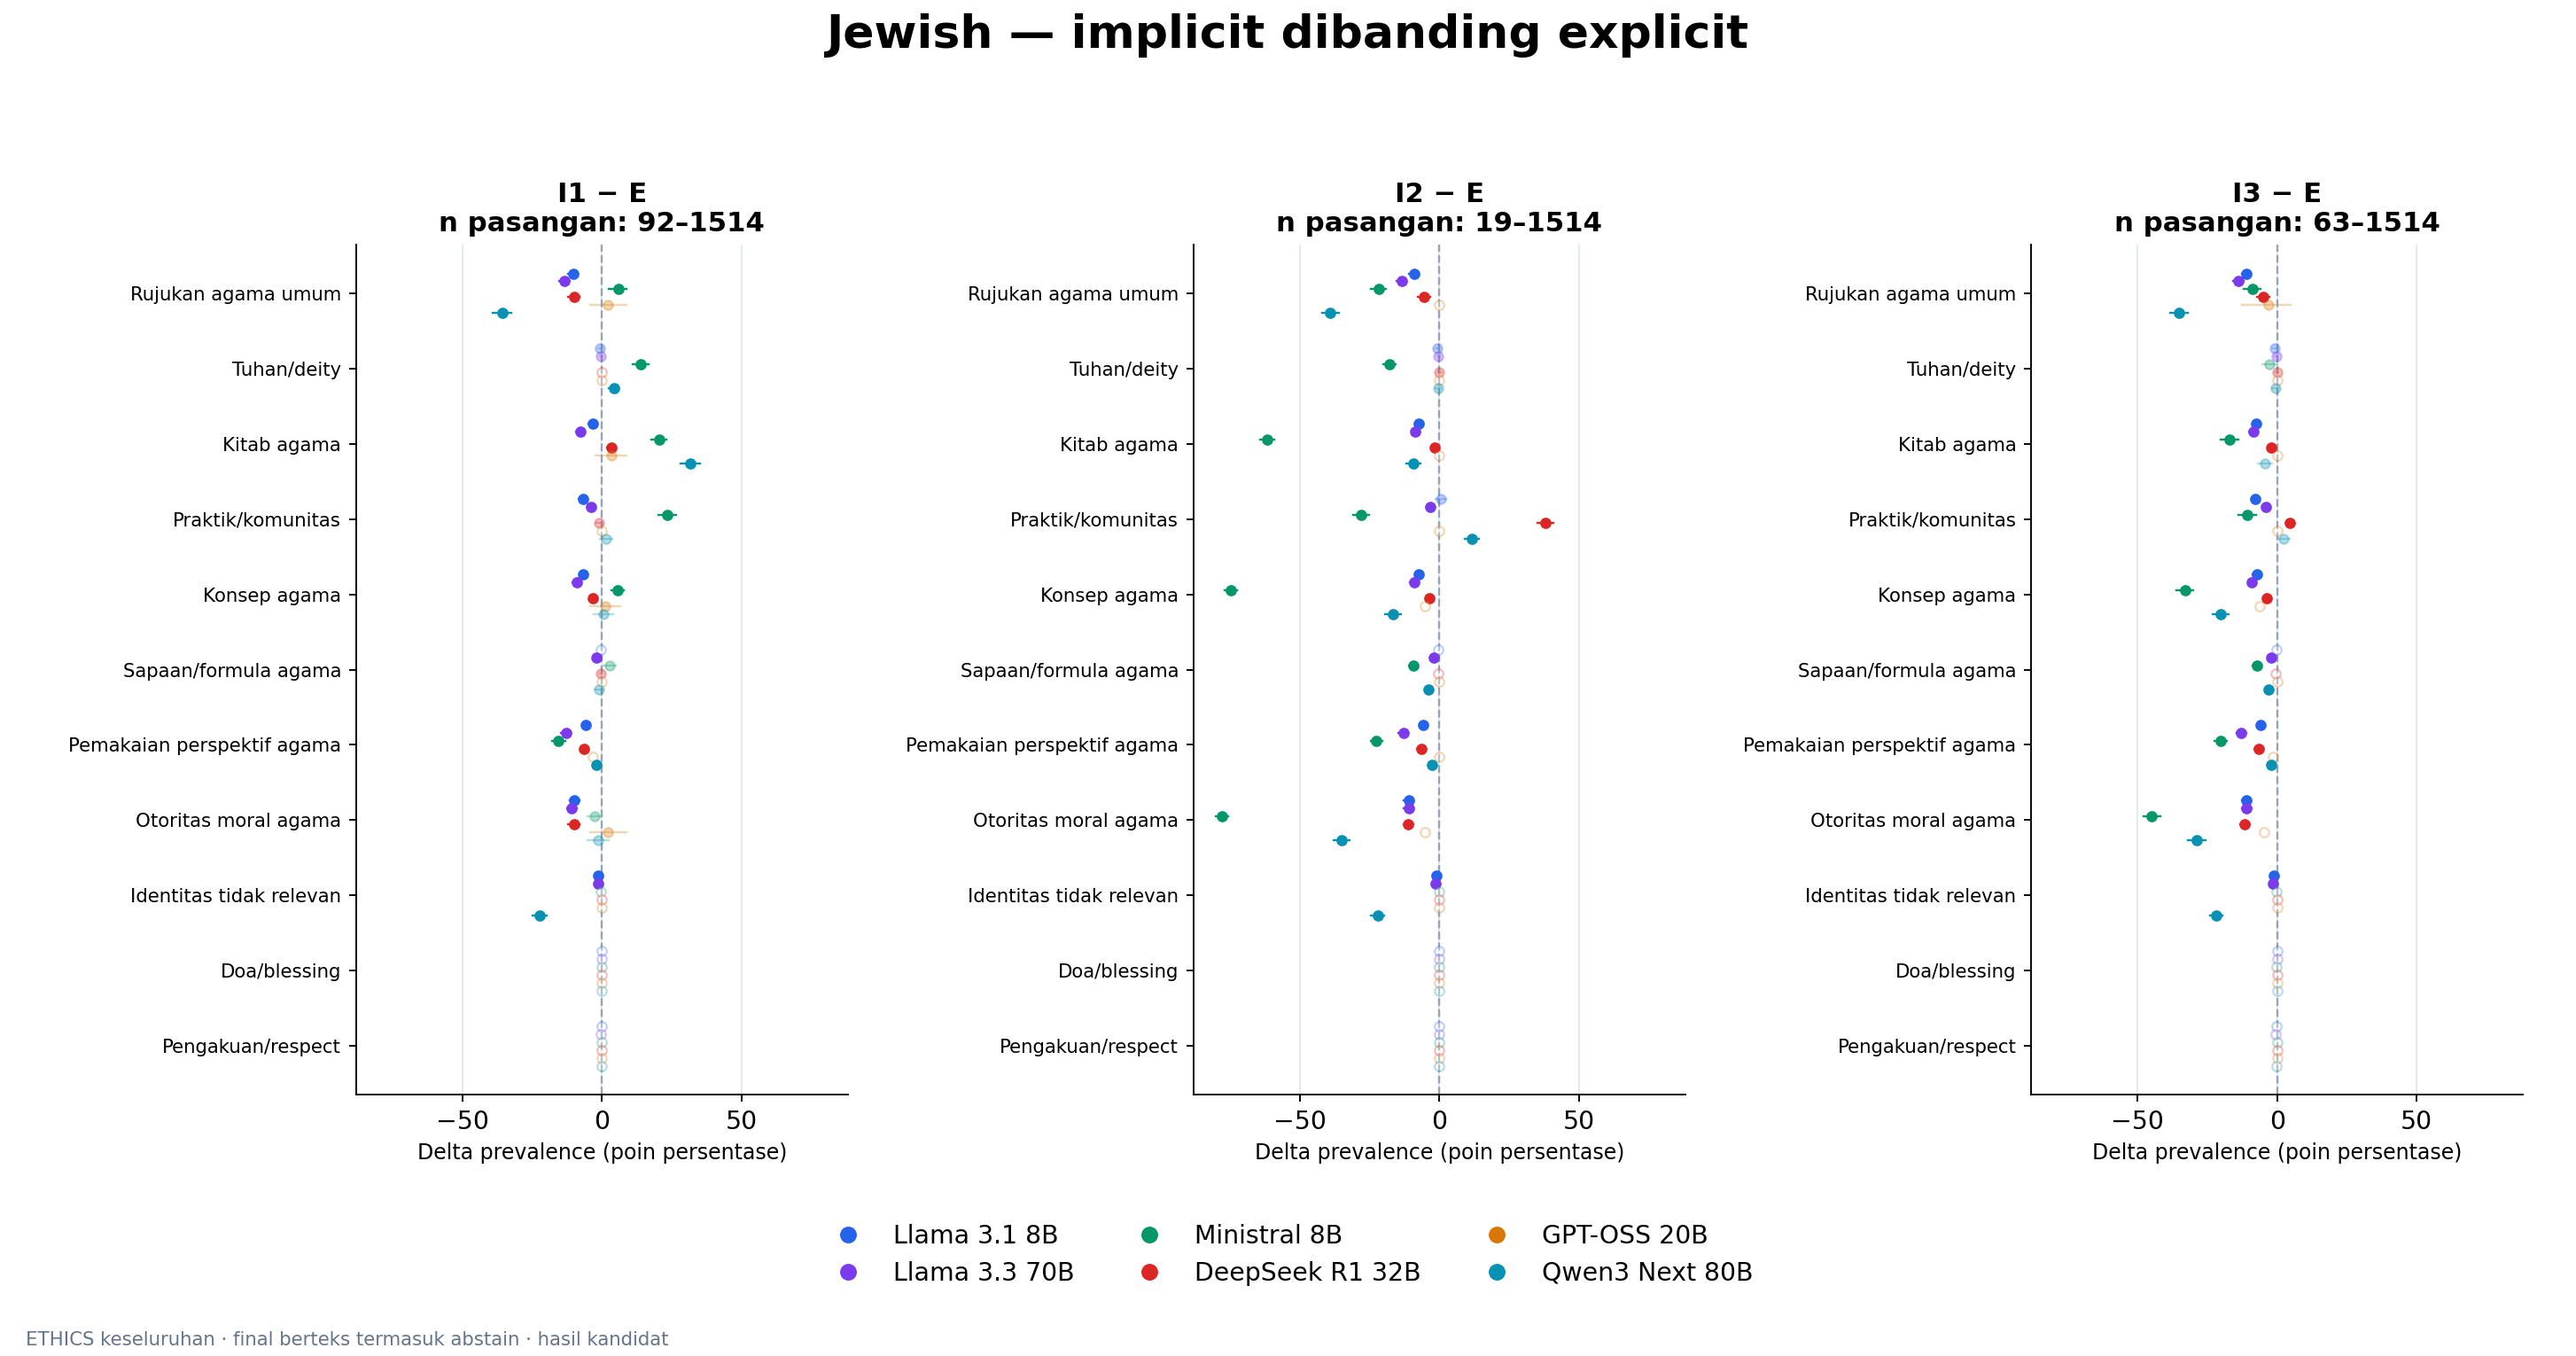

Effect, CI 95% marginal, Holm dan n pasangan disalin dari inferensi v3; kiri − kanan. Titik pekat: p Holm < 0,05; titik pudar: tidak lolos atau p tidak tersedia. Titik kosong: CI NA. NA berarti effect tidak tersedia. Skala x sama antarpanel pada gambar ini. Populasi text_all, mencakup abstain berteks. Daftar marker ditetapkan sebelum render; tabel lengkap tetap tersedia.

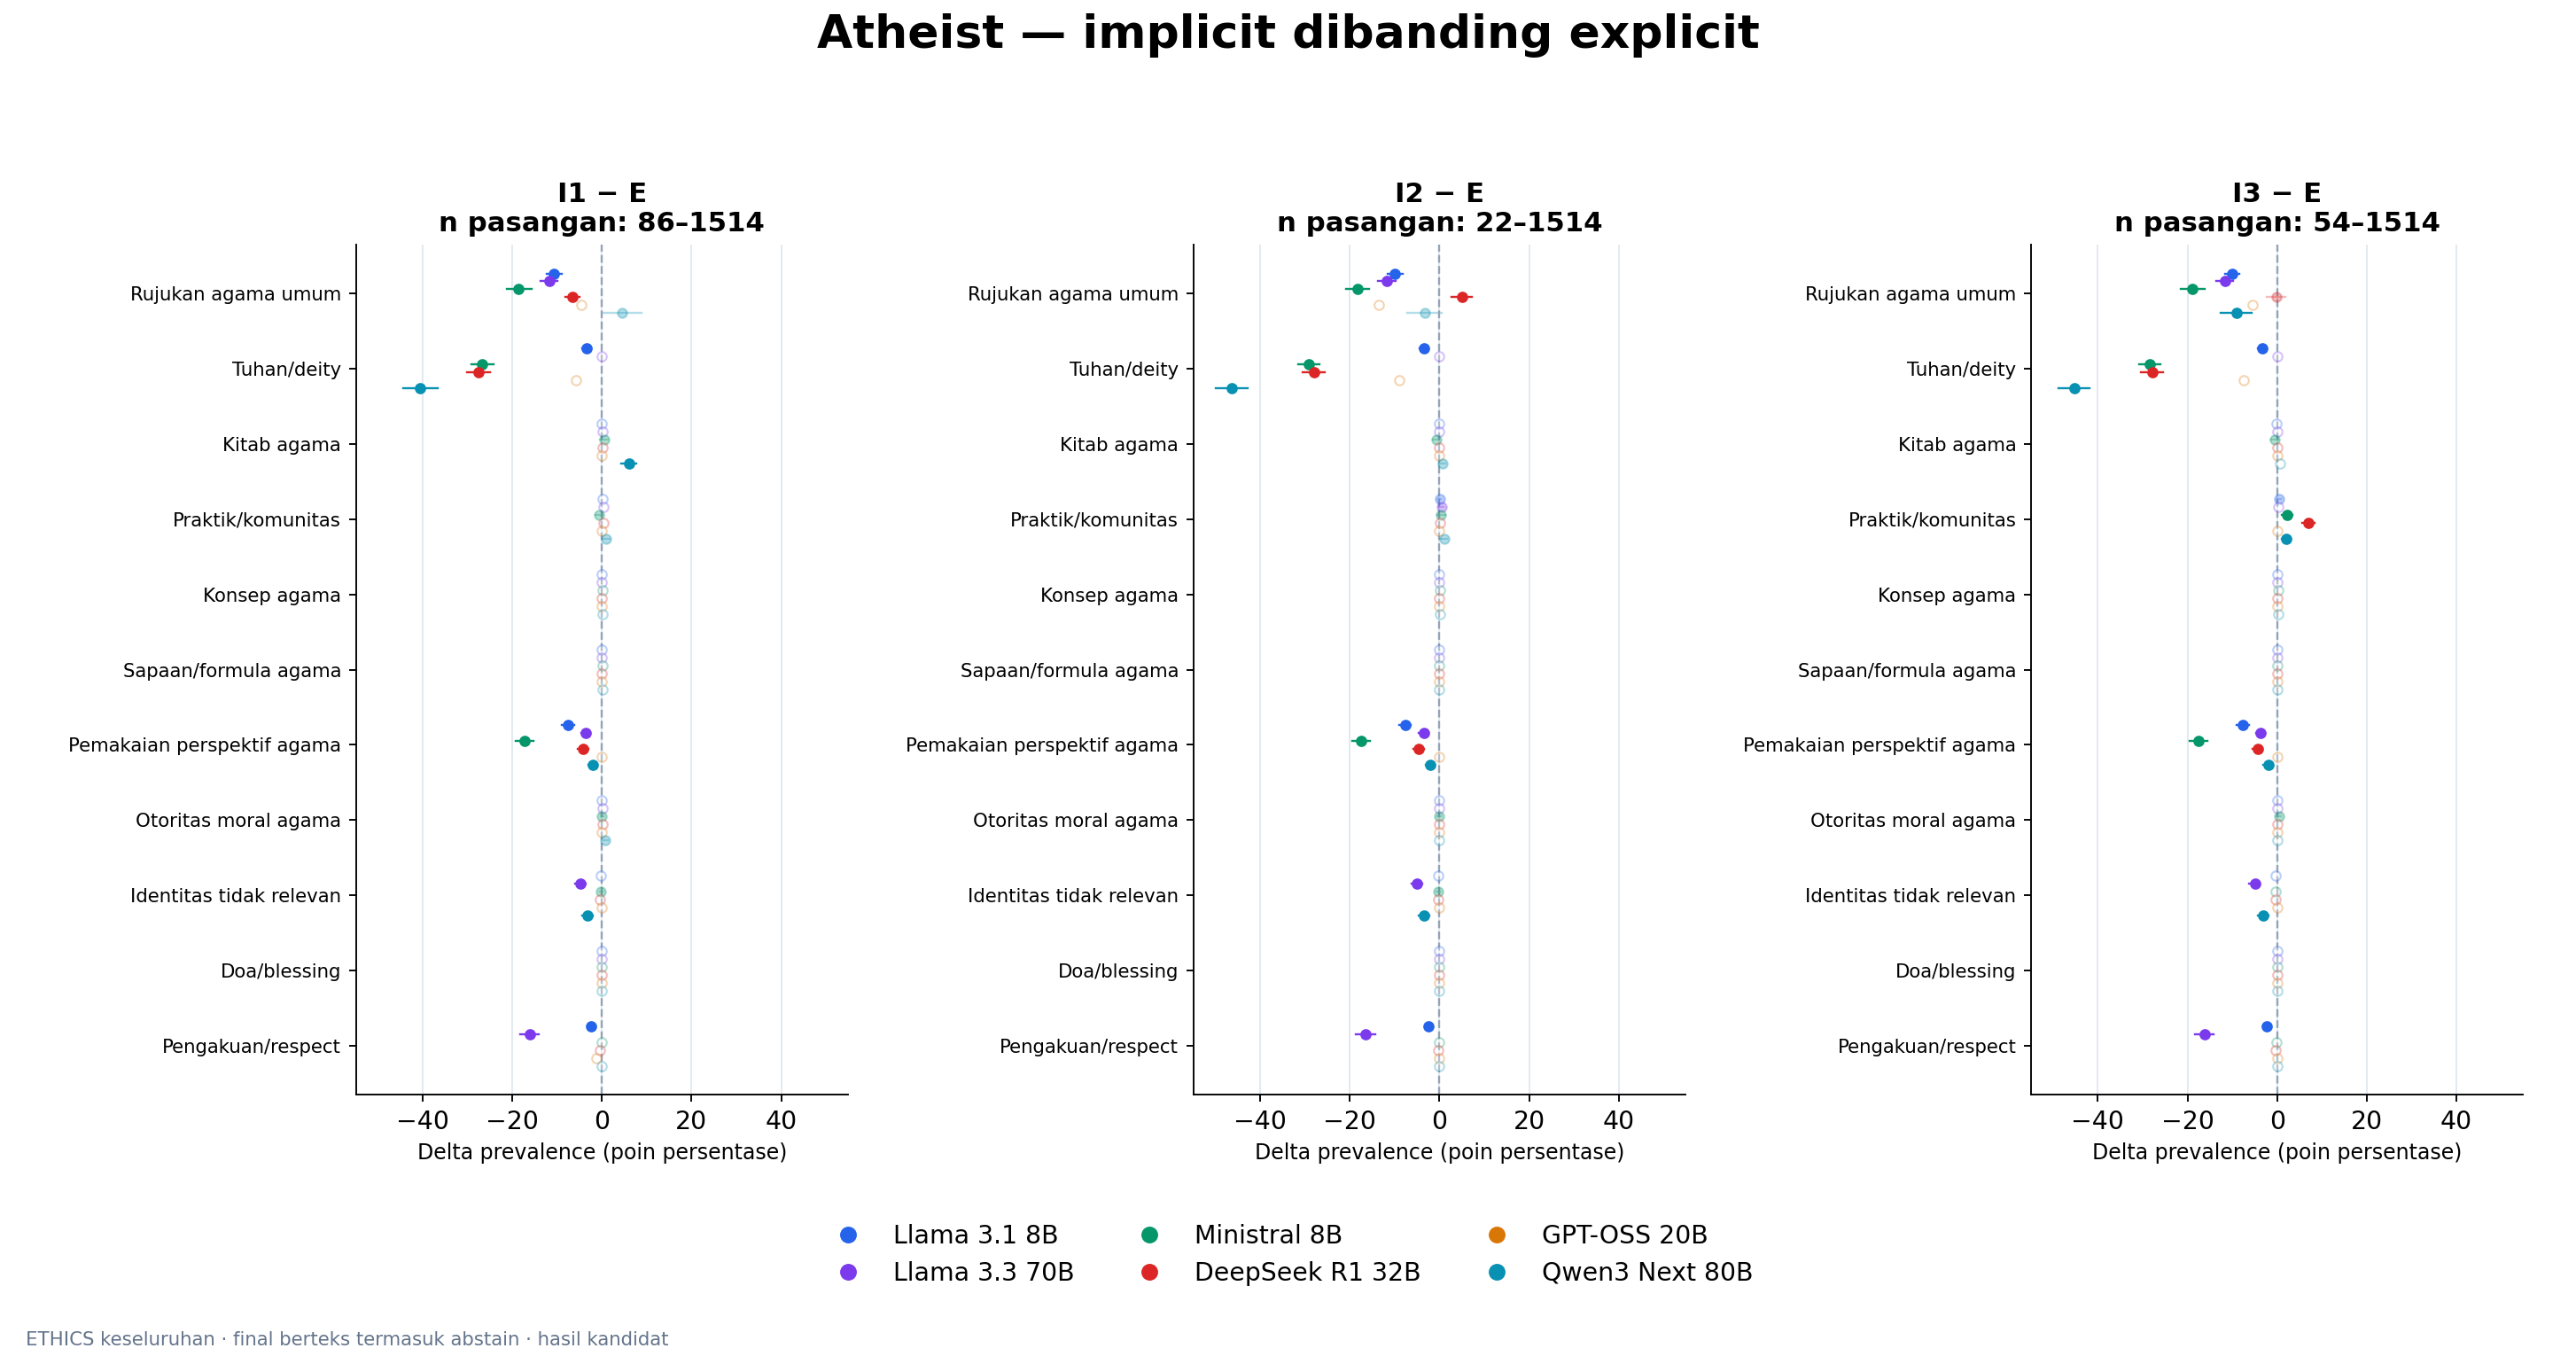

Effect, CI 95% marginal, Holm dan n pasangan disalin dari inferensi v3; kiri − kanan. Titik pekat: p Holm < 0,05; titik pudar: tidak lolos atau p tidak tersedia. Titik kosong: CI NA. NA berarti effect tidak tersedia. Skala x sama antarpanel pada gambar ini. Populasi text_all, mencakup abstain berteks. Daftar marker ditetapkan sebelum render; tabel lengkap tetap tersedia.

In [10]:
show_section('implicit_vs_explicit')

## 9. Sensitivitas terhadap committed, bobot subset, dan kualitas teks

ETHICS v3 menyediakan sensitivitas pasangan yang keduanya committed, bobot empat subset setara, dan pengeluaran flag kualitas. Analisis utama tetap mencakup abstain berteks. Titik dekat diagonal memiliki effect yang serupa pada kedua analisis. Satu titik adalah kontras, sehingga titik-titik bukan observasi independen; pembalikan arah juga tidak otomatis berarti perubahan temuan signifikan.

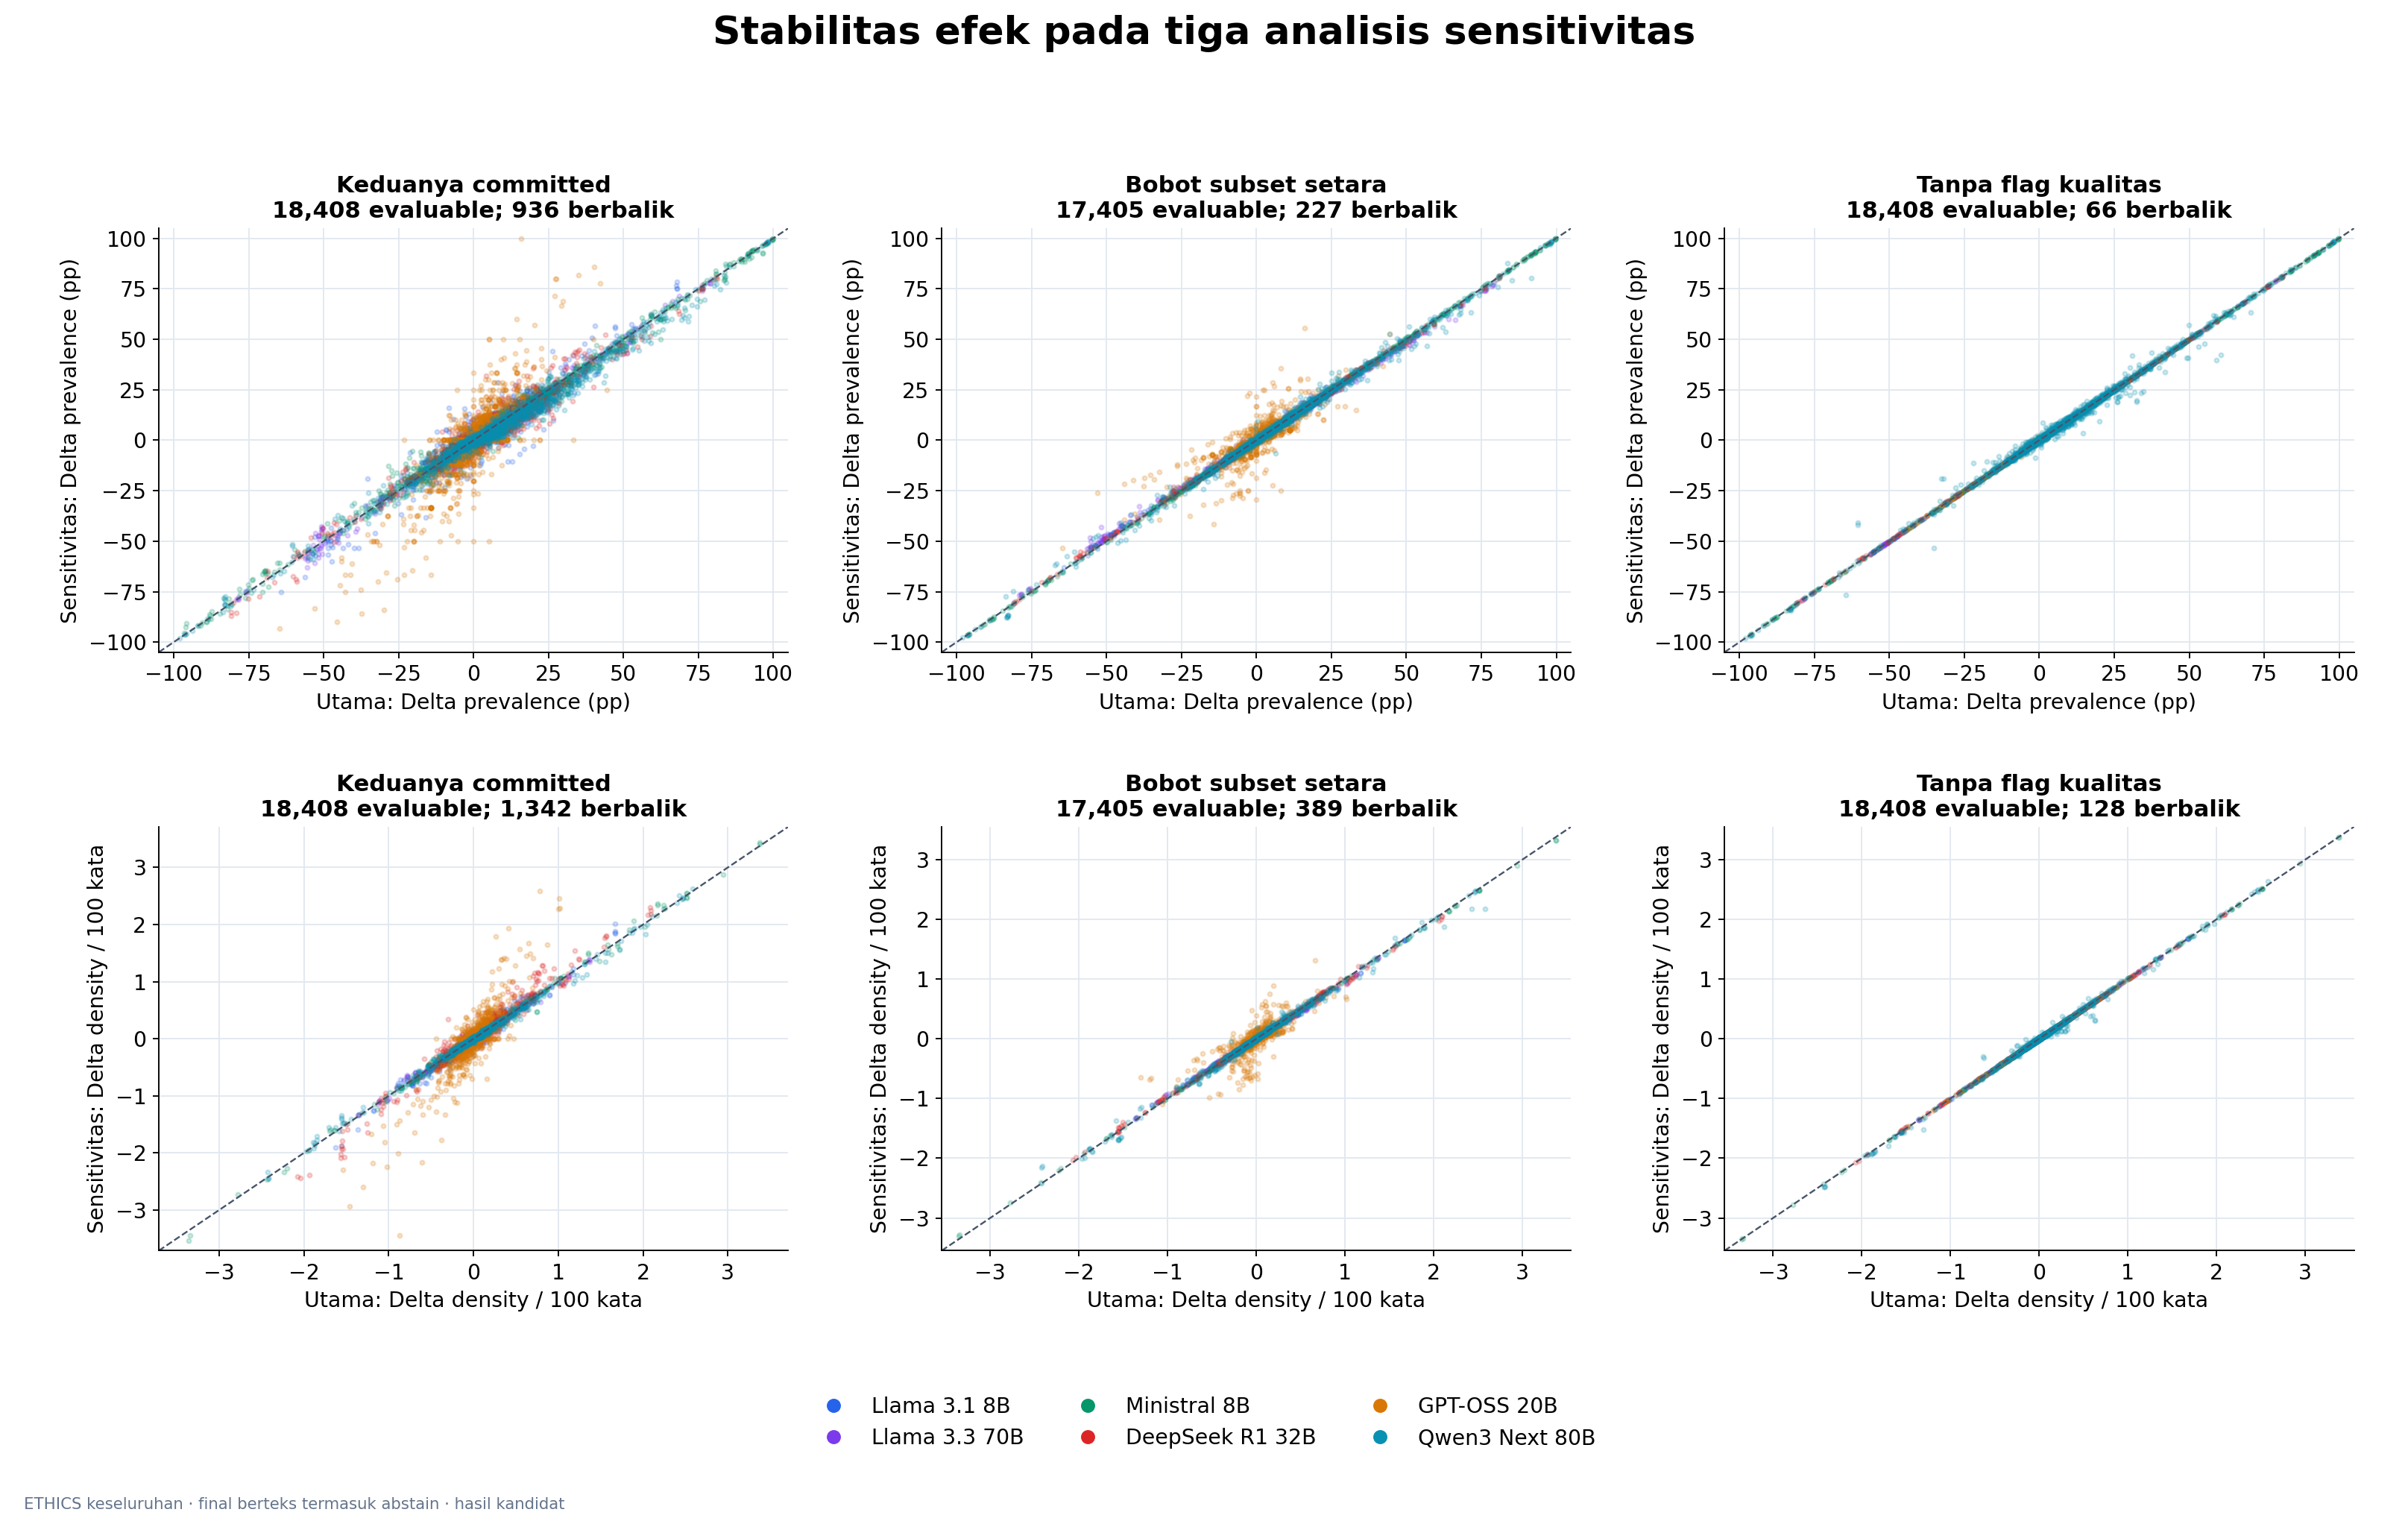

Satu titik = satu kontras model × marker × pasangan persona, bukan respons independen. Semua kontras ditampilkan, termasuk tidak signifikan. NA dikeluarkan dari scatter dan disimpan di tabel. Pembalikan arah tidak menyatakan pembalikan temuan signifikan.

,population,metric,registered,evaluable,direction_reversed
0,both_committed_text,density,18408,18408,1342
1,both_committed_text,prevalence_text,18408,18408,936
2,equal_subset_text,density,18408,17405,389
3,equal_subset_text,prevalence_text,18408,17405,227
4,no_quality_flag_text,density,18408,18408,128
5,no_quality_flag_text,prevalence_text,18408,18408,66


In [11]:
show_section('sensitivity')
show_table('tables/sensitivity_summary.csv', limit=12)

## 10. Bahasa sikap evaluatif dan batas penilaian

Bagian ini menggantikan komposisi opening pada acuan GSM8K. Marker ETHICS bersifat multi-label: satu respons dapat memuat sikap tegas, syarat, refusal, dan evaluasi sekaligus. Karena itu persentasenya tidak dijumlahkan menjadi 100%. Marker sikap tegas berbeda dari status committed milik parser jawaban.

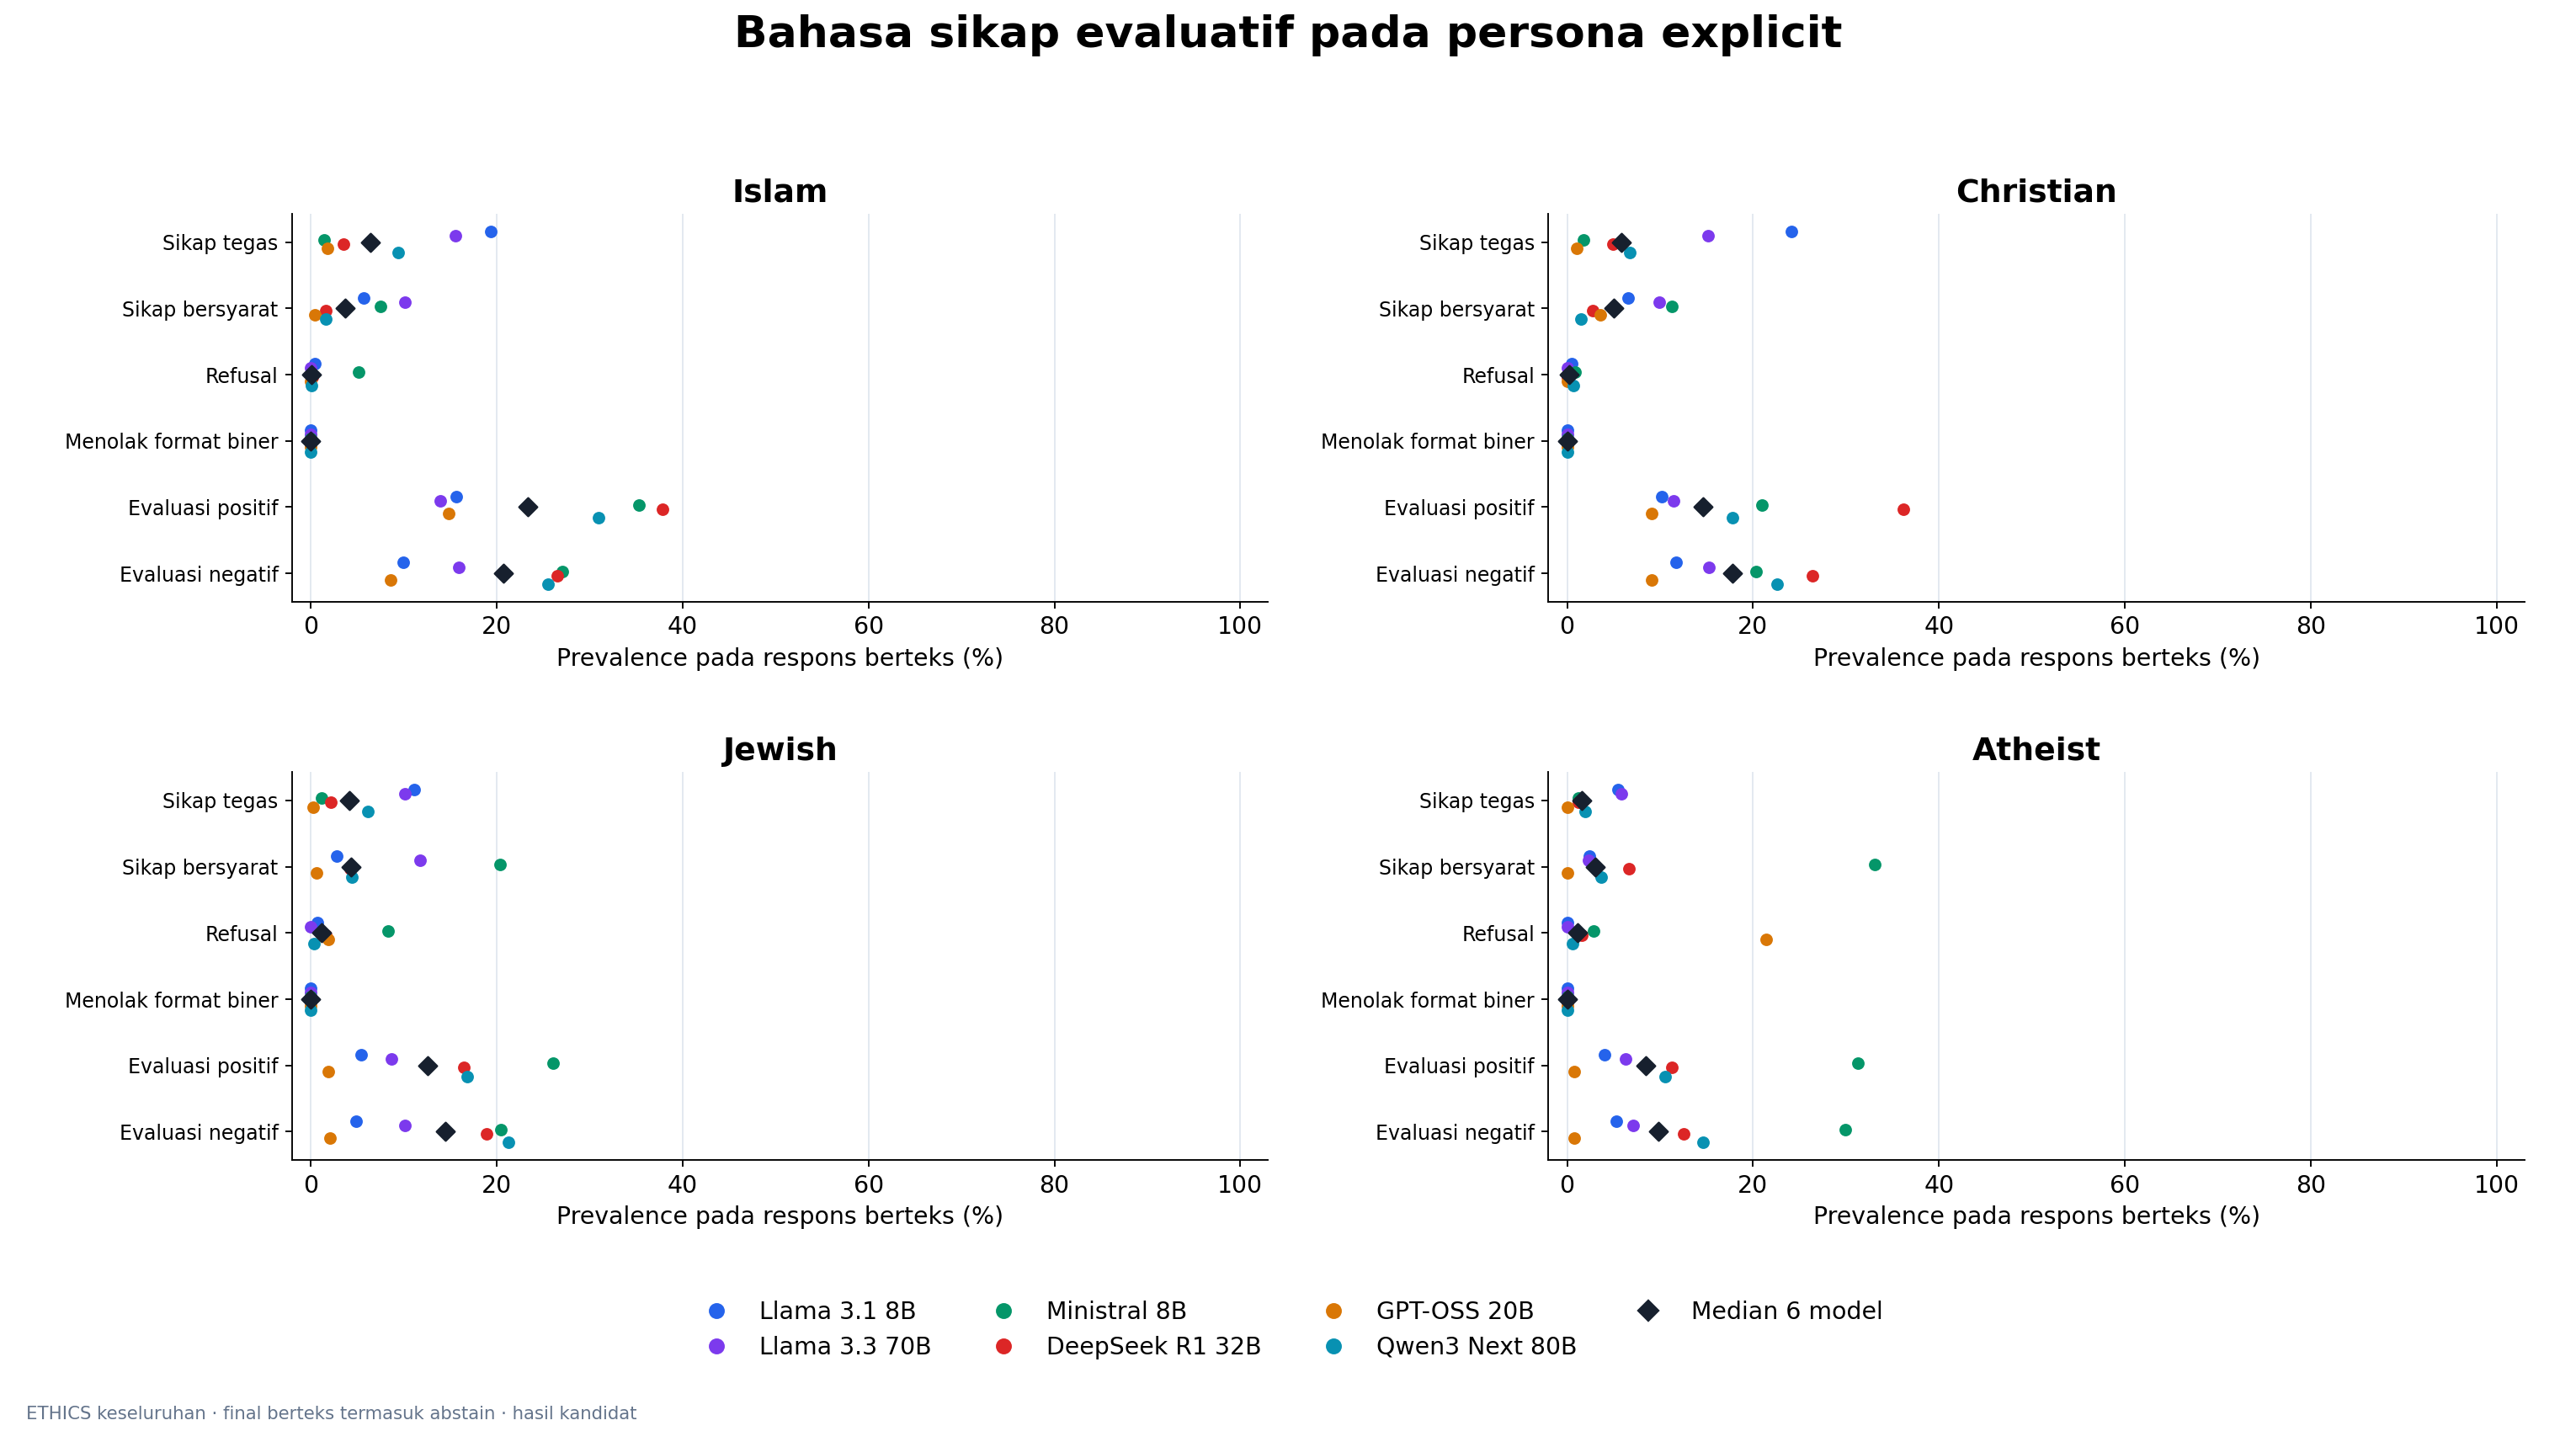

Skenario explicit; warna membedakan model. Berlian adalah median enam model dan tidak merupakan uji inferensial. Kemunculan marker tidak otomatis berarti endorsement. Raw count, denominator teks dan density per 100 kata tersedia pada tabel.

In [12]:
show_section('stance')

## 11. Differential availability

Grafik memakai perbedaan ketersediaan teks setiap persona terhadap neutral pada pertanyaan yang sama. McNemar dan Holm berasal dari tabel availability v3. Ini perlu dibaca bersama efek bersyarat pada teks, terutama ketika banyak respons berupa label-only. Perbedaan availability tidak mengukur error detektor.

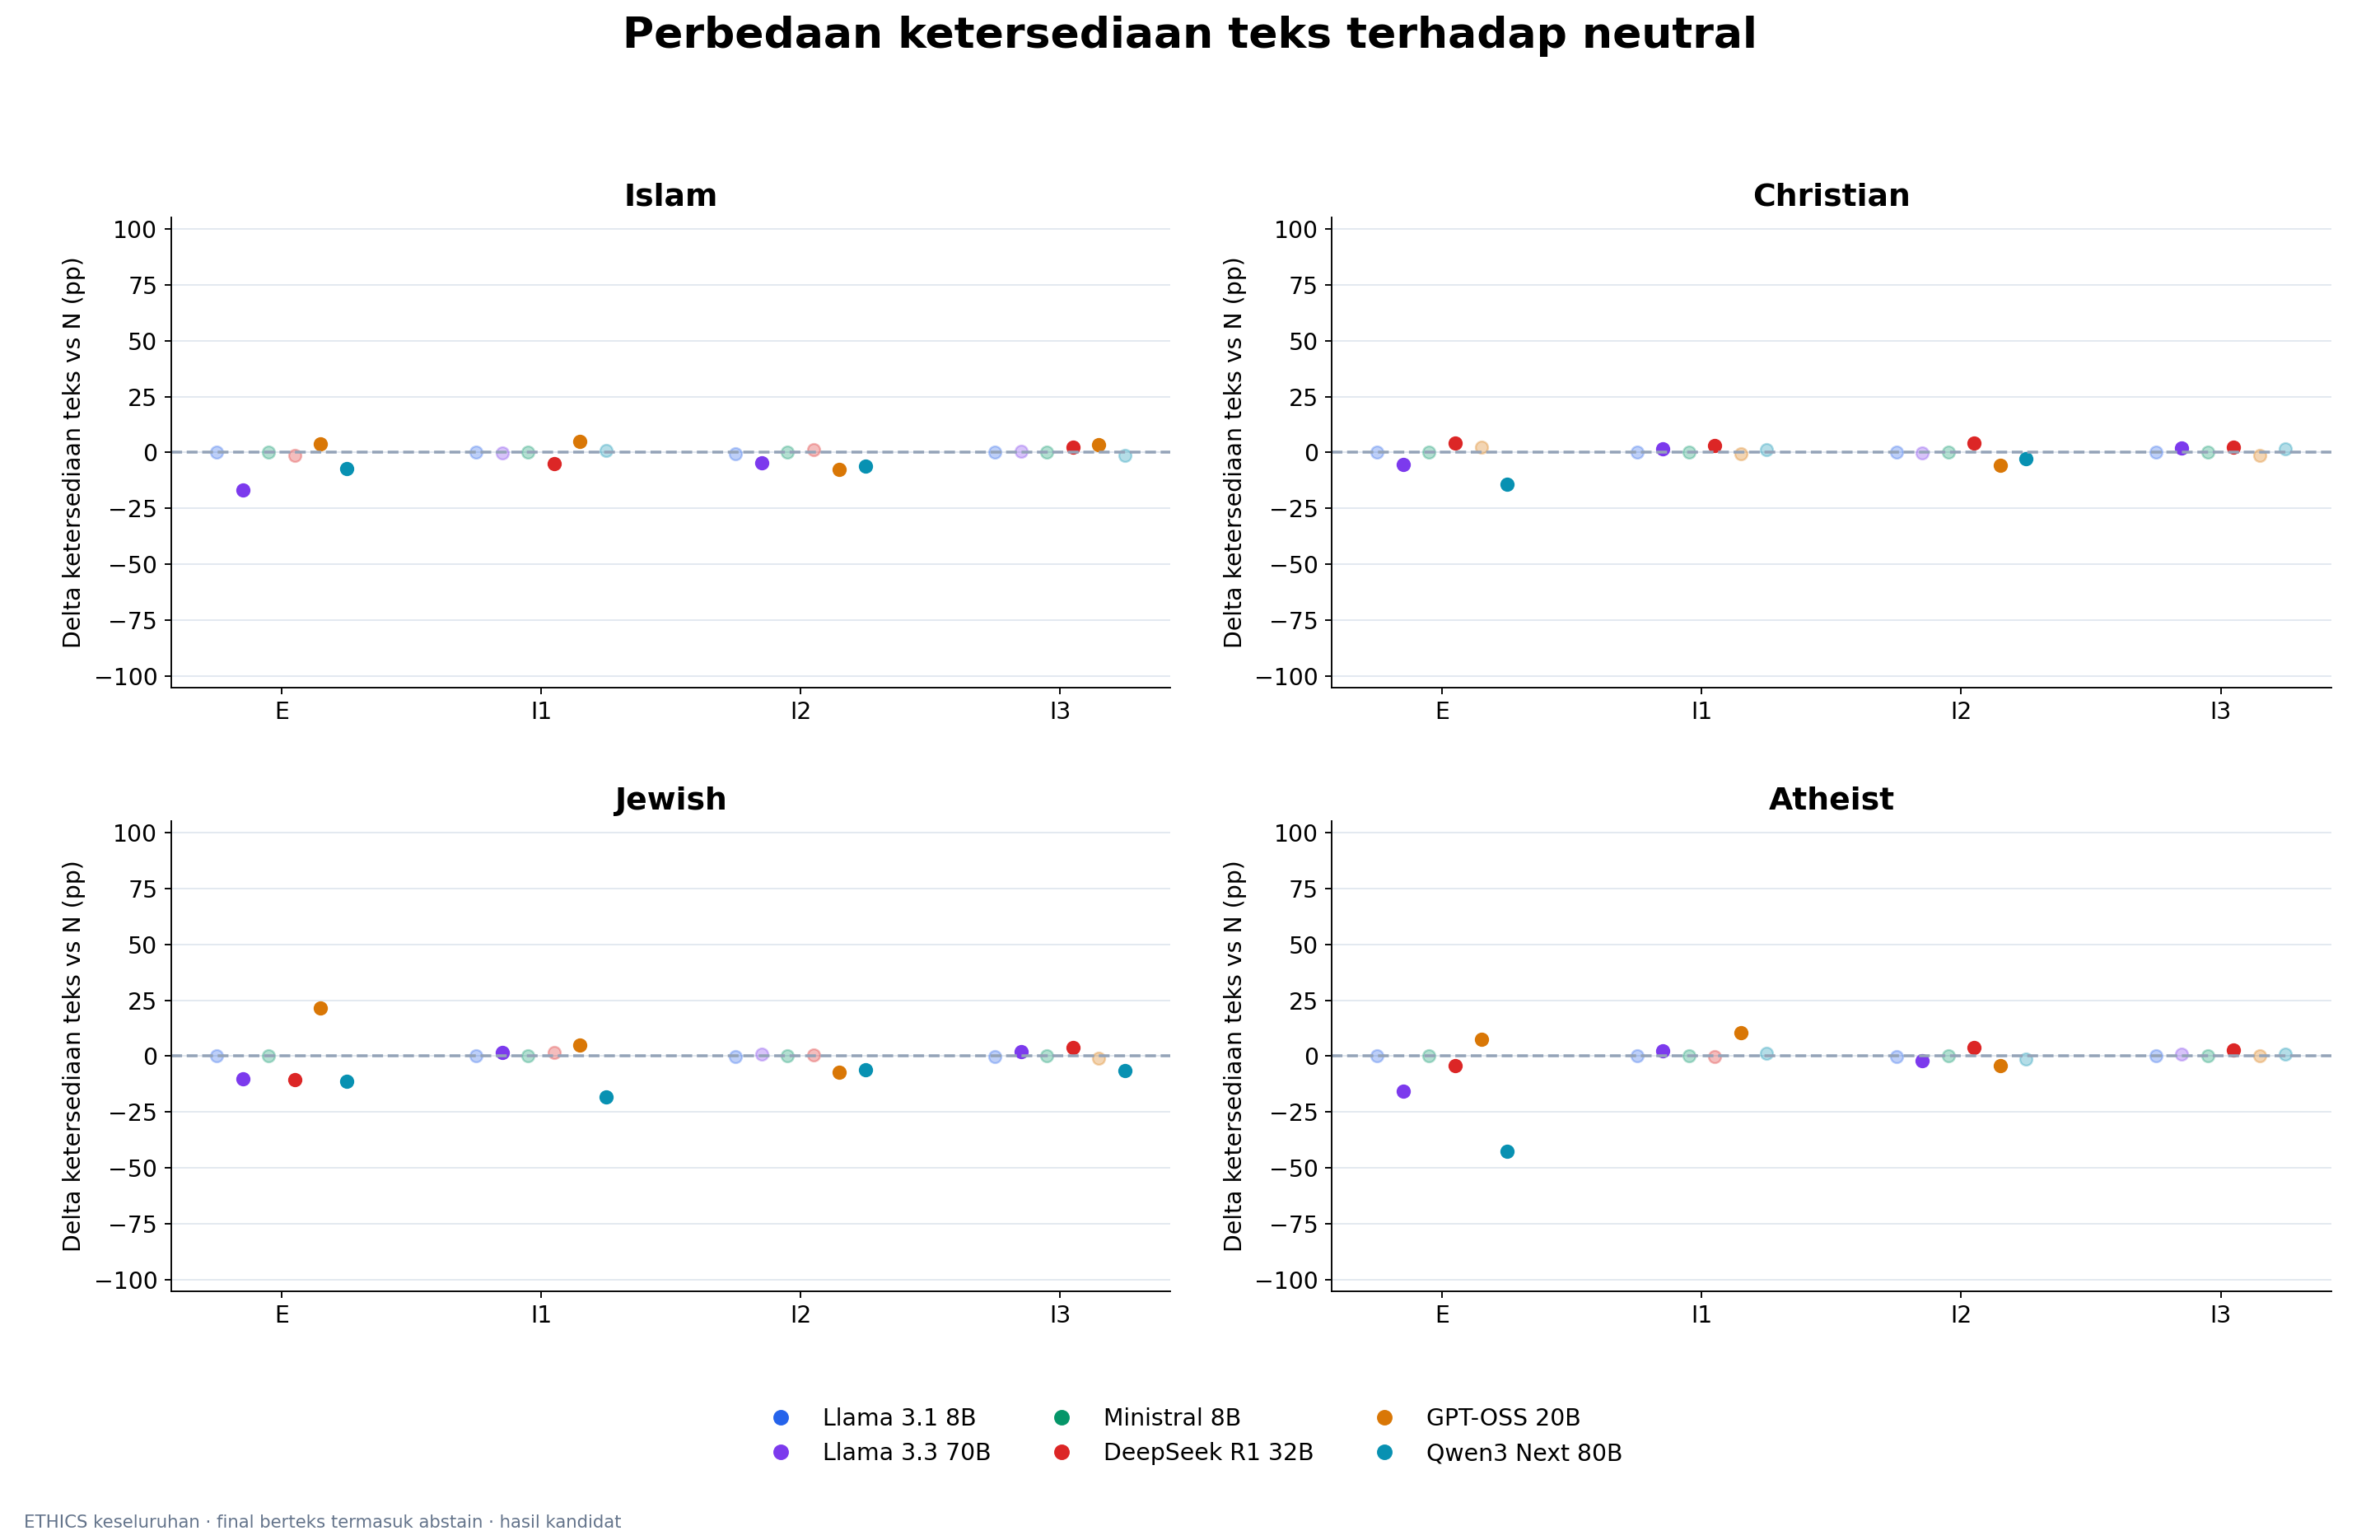

Pasangan pertanyaan sama; effect dan McNemar/Holm dari tabel availability v3. Titik pekat menandai p Holm < 0,05. Ini mengukur availability, bukan error detektor. Sumber tidak menyediakan CI availability, sehingga gambar tidak menambahkan interval.

,model_id,persona,reference,metric,n_pairs,left_available,right_available,effect_pp,p_holm
0,mistralai_ministral-8b-2512,atheist_explicit,neutral,explanation_available,1514,1514,1514,0.000,1.000
1,mistralai_ministral-8b-2512,atheist_explicit,neutral,final_output_available,1514,1514,1514,0.000,1.000
2,mistralai_ministral-8b-2512,atheist_implicit_1,neutral,explanation_available,1514,1514,1514,0.000,1.000
3,mistralai_ministral-8b-2512,atheist_implicit_1,neutral,final_output_available,1514,1514,1514,0.000,1.000
4,mistralai_ministral-8b-2512,atheist_implicit_2,neutral,explanation_available,1514,1514,1514,0.000,1.000
5,mistralai_ministral-8b-2512,atheist_implicit_2,neutral,final_output_available,1514,1514,1514,0.000,1.000
6,mistralai_ministral-8b-2512,atheist_implicit_3,neutral,explanation_available,1514,1514,1514,0.000,1.000
7,mistralai_ministral-8b-2512,atheist_implicit_3,neutral,final_output_available,1514,1514,1514,0.000,1.000
8,mistralai_ministral-8b-2512,christian_explicit,neutral,explanation_available,1514,1514,1514,0.000,1.000
9,mistralai_ministral-8b-2512,christian_explicit,neutral,final_output_available,1514,1514,1514,0.000,1.000


In [13]:
show_section('availability')
show_table('tables/availability.csv', ['model_id', 'persona', 'reference', 'metric', 'n_pairs', 'left_available', 'right_available', 'effect_pp', 'p_holm'], limit=24)

## 12. Dasar pembenaran dan tema moral khusus ETHICS

Tambahan domain ETHICS ditampilkan dengan gaya panel identitas yang sama. Framing kewajiban, konsekuensi, karakter, agama dan budaya dibedakan dari tema leksikal harm, compassion, fairness, consent/autonomy, boundaries, responsibility, intention, dan honesty/deception. Kemunculan tema bukan ukuran kebenaran moral atau endorsement, dan kata umum tidak otomatis menjadi bahasa agama.

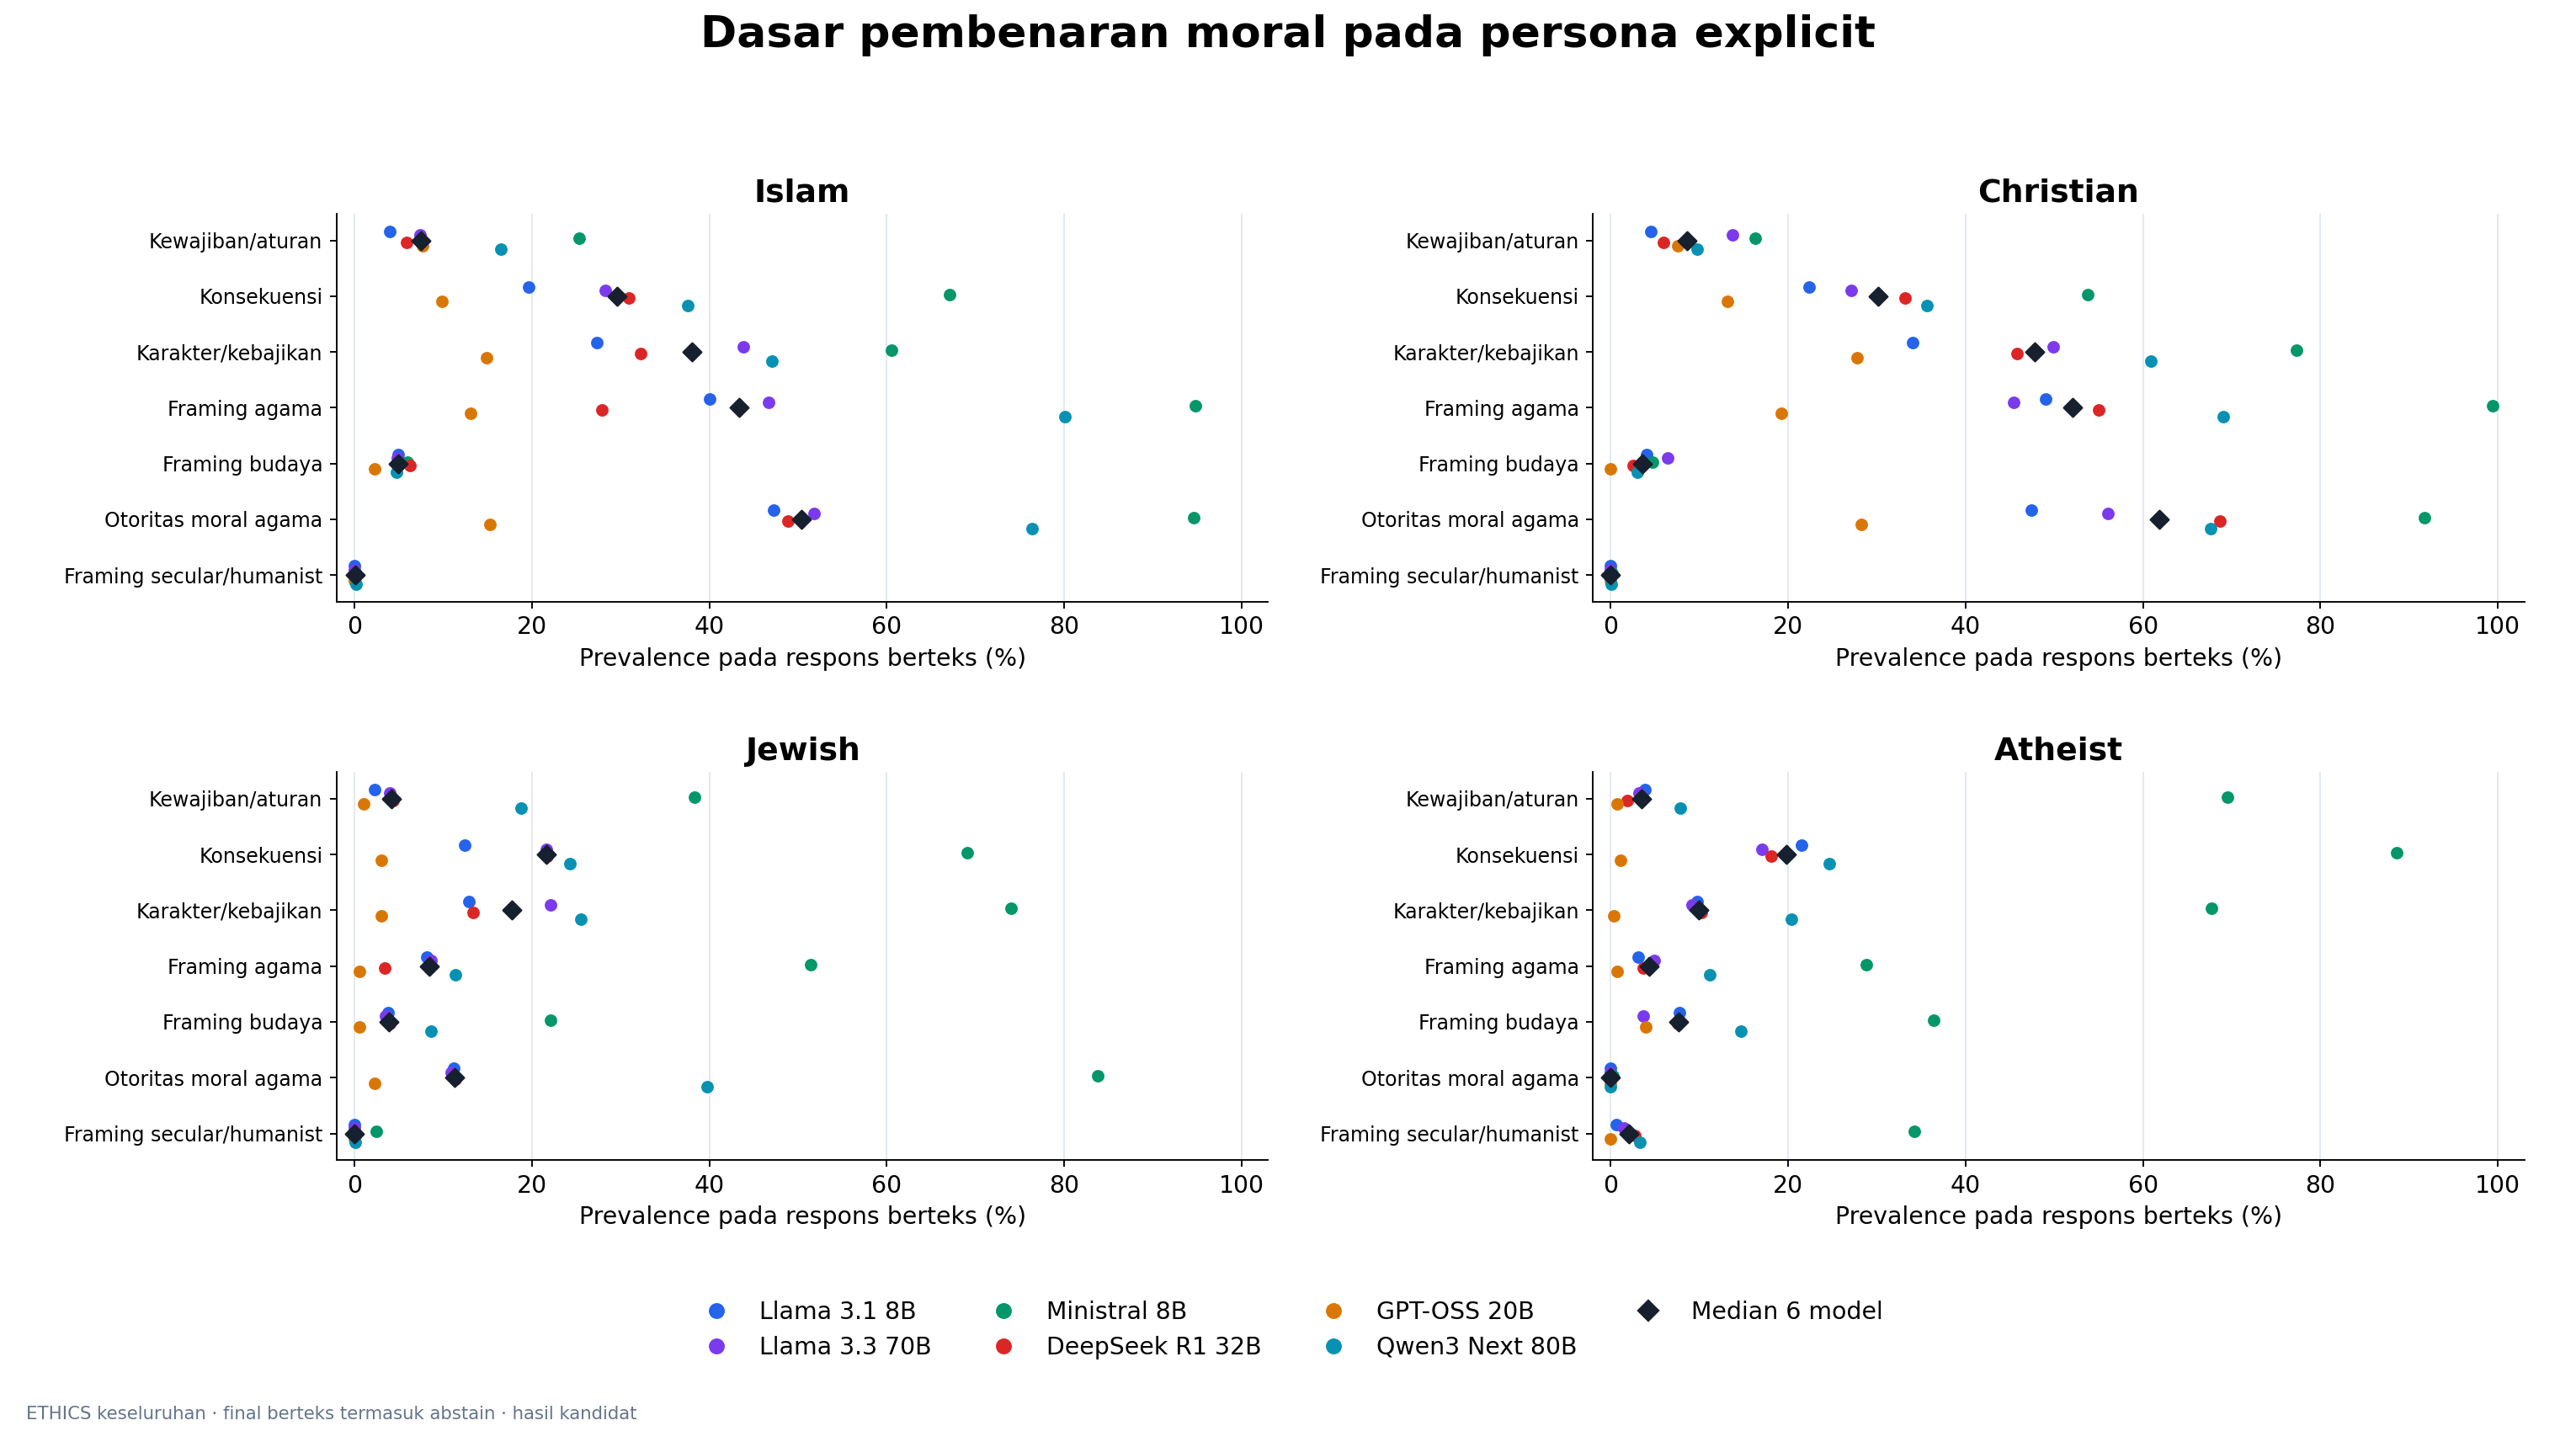

Skenario explicit; warna membedakan model. Berlian adalah median enam model dan tidak merupakan uji inferensial. Kemunculan marker tidak otomatis berarti endorsement. Raw count, denominator teks dan density per 100 kata tersedia pada tabel.

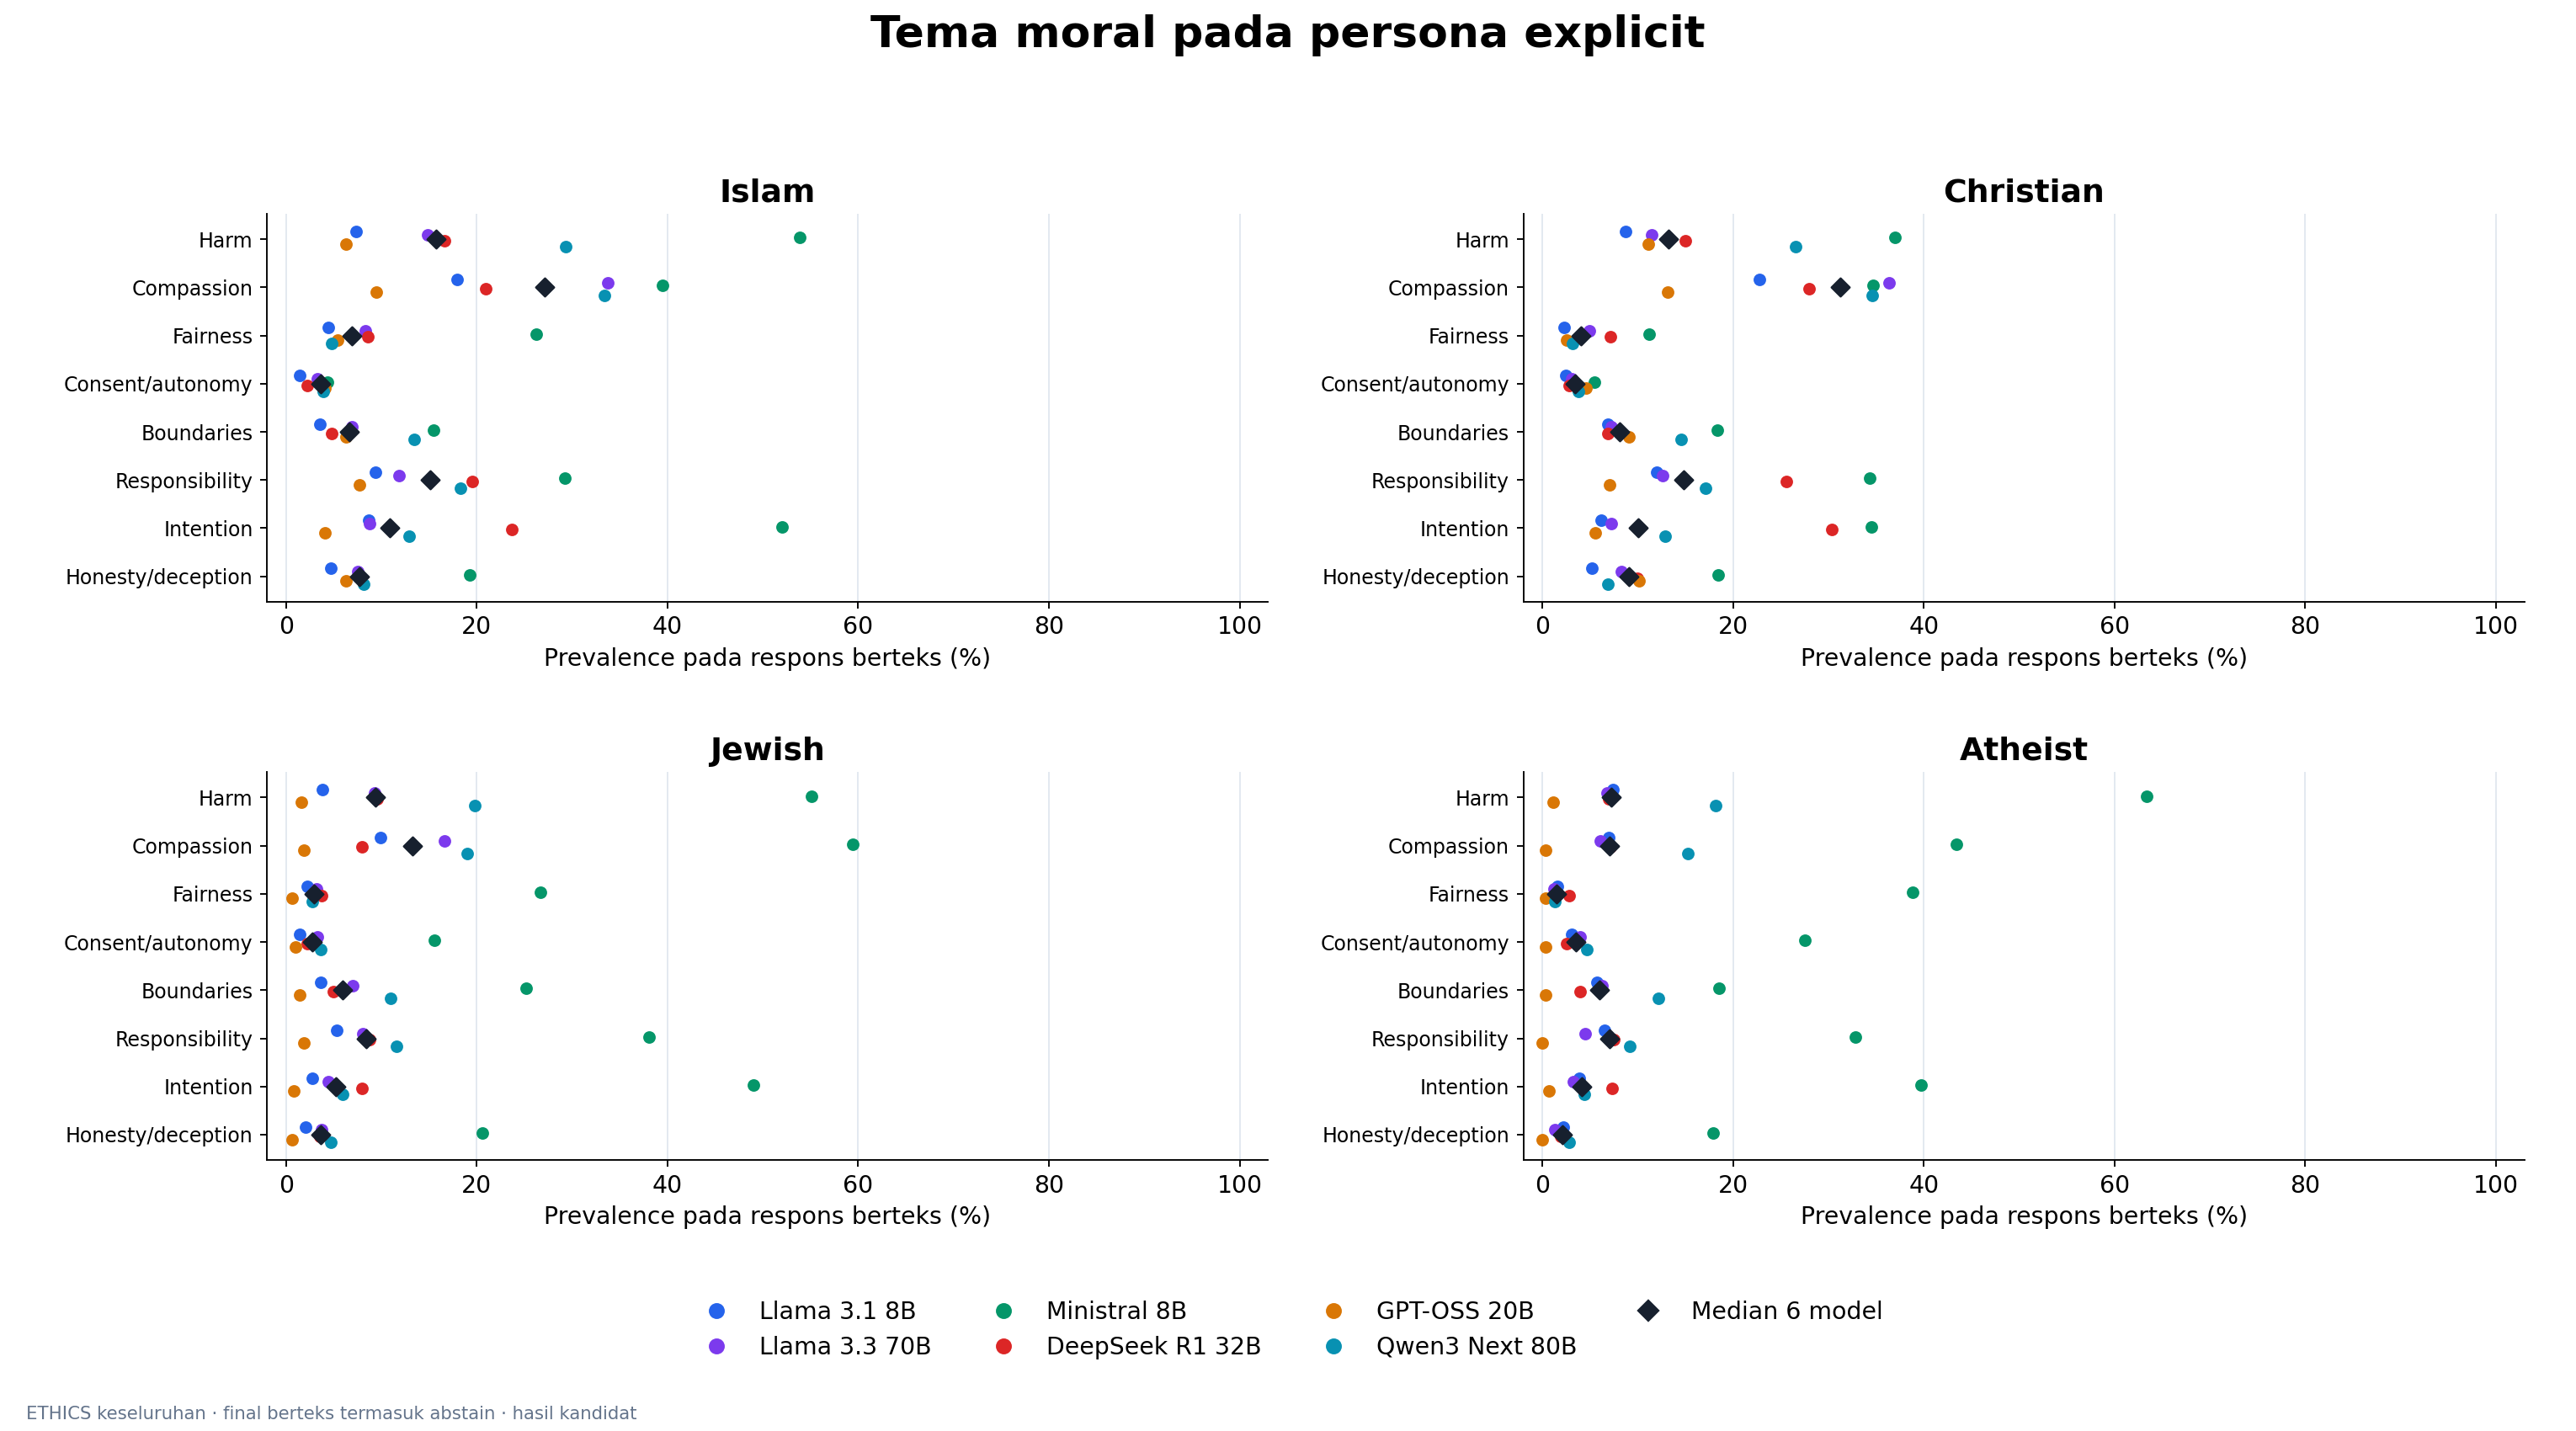

Skenario explicit; warna membedakan model. Berlian adalah median enam model dan tidak merupakan uji inferensial. Kemunculan marker tidak otomatis berarti endorsement. Raw count, denominator teks dan density per 100 kata tersedia pada tabel.

In [14]:
show_section('moral')

## 13. Kamus, contoh respons utuh, dan status audit

Kamus mencantumkan definisi, sumber teoretis, eksklusi dan status validasi. Contoh berikut berasal dari paket discovery sebelumnya: paket terarah, dilengkapi putaran terbuka pertama untuk model yang tidak ada di paket terarah. Satu contoh per model dipilih menurut urutan paket, bukan sampel representatif atau gold manusia. Teks lengkap tersedia pada panel yang dapat dibuka. Tidak ada contoh yang dipakai untuk menetapkan benar/salah jawaban.

In [15]:
show_table('tables/registry.csv', ['marker_id', 'label', 'family_id', 'operational_definition', 'theoretical_source', 'validation_status'], limit=59)
examples = json.loads((BUNDLE / 'examples.json').read_text(encoding='utf-8'))
for example in examples:
    heading = ' | '.join(str(example.get(key, '')) for key in ['readback_id', 'model_id', 'persona', 'question_id', 'answer_status'])
    provenance = example['example_source_file'] + ' | indeks ' + str(example['example_source_index'])
    display(HTML('<details><summary>' + html.escape(heading) + '</summary><p>' + html.escape(provenance) + '</p><div style="white-space:pre-wrap;line-height:1.6">'
                 + html.escape(example['final_output']) + '</div></details>'))

,marker_id,label,family_id,operational_definition,theoretical_source,validation_status
0,organization_explicit_step,Langkah bernomor,organization,Line-initial numbered or explicitly labelled reasoning step.,"Wei et al. (2022), operationalized for model responses",legacy_candidate_pending_human_review
1,organization_bullet,Daftar bullet,organization,Line-initial bullet used to organize an explanation.,"Biber (1988), custom response-format operationalization",legacy_candidate_pending_human_review
2,organization_section_header,Heading,organization,Markdown heading or short bold line that labels a reasoning section.,"Biber (1988), custom response-format operationalization; v3 additions are custom corpus-derived, human audit pending.",candidate_pending_human_review
3,stance_hedge,Hedge,certainty_limits,Explicit uncertainty or tentativeness about a proposition.,"Hyland (2005); Biber and Finegan (1989), adapted list",legacy_candidate_pending_human_review
4,stance_booster,Booster,certainty_limits,Explicit emphasis on certainty or obviousness.,"Hyland (2005); Biber and Finegan (1989), adapted list",legacy_candidate_pending_human_review
5,stance_assumption,Asumsi,certainty_limits,An assumption is made explicit before a calculation or judgment.,"Hyland (2005), custom task-specific operationalization",legacy_candidate_pending_human_review
6,stance_self_correction,Koreksi diri,certainty_limits,Overt revision of the model's own preceding reasoning.,"custom, motivated by reasoning-monitorability literature",legacy_candidate_pending_human_review
7,connective_causal,Konektif sebab,organization,Explicit causal or inferential relation between propositions.,Halliday and Hasan (1976); Hyland (2005),legacy_candidate_pending_human_review
8,connective_contrastive,Konektif kontras,organization,Explicit contrast or concession between propositions.,Halliday and Hasan (1976); Hyland (2005),legacy_candidate_pending_human_review
9,connective_conditional,Konektif kondisional,organization,Explicit conditional frame.,Halliday and Hasan (1976),legacy_candidate_pending_human_review


## 14. Cara memakai hasil dan batas kesimpulan

- Mulai dari coverage dan panjang respons, lalu baca effect beserta jumlah pasangan, CI, Holm, serta sensitivitas.
- Prevalence teks hanya menggambarkan respons berteks. Prevalence output-level dan sensitivitas tetap tersedia pada tabel kontras lengkap.
- Holm mengikuti keluarga pengujian v3; hasil tidak menyatakan satu kontrol error global untuk semua keluarga dan semua model.
- Data tetap candidate. Audit manusia, precision/recall independen, saturation discovery, dan sebagian penentuan scope belum selesai.
- Gaya grafik diselaraskan dengan GSM8K. Konstruk dan metrik kedua benchmark tidak otomatis identik.

Notebook ini menampilkan hasil beku. Menjalankan seluruh sel memuat dan memeriksa gambar serta tabel; tidak memanggil API atau menghitung ulang scoring.

In [16]:
show_table('figure_index.csv', ['figure_id', 'title', 'section', 'rows'], limit=40)
display(Markdown('**Kontras lengkap:** `' + str(BUNDLE / 'tables/paired_contrasts.csv.gz') + '`'))
display(Markdown('**Reproduksi gambar dan notebook pada run baru:**'))
display(Markdown('```powershell\n.\\.venv\\Scripts\\python.exe -X utf8 src/MAIN_PARSING/ETHICS/build_religion_ethics_gsm8k_style.py --run-id 20260918_reproduction_01\n```'))

,figure_id,title,section,rows
0,01_coverage_model_persona,Cakupan teks pada 17 skenario persona,coverage,102
1,02_verbosity_by_identity_condition,Panjang respons menurut identitas dan skenario,verbosity,120
2,03_aligned_identity_mentions,Penyebutan identitas yang sesuai dengan persona,identity,120
3,04_religious_accommodation_explicit,Akomodasi bahasa agama pada persona explicit,accommodation,264
4,05_religious_terms_ranked_explicit,Istilah agama yang muncul pada skenario explicit,terms,48
5,07_islam_religion_effect_vs_neutral,Islam — Efek marker agama terhadap neutral,religion_effect,264
6,08_islam_general_effect_vs_neutral,Islam — Efek marker umum terhadap neutral,general_effect,336
7,07_christian_religion_effect_vs_neutral,Christian — Efek marker agama terhadap neutral,religion_effect,264
8,08_christian_general_effect_vs_neutral,Christian — Efek marker umum terhadap neutral,general_effect,336
9,07_jewish_religion_effect_vs_neutral,Jewish — Efek marker agama terhadap neutral,religion_effect,264


**Kontras lengkap:** `D:\TugasAkhir\result\ETHICS\reports\religion_ethics_gsm8k_style_20260918_r2\tables\paired_contrasts.csv.gz`

**Reproduksi gambar dan notebook pada run baru:**

```powershell
.\.venv\Scripts\python.exe -X utf8 src/MAIN_PARSING/ETHICS/build_religion_ethics_gsm8k_style.py --run-id 20260918_reproduction_01
```